# Trabalho Final — MovieLens 25M

## Roteiro segundo o processo KDD

O notebook segue o processo KDD (Fayyad et al., 1996):

**Dados → Seleção → dados-alvo → Pré-processamento → dados pré-processados → Transformação → dados transformados → Mineração → padrões → Interpretação/Avaliação → conhecimento.**

O processo é iterativo: um resultado pode exigir retorno a uma etapa anterior. A qualidade dos dados de entrada limita a qualidade dos padrões obtidos.

| Etapa | O que é feito aqui |
|---|---|
| 0. Problema e tarefa | P1 = agrupamento de usuários; P2 = associação; P2 depende de P1; não há classe/meta |
| 1. Seleção | fontes, grão, instância × atributos, tipos e domínios; exploração univariada com histogramas de todos os atributos (média e DP marcados), consultas por gênero, por objeto e com filtro, e exploração multivariada com atributos em escala [0, 1] **sobre os dados-alvo, antes de qualquer tratamento** |
| 2. Pré-processamento | qualidade (completude, unicidade, validade, integridade), limpeza, imputação do gênero dos filmes sem gênero, integração das tabelas, amostragem, valores ausentes e distribuições depois do tratamento |
| 3. Transformação | perfil por usuário em proporções, seleção de características, normalização, PCA, concentração de distâncias, dimensionalidade intrínseca, visualização, valores atípicos, tendência de agrupamento, vetor revisado com atributos derivados e solução indexada |

Esta versão vai até a etapa 3 (Transformação). A mineração (P1 e P2) e a interpretação ficam para a versão seguinte.

> **Cinco grupos de nota:** 0,5 e 1,0 → grupo 1; 1,5 e 2,0 → 2; 2,5 e 3,0 → 3; 3,5 e 4,0 → 4; 4,5 e 5,0 → 5. Histogramas e resumos mostram média e desvio-padrão, e cada proporção declara seu denominador.

**Execução:** notebook executado integralmente no Google Colab em 18/11/2026, em segundo plano com `jupyter nbconvert` na máquina do Colab, com as 43 células de código concluídas sem erro. Os dados são o MovieLens 25M, obtido de uma cópia hospedada no Hugging Face; as contagens conferem com a documentação oficial (25.000.095 avaliações, 162.541 usuários, 62.423 filmes).

## 0. Problema e tarefa de mineração

- **P1 — perfis de usuários:** tarefa de agrupamento (aprendizado não supervisionado). A instância analítica é o usuário.
- **P2 — padrões frequentes:** tarefa de associação. A transação é o usuário e os itens são filmes avaliados positivamente. P2 é construída a partir do resultado de P1.
- **Sem classe/meta:** o MovieLens não traz um atributo-alvo. Por isso, a classificação e os filtros de seleção de características que dependem de classe (CFS, Fisher e ReliefF em sua forma completa) não se aplicam diretamente antes de P1.
- **População:** 162.541 usuários anônimos, todos com pelo menos 20 avaliações, entre 1995 e 2019, sem dados demográficos. Os perfis descrevem comportamento observado de avaliação, não características pessoais.

## 1. Seleção de dados

A seleção define os **dados-alvo** e os conhece antes de qualquer tratamento: estrutura de instâncias e atributos, tipos e domínios, e exploração preliminar com estatísticas descritivas e visualização. A exploração é feita sobre as tabelas como foram carregadas, porque ela orienta a escolha do pré-processamento e do método de aprendizado.

### 1.1 Obtenção e carregamento

In [1]:
# [1.1-a] Obtenção dos arquivos do MovieLens 25M (cópia local ou espelho documentado)
from pathlib import Path
import importlib.util, subprocess, sys
for pacote in ('pyspark', 'huggingface_hub', 'matplotlib', 'pandas'):
    if importlib.util.find_spec(pacote) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pacote])
DATA_DIR = Path('ml-25m')
arquivos = ['movies.csv', 'ratings.csv', 'tags.csv', 'links.csv']
if not all((DATA_DIR / nome).is_file() for nome in arquivos):
    from huggingface_hub import hf_hub_download
    raiz = Path('movielens_mirror')
    DATA_DIR = raiz / 'movielens_25m' / 'ml-25m'
    for nome in arquivos:
        hf_hub_download(repo_id='cephcyn/2026_01_22_datasets', repo_type='dataset', filename=f'movielens_25m/ml-25m/{nome}', local_dir=str(raiz))
assert all((DATA_DIR / nome).is_file() for nome in arquivos)
print('MovieLens 25M:', DATA_DIR.resolve())

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


MovieLens 25M: /content/movielens_mirror/movielens_25m/ml-25m


In [2]:
# [1.1-b] SparkSession e importações
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from pyspark.sql.types import (
    StructType, StructField, IntegerType,
    LongType, DoubleType, StringType
)

spark = (
    SparkSession.builder
    .appName("MovieLensKDD")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.shuffle.partitions", "200")
    .config("spark.sql.session.timeZone", "UTC")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")
print("Spark inicializado:", spark.version)

Spark inicializado: 4.0.5


In [3]:
# [1.1-c] Carregamento com esquemas explícitos
movies_schema = StructType([
    StructField("movieId", IntegerType(), True),
    StructField("title", StringType(), True),
    StructField("genres", StringType(), True),
])

ratings_schema = StructType([
    StructField("userId", IntegerType(), True),
    StructField("movieId", IntegerType(), True),
    StructField("rating", DoubleType(), True),
    StructField("timestamp", LongType(), True),
])

tags_schema = StructType([
    StructField("userId", IntegerType(), True),
    StructField("movieId", IntegerType(), True),
    StructField("tag", StringType(), True),
    StructField("timestamp", LongType(), True),
])

links_schema = StructType([
    StructField("movieId", IntegerType(), True),
    StructField("imdbId", LongType(), True),
    StructField("tmdbId", LongType(), True),
])

movies_df = spark.read.csv(str(DATA_DIR / "movies.csv"), header=True, schema=movies_schema)
ratings_df = spark.read.csv(str(DATA_DIR / "ratings.csv"), header=True, schema=ratings_schema)
tags_df = spark.read.csv(str(DATA_DIR / "tags.csv"), header=True, schema=tags_schema)
links_df = spark.read.csv(str(DATA_DIR / "links.csv"), header=True, schema=links_schema)

datasets = {
    "movies": movies_df,
    "ratings": ratings_df,
    "tags": tags_df,
    "links": links_df,
}

print("Tabelas carregadas:", ", ".join(datasets))

Tabelas carregadas: movies, ratings, tags, links


### 1.2 Estrutura: tabelas, instâncias, atributos e grão

O MovieLens é relacional. Para a mineração, os dados precisam ser representados como uma tabela de instâncias (linhas) e atributos (colunas). Por isso, primeiro se registra o grão de cada tabela e depois se monta a visão usada na exploração (1.4).

In [4]:
# [1.2] Estrutura das tabelas: linhas, colunas, esquemas e exemplos
for nome, df in datasets.items():
    df.createOrReplaceTempView(f"{nome}_raw")
    df.createOrReplaceTempView(nome)

perfil_tabelas = []
for nome, df in datasets.items():
    total_linhas = df.count()
    perfil_tabelas.append((nome, total_linhas, len(df.columns)))

perfil_df = spark.createDataFrame(
    perfil_tabelas,
    ["tabela", "linhas", "colunas"]
)

perfil_df.orderBy("tabela").show(truncate=False)

for nome, df in datasets.items():
    print(f"\n--- {nome.upper()} ---")
    df.printSchema()
    df.show(3, truncate=False)

+-------+--------+-------+
|tabela |linhas  |colunas|
+-------+--------+-------+
|links  |62423   |3      |
|movies |62423   |3      |
|ratings|25000095|4      |
|tags   |1093360 |4      |
+-------+--------+-------+


--- MOVIES ---
root
 |-- movieId: integer (nullable = true)
 |-- title: string (nullable = true)
 |-- genres: string (nullable = true)



+-------+-----------------------+-------------------------------------------+
|movieId|title                  |genres                                     |
+-------+-----------------------+-------------------------------------------+
|1      |Toy Story (1995)       |Adventure|Animation|Children|Comedy|Fantasy|
|2      |Jumanji (1995)         |Adventure|Children|Fantasy                 |
|3      |Grumpier Old Men (1995)|Comedy|Romance                             |
+-------+-----------------------+-------------------------------------------+
only showing top 3 rows

--- RATINGS ---
root
 |-- userId: integer (nullable = true)
 |-- movieId: integer (nullable = true)
 |-- rating: double (nullable = true)
 |-- timestamp: long (nullable = true)



+------+-------+------+----------+
|userId|movieId|rating|timestamp |
+------+-------+------+----------+
|1     |296    |5.0   |1147880044|
|1     |306    |3.5   |1147868817|
|1     |307    |5.0   |1147868828|
+------+-------+------+----------+
only showing top 3 rows

--- TAGS ---
root
 |-- userId: integer (nullable = true)
 |-- movieId: integer (nullable = true)
 |-- tag: string (nullable = true)
 |-- timestamp: long (nullable = true)



+------+-------+-----------+----------+
|userId|movieId|tag        |timestamp |
+------+-------+-----------+----------+
|3     |260    |classic    |1439472355|
|3     |260    |sci-fi     |1439472256|
|4     |1732   |dark comedy|1573943598|
+------+-------+-----------+----------+
only showing top 3 rows

--- LINKS ---
root
 |-- movieId: integer (nullable = true)
 |-- imdbId: long (nullable = true)
 |-- tmdbId: long (nullable = true)



+-------+------+------+
|movieId|imdbId|tmdbId|
+-------+------+------+
|1      |114709|862   |
|2      |113497|8844  |
|3      |113228|15602 |
+-------+------+------+
only showing top 3 rows


### 1.3 Tipos de atributos e domínios

| Tabela | Instância (grão) | Atributo | Tipo | Domínio | Uso |
|---|---|---|---|---|---|
| `ratings` | uma nota de um usuário para um filme | `userId`, `movieId` | nominal (identificador) | discreto | chave; não entra em médias nem correlações |
| | | `rating` | ordinal | discreto, 10 valores de 0,5 a 5,0 | medida observada principal |
| | | `timestamp` | intervalar (tempo) | discreto, segundos Unix | contexto temporal; convertido no pré-processamento |
| `movies` | um filme do catálogo | `movieId` | nominal | discreto | chave |
| | | `title` | texto | texto livre com ano entre parênteses | ano de lançamento extraído do título |
| | | `genres` | nominal multirrótulo | 20 rótulos, incluindo `(no genres listed)` | consultas por gênero e perfil P1 |
| `tags` | uma tag de um usuário para um filme | `tag` | texto livre | alta cardinalidade | fora dos dados-alvo nesta fase; pode entrar no fim do trabalho |
| `links` | identificadores externos de um filme | `imdbId`, `tmdbId` | nominal | discreto | ligação externa; atributo irrelevante para P1/P2 |

- **Classe/meta:** não existe.
- **Cardinalidade e dimensionalidade:** 25.000.095 avaliações × 4 atributos na tabela principal. Para P1, a dimensionalidade será definida pelos atributos derivados por usuário (Seção 3).

### 1.4 Dados-alvo e visão desnormalizada para exploração

A visão a seguir junta avaliações e filmes **sem tratamento**. Ela é usada apenas para a exploração desta seção. A integridade do relacionamento é auditada em 2.1 e as tabelas tratadas são reconstruídas em 2.3.

In [5]:
# [1.4] Dados-alvo da seleção: tabelas escolhidas e visão avaliação × filme × gênero
ratings_sel = ratings_df.cache()
movies_sel = movies_df
total_avaliacoes = ratings_sel.count()  # materializa o cache para a exploração

movie_genres_sel = (
    movies_sel
    .withColumn("genre", F.explode(F.split(F.col("genres"), r"\|")))
    .select("movieId", "title", "genre")
)
ratings_movies_sel = ratings_sel.join(movies_sel.select("movieId", "title", "genres"), on="movieId", how="inner")
ratings_genres_sel = ratings_sel.join(movie_genres_sel, on="movieId", how="inner")
linhas_ratings_genres_sel = ratings_genres_sel.count()

print("Avaliações nos dados-alvo:", total_avaliacoes)
print("Linhas da visão avaliação × gênero (um filme pode ter vários gêneros):", linhas_ratings_genres_sel)
print("Tags e links ficam fora dos dados-alvo: não são usados em P1 nem em P2 nesta fase.")

Avaliações nos dados-alvo: 25000095
Linhas da visão avaliação × gênero (um filme pode ter vários gêneros): 67809886
Tags e links ficam fora dos dados-alvo: não são usados em P1 nem em P2 nesta fase.


### 1.5 Exploração univariada da nota

A ordem de apresentação é:

1. proporção e moda;
2. média, mediana e média podada;
3. quartis e percentis;
4. boxplot e violin plot;
5. intervalo, variância e desvio-padrão;
6. histogramas equi-width, equi-depth e V-Optimal.

In [6]:
# [1.5-a] Proporção, moda, localização, dispersão e formato da nota
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

resumo_notas = ratings_sel.agg(
    F.count("*").alias("avaliacoes"),
    F.countDistinct("userId").alias("usuarios"),
    F.countDistinct("movieId").alias("filmes_avaliados"),
    F.round(F.avg("rating"), 4).alias("media"),
    F.expr("percentile_approx(rating, 0.5, 10000)").alias("mediana"),
    F.round(F.stddev("rating"), 4).alias("desvio_padrao"),
    F.min("rating").alias("minimo"),
    F.max("rating").alias("maximo"),
)
print("Filmes no catálogo:", movies_sel.count())
resumo_notas.show(truncate=False)

# Frequência e proporção de cada valor observado; denominador = total de avaliações.
rating_distribution = (
    ratings_sel.groupBy("rating").count()
    .withColumn("proporcao_pct", F.round(F.col("count") / F.lit(total_avaliacoes) * 100, 4))
    .orderBy("rating")
)
rating_distribution.show(truncate=False)
dist_pd = rating_distribution.select("rating", "count").orderBy("rating").toPandas()
moda = float(dist_pd.loc[dist_pd["count"].idxmax(), "rating"])

resumo_extra = ratings_sel.agg(
    F.expr("percentile_approx(rating, array(0.25, 0.5, 0.75), 10000)").alias("quartis"),
    F.variance("rating").alias("variancia"),
    F.skewness("rating").alias("assimetria"),
    F.kurtosis("rating").alias("excesso_curtose"),
).first()
estatisticas_notas = resumo_notas.first()
intervalo = estatisticas_notas["maximo"] - estatisticas_notas["minimo"]

# Média podada: ordena as notas e remove 33% das observações em cada cauda.
valores = dist_pd["rating"].astype(float).tolist()
freqs = dist_pd["count"].astype(int).tolist()
N = int(sum(freqs))

def media_podada(valores, freqs, proporcao):
    remover = int(sum(freqs) * proporcao)
    inicio, fim = remover, sum(freqs) - remover
    acumulado = soma = mantidos = 0
    for valor, freq in zip(valores, freqs):
        esquerda, direita = acumulado, acumulado + freq
        qtd = max(0, min(direita, fim) - max(esquerda, inicio))
        soma += valor * qtd
        mantidos += qtd
        acumulado = direita
    return soma / mantidos, mantidos

media_podada_33, n_podado = media_podada(valores, freqs, 0.33)

medidas_nota = pd.DataFrame([
    ("Moda", moda),
    ("Média", estatisticas_notas["media"]),
    ("Mediana", estatisticas_notas["mediana"]),
    (f"Média podada (33% por cauda; {n_podado:,} mantidas)", round(media_podada_33, 4)),
    ("Q1; Q2; Q3 (aproximados)", "; ".join(f"{q:.1f}" for q in resumo_extra["quartis"])),
    ("Intervalo (máx − mín)", intervalo),
    ("Variância amostral", round(resumo_extra["variancia"], 4)),
    ("Desvio-padrão amostral", estatisticas_notas["desvio_padrao"]),
    ("Assimetria", round(resumo_extra["assimetria"], 4)),
    ("Excesso de curtose", round(resumo_extra["excesso_curtose"], 4)),
], columns=["Medida", "Valor"])
print(medidas_nota.to_string(index=False))

Filmes no catálogo: 62423


+----------+--------+----------------+------+-------+-------------+------+------+
|avaliacoes|usuarios|filmes_avaliados|media |mediana|desvio_padrao|minimo|maximo|
+----------+--------+----------------+------+-------+-------------+------+------+
|25000095  |162541  |59047           |3.5339|3.5    |1.0607       |0.5   |5.0   |
+----------+--------+----------------+------+-------+-------------+------+------+



+------+-------+-------------+
|rating|count  |proporcao_pct|
+------+-------+-------------+
|0.5   |393068 |1.5723       |
|1.0   |776815 |3.1072       |
|1.5   |399490 |1.598        |
|2.0   |1640868|6.5634       |
|2.5   |1262797|5.0512       |
|3.0   |4896928|19.5876      |
|3.5   |3177318|12.7092      |
|4.0   |6639798|26.5591      |
|4.5   |2200539|8.8021       |
|5.0   |3612474|14.4498      |
+------+-------+-------------+



                                          Medida         Valor
                                            Moda           4.0
                                           Média        3.5339
                                         Mediana           3.5
Média podada (33% por cauda; 8,500,033 mantidas)        3.6813
                        Q1; Q2; Q3 (aproximados) 3.0; 3.5; 4.0
                           Intervalo (máx − mín)           4.5
                              Variância amostral        1.1252
                          Desvio-padrão amostral        1.0607
                                      Assimetria       -0.7036
                              Excesso de curtose        0.2228


**Leitura dos resultados.**

- **Localização:** a moda é 4,0 e a mediana 3,5; a média (3,5339) fica entre as duas.
- **Formato:** a assimetria negativa (−0,70) indica cauda à esquerda: notas baixas são menos frequentes e mais espalhadas. Por isso a média podada (3,6813), que descarta 33% de cada cauda, fica acima da média. O excesso de curtose (0,22) é próximo de zero, ou seja, caudas semelhantes às de uma normal.
- **Dispersão:** o desvio-padrão de 1,06 ponto, numa escala de 4,5 pontos, indica variação moderada.

**Limitação:** a nota é ordinal; média e desvio-padrão a tratam como intervalar, prática usual mas que deve ser lembrada.

**Consequência:** as notas ≥ 4,0 somam 49,81% das avaliações, o que faz desse valor um limiar natural de nota positiva para P2.

#### Boxplot e violin plot

O boxplot resume quartis e extremos. O violin plot acrescenta a forma da distribuição. Os dois gráficos usam uma amostra aleatória simples com semente fixa, sem truncamento por `limit`. A representatividade dessa amostra é verificada em 2.4.

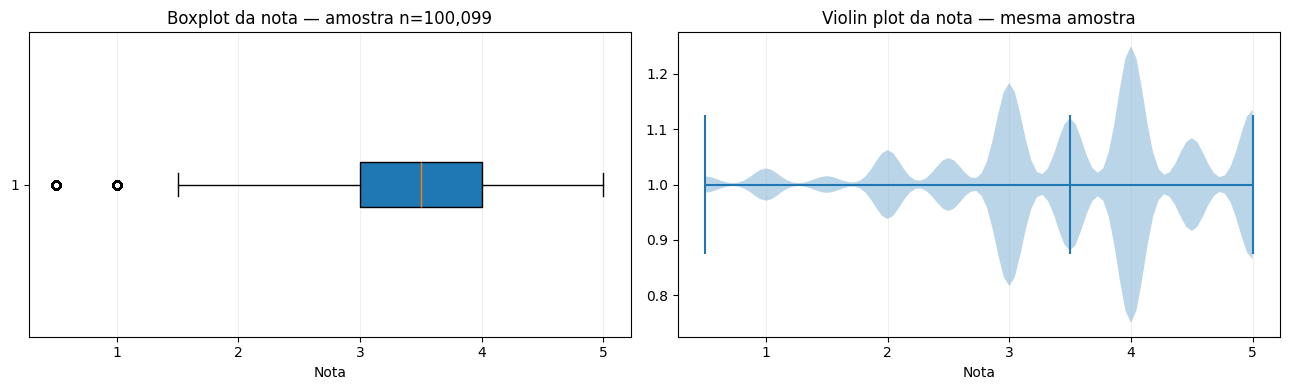

Amostra: Q1=3.0, Q3=4.0; limite inferior do whisker = 1.5
Notas abaixo desse limite pertencem à escala válida: são outliers legítimos e não são removidas.


In [7]:
# [1.5-b] Boxplot e violin plot da nota em amostra aleatória simples
FRACAO_AMOSTRA_NOTAS = 0.004  # cerca de 100 mil avaliações
amostra_pd = ratings_sel.sample(False, FRACAO_AMOSTRA_NOTAS, seed=42).select("rating").toPandas()

import inspect

def horizontal(metodo):  # Matplotlib >= 3.10 usa orientation; versões anteriores usam vert
    return {"orientation": "horizontal"} if "orientation" in inspect.signature(metodo).parameters else {"vert": False}

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].boxplot(amostra_pd["rating"], patch_artist=True, **horizontal(axes[0].boxplot))
axes[0].set_title(f"Boxplot da nota — amostra n={len(amostra_pd):,}")
axes[0].set_xlabel("Nota")
axes[1].violinplot(amostra_pd["rating"], showmedians=True, **horizontal(axes[1].violinplot))
axes[1].set_title("Violin plot da nota — mesma amostra")
axes[1].set_xlabel("Nota")
for ax in axes:
    ax.grid(axis="x", alpha=.2)
plt.tight_layout()
plt.show()

q1, q3 = amostra_pd["rating"].quantile([0.25, 0.75])
limite_inferior = q1 - 1.5 * (q3 - q1)
print(f"Amostra: Q1={q1}, Q3={q3}; limite inferior do whisker = {limite_inferior}")
print("Notas abaixo desse limite pertencem à escala válida: são outliers legítimos e não são removidas.")

**Leitura dos resultados.** Na amostra, Q1 = 3,0, Q3 = 4,0 e o limite inferior do whisker é 1,5. As notas 0,5 e 1,0 (4,68% das avaliações) aparecem como outliers pela regra do boxplot, mas pertencem à escala válida e são mantidas. O violin plot mostra mais densidade nos valores inteiros (4,0: 26,6%; 3,0: 19,6%; 5,0: 14,4%) do que nos meios pontos vizinhos.

#### Histogramas

- **Cinco grupos de nota:** cada grupo reúne duas notas adjacentes da escala original. O histograma mostra média e desvio-padrão no título.
- **Equi-width:** três intervalos de mesma largura entre 0,5 e 5,0. Amplitude = 4,5; largura = 1,5; baixa = [0,5; 2,0); média = [2,0; 3,5); alta = [3,5; 5,0].
- **Equi-depth:** procura quantidades semelhantes por faixa. Como só há dez valores possíveis e muitos empates, faixas exatamente iguais não são garantidas.
- **V-Optimal:** escolhe as faixas contíguas que minimizam a soma dos quadrados dentro das faixas.

+------+--------+----------------+-------------+
|bucket|count   |faixa           |proporcao_pct|
+------+--------+----------------+-------------+
|0.0   |1569373 |Baixa [0,5; 2,0)|6.2775       |
|1.0   |7800593 |Média [2,0; 3,5)|31.2023      |
|2.0   |15630129|Alta [3,5; 5,0] |62.5203      |
+------+--------+----------------+-------------+



+----------+-------+-------------+
|grupo_nota|count  |proporcao_pct|
+----------+-------+-------------+
|1         |1169883|4.6795       |
|2         |2040358|8.1614       |
|3         |6159725|24.6388      |
|4         |9817116|39.2683      |
|5         |5813013|23.252       |
+----------+-------+-------------+



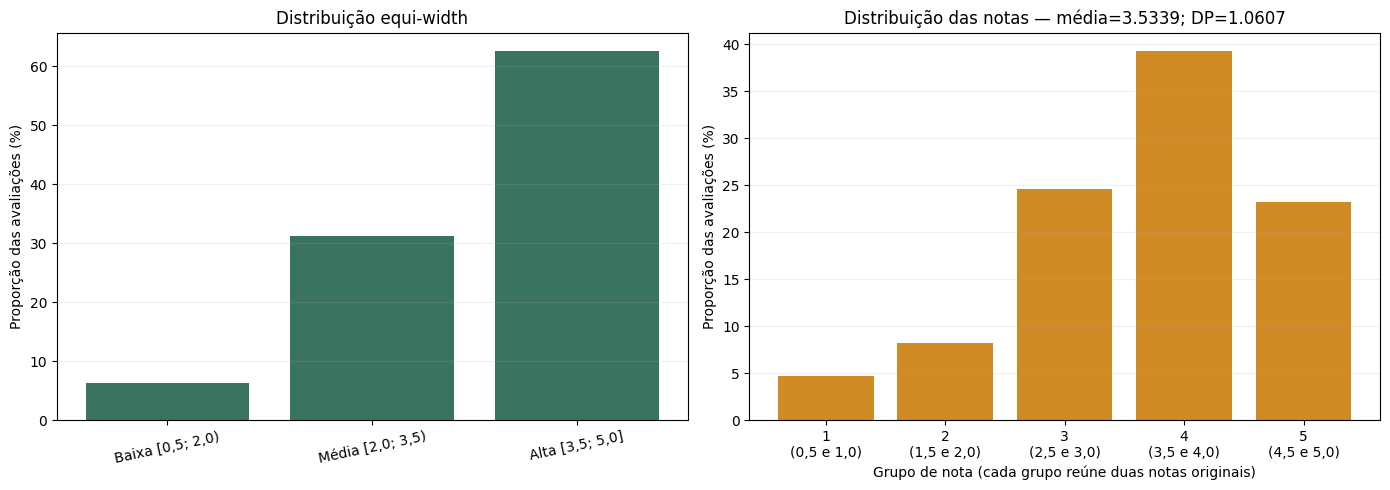

In [8]:
# [1.5-c] Histograma de cinco grupos de nota e histograma equi-width
from pyspark.ml.feature import Bucketizer
import matplotlib.pyplot as plt

# Três intervalos equi-width (mesma largura entre 0,5 e 5,0).
equi_width = Bucketizer(
    splits=[0.5, 2.0, 3.5, 5.000001], inputCol="rating", outputCol="bucket", handleInvalid="skip"
)
rating_buckets = (
    equi_width.transform(ratings_sel.select("rating"))
    .groupBy("bucket").count()
    .withColumn("faixa", F.when(F.col("bucket") == 0, "Baixa [0,5; 2,0)")
        .when(F.col("bucket") == 1, "Média [2,0; 3,5)").otherwise("Alta [3,5; 5,0]"))
    .withColumn("proporcao_pct", F.round(F.col("count") / F.lit(total_avaliacoes) * 100, 4))
    .orderBy("bucket")
)
rating_buckets.show(truncate=False)

# Cinco classes de nota; cada classe reúne dois valores adjacentes da escala original.
histograma_5_notas = (
    ratings_sel.withColumn("grupo_nota", F.ceil("rating").cast("int"))
    .groupBy("grupo_nota").count()
    .withColumn("proporcao_pct", F.round(F.col("count") / F.lit(total_avaliacoes) * 100, 4))
    .orderBy("grupo_nota")
)
assert histograma_5_notas.count() == 5
assert histograma_5_notas.agg(F.sum("count")).first()[0] == total_avaliacoes
histograma_5_notas.show(truncate=False)

# Os dois gráficos mostram proporção sobre o total de avaliações válidas.
eq_pd = rating_buckets.toPandas()
h5_pd = histograma_5_notas.toPandas()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(eq_pd["faixa"], eq_pd["proporcao_pct"], color="#397461")
axes[0].set_title("Distribuição equi-width")
axes[0].set_ylabel("Proporção das avaliações (%)")
axes[0].tick_params(axis="x", rotation=12)
axes[1].bar(h5_pd["grupo_nota"].astype(str), h5_pd["proporcao_pct"], color="#d18b24")
estatisticas_notas = resumo_notas.first()
media_nota_geral = float(estatisticas_notas["media"])
dp_nota_geral = float(estatisticas_notas["desvio_padrao"])
rotulos_grupos = ["1\n(0,5 e 1,0)", "2\n(1,5 e 2,0)", "3\n(2,5 e 3,0)", "4\n(3,5 e 4,0)", "5\n(4,5 e 5,0)"]
axes[1].set_title(f"Distribuição das notas — média={media_nota_geral:.4f}; DP={dp_nota_geral:.4f}")
axes[1].set_xlabel("Grupo de nota (cada grupo reúne duas notas originais)")
axes[1].set_ylabel("Proporção das avaliações (%)")
axes[1].set_xticks(range(5), rotulos_grupos)
for ax in axes: ax.grid(axis="y", alpha=.2)
plt.tight_layout()
plt.show()

In [9]:
# [1.5-d] Histograma equi-depth por quantis
from pyspark.ml.feature import QuantileDiscretizer

# O QuantileDiscretizer tenta criar faixas com o MESMO número de avaliações em cada uma.
# Vamos dividir em 3 grupos (tercis)
discretizer = QuantileDiscretizer(numBuckets=3, inputCol="rating", outputCol="bucket_depth", relativeError=0.01)

# O modelo encontra os cortes ideais
model = discretizer.fit(ratings_sel)
df_equidepth = model.transform(ratings_sel)

print("Limites encontrados pelo Equi-depth:", model.getSplits())

equidepth_hist = (
    df_equidepth.groupBy("bucket_depth")
    .count()
    .withColumn("proporcao_pct", F.round((F.col("count") / F.lit(total_avaliacoes)) * 100, 4))
    .orderBy("bucket_depth")
)

equidepth_hist.show(truncate=False)

Limites encontrados pelo Equi-depth: [-inf, 3.0, 4.0, inf]


+------------+--------+-------------+
|bucket_depth|count   |proporcao_pct|
+------------+--------+-------------+
|0.0         |4473038 |17.8921      |
|1.0         |8074246 |32.2969      |
|2.0         |12452811|49.8111      |
+------------+--------+-------------+



In [10]:
# [1.5-e] Histograma V-Optimal com três faixas e comparação dos três histogramas
from itertools import combinations

def custo_v(i, j):
    n = sum(freqs[i:j])
    media = sum(valores[k] * freqs[k] for k in range(i, j)) / n
    return sum(freqs[k] * (valores[k] - media) ** 2 for k in range(i, j))

melhor = min((sum(custo_v(a, b) for a, b in zip((0,) + cortes, cortes + (len(valores),))), cortes)
             for cortes in combinations(range(1, len(valores)), 2))
_, cortes_v = melhor
limites_v = (0,) + cortes_v + (len(valores),)
linhas_v = []
for a, b in zip(limites_v, limites_v[1:]):
    n = sum(freqs[a:b])
    linhas_v.append((f"{valores[a]:.1f}–{valores[b-1]:.1f}", n, round(100 * n / N, 4), round(custo_v(a, b), 1)))
v_optimal_pd = pd.DataFrame(linhas_v, columns=["Faixa de notas", "n", "%", "SSE dentro da faixa"])
print("V-Optimal (3 faixas; ótimo exato sobre os 10 valores discretos); SSE total =", round(melhor[0], 1))
print(v_optimal_pd.to_string(index=False))

comparacao_histogramas = pd.DataFrame({
    "equi-width (%)": eq_pd.sort_values("bucket")["proporcao_pct"].to_numpy(),
    "equi-depth (%)": equidepth_hist.toPandas().sort_values("bucket_depth")["proporcao_pct"].to_numpy(),
    "V-Optimal (%)": v_optimal_pd["%"].to_numpy(),
}, index=["faixa 1", "faixa 2", "faixa 3"])
print("Proporção das avaliações em cada faixa (denominador = total de avaliações):")
print(comparacao_histogramas.to_string())

V-Optimal (3 faixas; ótimo exato sobre os 10 valores discretos); SSE total = 4387983.2
Faixa de notas        n       %  SSE dentro da faixa
       0.5–2.0  3210241 12.8409             997016.0
       2.5–3.5  9337043 37.3480            1011887.7
       4.0–5.0 12452811 49.8111            2379079.6


Proporção das avaliações em cada faixa (denominador = total de avaliações):
         equi-width (%)  equi-depth (%)  V-Optimal (%)
faixa 1          6.2775         17.8921        12.8409
faixa 2         31.2023         32.2969        37.3480
faixa 3         62.5203         49.8111        49.8111


#### Comparação visual dos histogramas e diagrama circular

Os três histogramas de três faixas são apresentados lado a lado, com a média e o desvio-padrão da nota. O diagrama circular mostra a frequência relativa dos cinco grupos de nota.

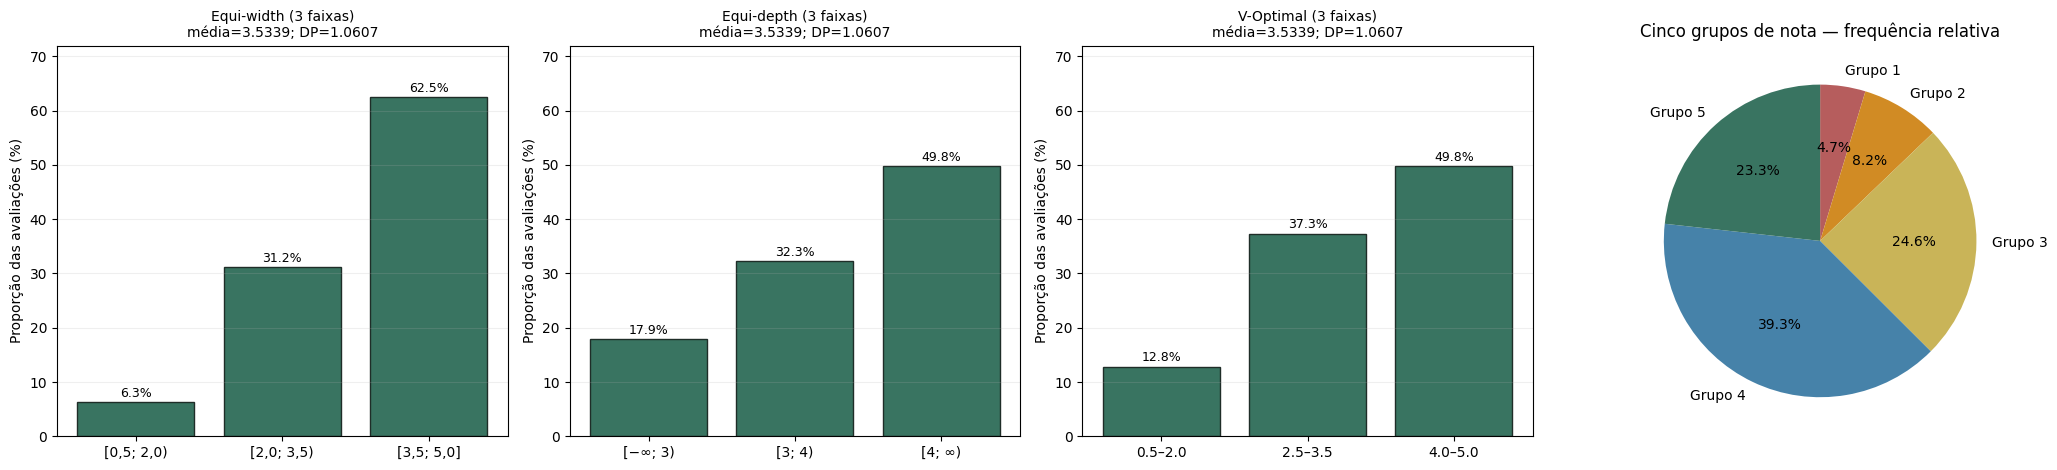

In [11]:
# [1.5-f] Comparação visual dos histogramas de três faixas e diagrama circular dos cinco grupos
eqd_pd = equidepth_hist.toPandas().sort_values("bucket_depth")
cortes_eqd = model.getSplits()
rotulos_eqd = [f"[{a:g}; {b:g})".replace("-inf", "−∞").replace("inf", "∞") for a, b in zip(cortes_eqd[:-1], cortes_eqd[1:])]
paineis = [
    ("Equi-width", ["[0,5; 2,0)", "[2,0; 3,5)", "[3,5; 5,0]"], eq_pd.sort_values("bucket")["proporcao_pct"].to_numpy()),
    ("Equi-depth", rotulos_eqd, eqd_pd["proporcao_pct"].to_numpy()),
    ("V-Optimal", v_optimal_pd["Faixa de notas"].tolist(), v_optimal_pd["%"].to_numpy()),
]
fig, axes = plt.subplots(1, 4, figsize=(21, 4.8))
for ax, (titulo, rotulos, valores) in zip(axes[:3], paineis):
    ax.bar(range(len(valores)), valores, color="#397461", edgecolor="#1f2d28")
    ax.set_xticks(range(len(valores)), rotulos)
    for x, v in enumerate(valores):
        ax.text(x, v + 1, f"{v:.1f}%", ha="center", fontsize=9)
    ax.set_title(f"{titulo} (3 faixas)\nmédia={media_nota_geral:.4f}; DP={dp_nota_geral:.4f}", fontsize=10)
    ax.set_ylabel("Proporção das avaliações (%)")
    ax.set_ylim(0, 72)
    ax.grid(axis="y", alpha=.2)
axes[3].pie(h5_pd["proporcao_pct"], labels=[f"Grupo {g}" for g in h5_pd["grupo_nota"]], autopct="%.1f%%",
            startangle=90, counterclock=False,
            colors=["#b65d5d", "#d18b24", "#c9b458", "#4682a9", "#397461"])
axes[3].set_title("Cinco grupos de nota — frequência relativa")
plt.tight_layout()
plt.show()

**Leitura dos resultados.**

- **Cinco grupos:** o grupo 4 (notas 3,5 e 4,0) concentra 39,27% das avaliações e o grupo 1 (0,5 e 1,0) apenas 4,68%.
- **Equi-width:** coloca 62,52% das avaliações na faixa alta [3,5; 5,0].
- **Equi-depth:** não consegue faixas de mesmo tamanho (17,89%, 32,30% e 49,81%), porque há apenas dez valores possíveis e muitos empates.
- **V-Optimal:** forma as faixas 0,5–2,0, 2,5–3,5 e 4,0–5,0 (12,84%, 37,35% e 49,81%), que minimizam a soma dos quadrados dentro das faixas. Sua última fronteira (4,0) coincide com o limiar de nota positiva usado no perfil.

**Consequência:** a distribuição se concentra em notas altas. A proporção de notas positivas de um usuário deve ser lida em relação a essa base de quase 50%.

### 1.6 Exploração univariada categórica e volume por objeto

- **Gêneros:** frequência, proporção e moda no catálogo. Os rótulos aparecem como na fonte, incluindo `(no genres listed)`.
- **Volume:** quantidade de avaliações por usuário e por filme, e filmes do catálogo sem avaliação.

In [12]:
# [1.6] Gêneros no catálogo e volume de avaliações por usuário e por filme
total_filmes = movies_sel.count()
genres_freq = (
    movie_genres_sel.groupBy("genre").count()
    .withColumn("proporcao_pct", F.round(F.col("count") / F.lit(total_filmes) * 100, 4))
    .orderBy(F.col("count").desc())
)
genres_freq.show(25, truncate=False)
print("Denominador = filmes do catálogo; gêneros se sobrepõem, então a soma passa de 100%.")
print("Moda do atributo gênero:", genres_freq.first()["genre"])

for rotulo, chave in [("usuário", "userId"), ("filme", "movieId")]:
    suporte = ratings_sel.groupBy(chave).count()
    q = suporte.approxQuantile("count", [0.0, 0.25, 0.5, 0.75, 1.0], 0.005)
    print(f"Avaliações por {rotulo} (mín, Q1, mediana, Q3, máx; quantis aproximados): {q}")

filmes_sem_avaliacao = movies_sel.join(ratings_sel.select("movieId").distinct(), "movieId", "left_anti").count()
print(f"Filmes do catálogo sem nenhuma avaliação: {filmes_sem_avaliacao:,} de {total_filmes:,}")

+------------------+-----+-------------+
|genre             |count|proporcao_pct|
+------------------+-----+-------------+
|Drama             |25606|41.0201      |
|Comedy            |16870|27.0253      |
|Thriller          |8654 |13.8635      |
|Romance           |7719 |12.3656      |
|Action            |7348 |11.7713      |
|Horror            |5989 |9.5942       |
|Documentary       |5605 |8.9791       |
|Crime             |5319 |8.5209       |
|(no genres listed)|5062 |8.1092       |
|Adventure         |4145 |6.6402       |
|Sci-Fi            |3595 |5.7591       |
|Children          |2935 |4.7018       |
|Animation         |2929 |4.6922       |
|Mystery           |2925 |4.6858       |
|Fantasy           |2731 |4.375        |
|War               |1874 |3.0021       |
|Western           |1399 |2.2412       |
|Musical           |1054 |1.6885       |
|Film-Noir         |353  |0.5655       |
|IMAX              |195  |0.3124       |
+------------------+-----+-------------+

Denominador = f

Moda do atributo gênero: Drama


Avaliações por usuário (mín, Q1, mediana, Q3, máx; quantis aproximados): [20.0, 36.0, 70.0, 159.0, 32202.0]


Avaliações por filme (mín, Q1, mediana, Q3, máx; quantis aproximados): [1.0, 2.0, 6.0, 35.0, 81491.0]


Filmes do catálogo sem nenhuma avaliação: 3,376 de 62,423


**Leitura dos resultados.**

- **Gêneros:** Drama é a moda (41,02% dos filmes do catálogo), seguido de Comedy (27,03%). 5.062 filmes (8,11%) não têm gênero informado.
- **Volume:**
  - por usuário, a mediana é de 70 avaliações (máximo 32.202);
  - por filme, a mediana é de 6 (máximo 81.491), e 25% dos filmes têm no máximo 2 avaliações;
  - 3.376 filmes do catálogo não têm nenhuma avaliação.

**Consequência:** médias por filme só são comparadas com suporte mínimo, e a atividade do usuário entra como proporção, não como contagem bruta.

#### Exploração temporal das avaliações

O `timestamp` é intervalar: diferenças entre instantes fazem sentido. Aqui ele é convertido em ano da avaliação para descrever o volume por ano, a média e o desvio-padrão da nota por ano, e o uso de notas de meio ponto. A razão de correlação η mede quanto da variação das notas se associa ao ano. Também se mede o período de atividade de cada usuário, ou seja, os dias entre a primeira e a última avaliação.

 ano_avaliacao       n  proporcao_%  media     dp  meio_ponto_%
          1995       3       0.0000 3.6667 1.1547        0.0000
          1996 1430093       5.7204 3.5457 0.9949        0.0000
          1997  626202       2.5048 3.5877 1.0077        0.0000
          1998  272099       1.0884 3.5128 1.1341        0.0000
          1999 1059080       4.2363 3.6168 1.1195        0.0000
          2000 1735398       6.9416 3.5751 1.1220        0.0000
          2001 1058750       4.2350 3.5324 1.1177        0.0000
          2002  776654       3.1066 3.4857 1.1142        0.0000
          2003  920295       3.6812 3.4770 1.0619       29.1513
          2004 1048116       4.1924 3.4308 1.0363       44.3087
          2005 1613550       6.4542 3.4335 1.0352       44.2853
          2006 1038458       4.1538 3.4667 1.0274       43.4087
          2007  931432       3.7257 3.4723 1.0318       43.5895
          2008 1018001       4.0720 3.5381 1.0090       43.7244
          2009  810127       3.2405 3.50

Dias entre a primeira e a última avaliação de cada usuário (mín, Q1, mediana, Q3, máx): [0.0, 0.0, 0.0, 38.3, 8101.4]


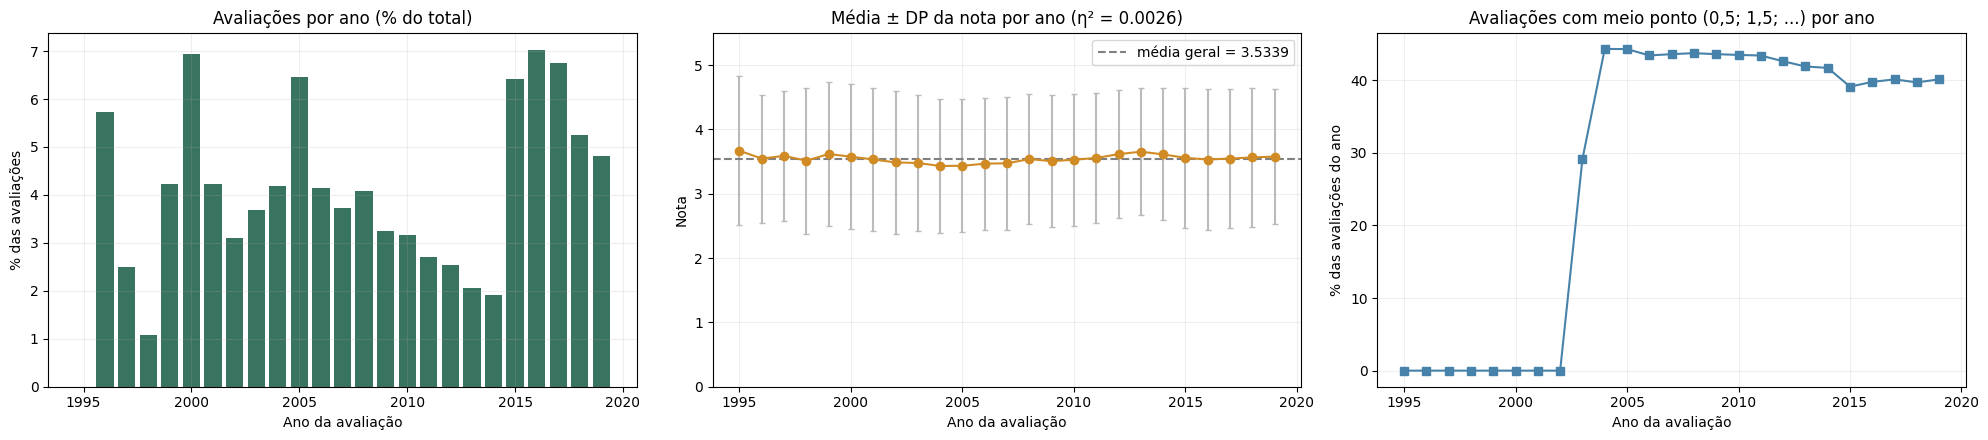

In [13]:
# [1.6-b] Exploração temporal: ano da avaliação, nota média e uso de meio ponto
por_ano = (
    ratings_sel
    .withColumn("ano_avaliacao", F.year(F.from_unixtime("timestamp")))
    .groupBy("ano_avaliacao")
    .agg(F.count("*").alias("n"), F.avg("rating").alias("media"), F.stddev("rating").alias("dp"),
         F.avg(F.when((F.col("rating") * 2) % 2 == 1, 1.0).otherwise(0.0)).alias("prop_meio_ponto"))
    .orderBy("ano_avaliacao")
    .toPandas()
)
assert int(por_ano["n"].sum()) == total_avaliacoes
por_ano["proporcao_%"] = 100 * por_ano["n"] / por_ano["n"].sum()
por_ano["meio_ponto_%"] = 100 * por_ano["prop_meio_ponto"]
print(por_ano[["ano_avaliacao", "n", "proporcao_%", "media", "dp", "meio_ponto_%"]].round(4).to_string(index=False))
print(f"Período das avaliações: {int(por_ano.ano_avaliacao.min())}–{int(por_ano.ano_avaliacao.max())}")

# Razão de correlação η entre ano da avaliação (categoria) e nota (numérica), a partir das somas por ano.
media_geral_notas = float((por_ano["n"] * por_ano["media"]).sum() / por_ano["n"].sum())
ss_entre_anos = float((por_ano["n"] * (por_ano["media"] - media_geral_notas) ** 2).sum())
ss_total_notas = float(resumo_extra["variancia"]) * (total_avaliacoes - 1)
eta2_ano = ss_entre_anos / ss_total_notas
print(f"Razão de correlação ano da avaliação × nota: η={eta2_ano ** 0.5:.4f}; η²={eta2_ano:.4f}")

atividade = ratings_sel.groupBy("userId").agg(((F.max("timestamp") - F.min("timestamp")) / 86400.0).alias("dias"))
q_dias = atividade.approxQuantile("dias", [0.0, 0.25, 0.5, 0.75, 1.0], 0.005)
print("Dias entre a primeira e a última avaliação de cada usuário (mín, Q1, mediana, Q3, máx):",
      [round(x, 1) for x in q_dias])

fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
axes[0].bar(por_ano["ano_avaliacao"].astype(int), por_ano["proporcao_%"], color="#397461")
axes[0].set(title="Avaliações por ano (% do total)", xlabel="Ano da avaliação", ylabel="% das avaliações")
axes[1].errorbar(por_ano["ano_avaliacao"], por_ano["media"], yerr=por_ano["dp"], fmt="o-", color="#d18b24",
                 ecolor="#bbbbbb", capsize=2)
axes[1].axhline(media_geral_notas, ls="--", color="gray", label=f"média geral = {media_geral_notas:.4f}")
axes[1].set(title=f"Média ± DP da nota por ano (η² = {eta2_ano:.4f})", xlabel="Ano da avaliação", ylabel="Nota",
            ylim=(0, 5.5))
axes[1].legend()
axes[2].plot(por_ano["ano_avaliacao"], por_ano["meio_ponto_%"], "s-", color="#4682a9")
axes[2].set(title="Avaliações com meio ponto (0,5; 1,5; ...) por ano", xlabel="Ano da avaliação",
            ylabel="% das avaliações do ano")
for ax in axes:
    ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

**Leitura dos resultados.**

- **Volume:** as avaliações vão de 1995 a 2019. O volume oscila por ano, com picos em 2000 (6,94%), 2005 (6,45%) e 2015–2017 (6,42% a 7,03%).
- **Nota por ano:** a média anual varia pouco, de 3,43 (2004) a 3,65 (2013), sem contar 1995, que tem só 3 avaliações. O ano explica apenas 0,26% da variação das notas (η = 0,051; η² = 0,0026).
- **Mudança de escala:** notas de meio ponto só aparecem a partir de 2003 (0% até 2002, 29,15% em 2003 e 39% a 44% depois). Nas avaliações anteriores a 2003, cada um dos cinco grupos de nota contém apenas a nota inteira correspondente.
- **Período de atividade:** a mediana é 0 dia (Q3 = 38,3 dias), ou seja, mais da metade dos usuários fez todas as suas avaliações no mesmo dia.

**Limitação:** para a maioria dos usuários, o perfil de P1 reflete uma única sessão de avaliação, não preferências acompanhadas ao longo do tempo.

**Consequência:** o tempo não entra no perfil de P1, e a mudança de escala de 2003 é registrada na interpretação das notas de meio ponto.

#### Distribuição dos gêneros

A distribuição dos filmes por gênero é a base para decidir o tratamento dos gêneros no pré-processamento. Para cada gênero, quatro medidas lado a lado:

- porcentagem dos filmes do catálogo;
- porcentagem das avaliações (um filme com vários gêneros conta em cada um);
- avaliações por filme, que separa gêneros com muitos filmes, mas pouca audiência;
- nota média ± desvio-padrão.

`(no genres listed)` aparece em laranja: são filmes sem gênero, alguns com avaliações, candidatos à imputação (2.2-b). As tags ficam fora dos dados-alvo nesta fase: não são usadas em P1 nem em P2. A função de histograma definida aqui é usada nas seções seguintes.

Denominadores: % filmes = filmes do gênero / 62.423 filmes; % avaliações = avaliações de filmes do gênero / 25.000.095 avaliações. Gêneros se sobrepõem, então as somas passam de 100%.
             genre  filmes  %_filmes  avaliacoes  %_avaliacoes  avaliacoes_por_filme  %_filmes_sem_avaliacao  media    dp
             Drama   25606    41.020    10962833        43.851               428.135                   4.456  3.677 0.998
            Comedy   16870    27.025     8926230        35.705               529.119                   4.855  3.424 1.083
            Action    7348    11.771     7446918        29.788              1013.462                   5.920  3.467 1.071
          Thriller    8654    13.863     6763272        27.053               781.520                   3.744  3.523 1.038
         Adventure    4145     6.640     5832424        23.330              1407.099                   6.683  3.517 1.068
           Romance    7719    12.366     4497291        17.989               582.626

Filmes sem gênero com pelo menos 1 avaliação(ões): 4,568 de 5,062; 26,627 avaliações
Filmes sem gênero com pelo menos 10 avaliação(ões): 320 de 5,062; 16,758 avaliações
Filmes sem gênero com pelo menos 50 avaliação(ões): 38 de 5,062; 11,663 avaliações


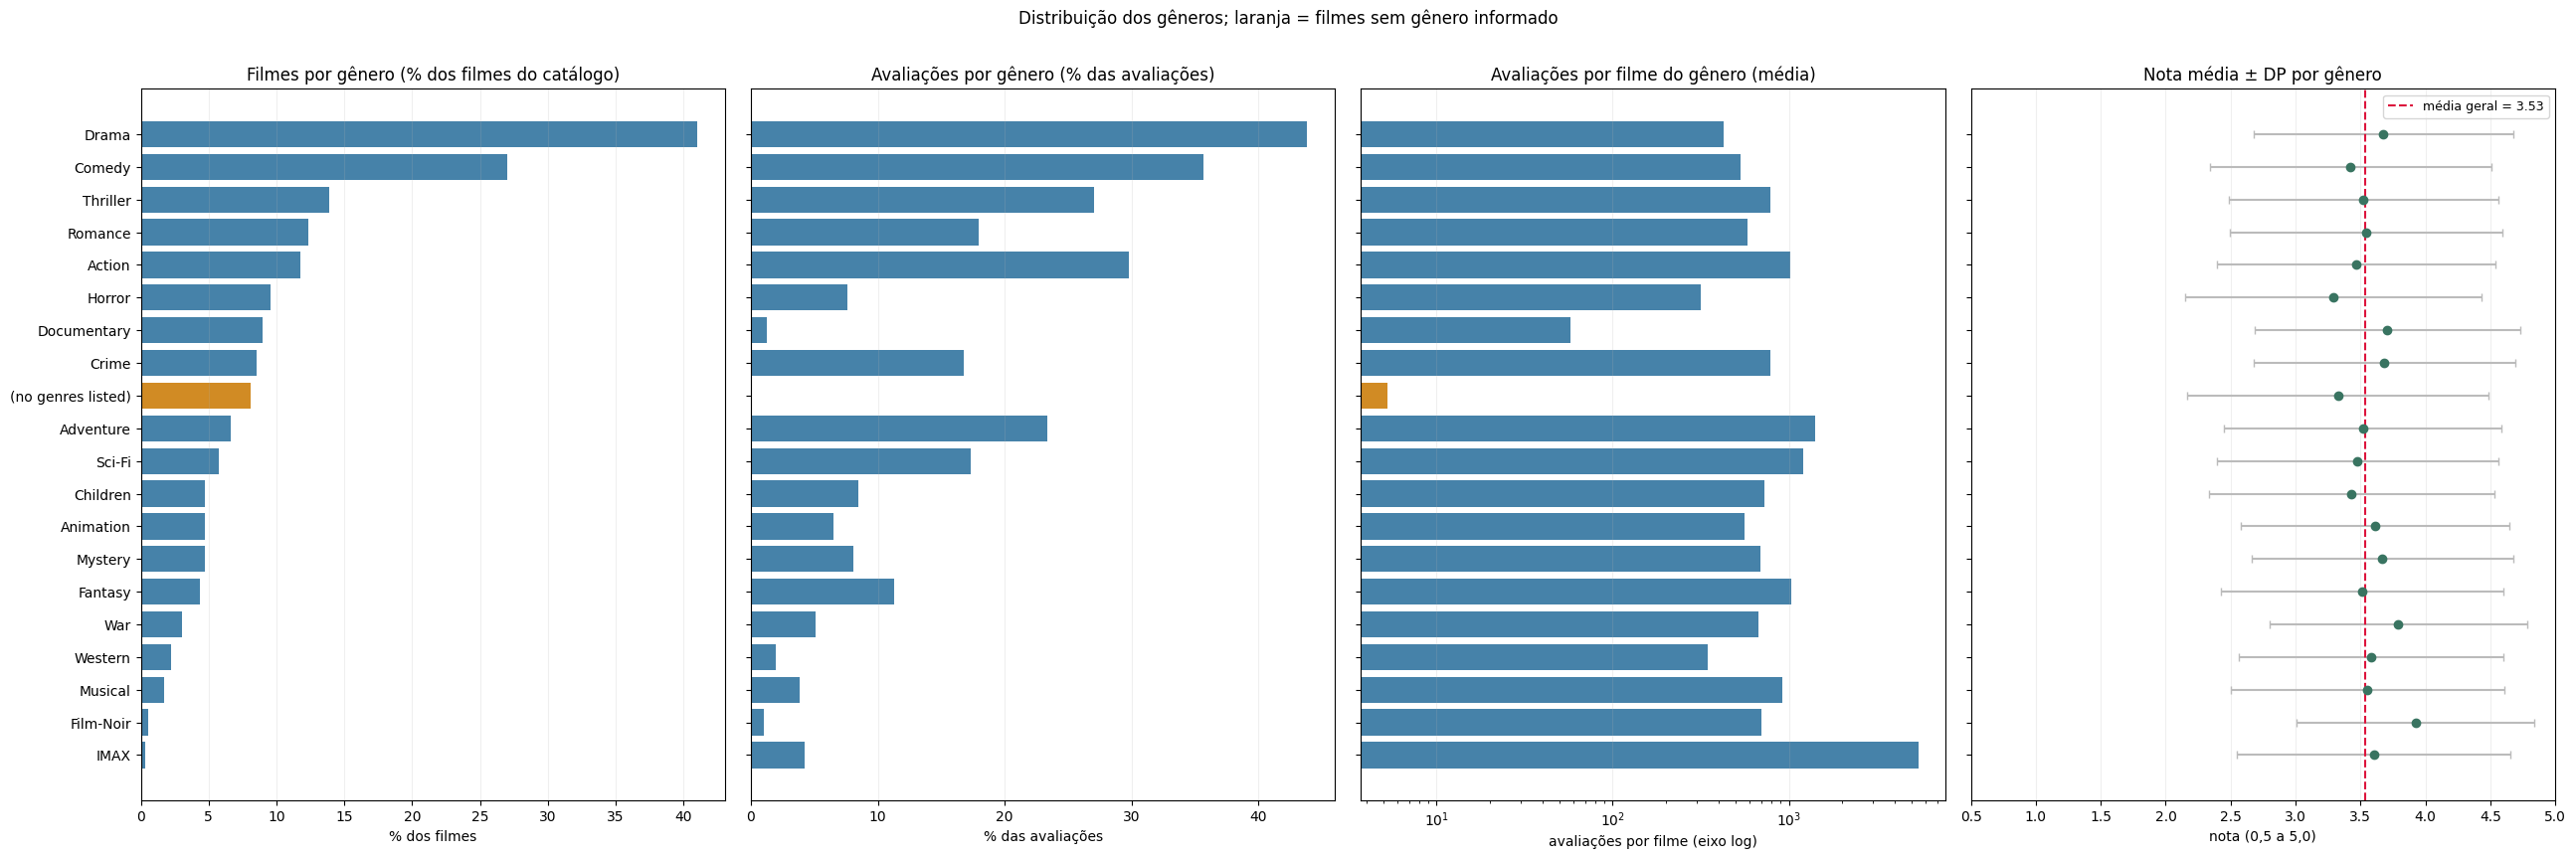

In [14]:
# [1.6-c] Distribuição dos gêneros: filmes, avaliações, avaliações por filme e nota (média e desvio-padrão)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def histograma_media_dp(ax, valores, titulo, bins=30, log_x=False, cor="#4682a9", rotulo_x=""):
    """Histograma em % dos objetos, com a média (linha contínua) e média ± 1 DP (linhas tracejadas)."""
    valores = pd.Series(valores).dropna().astype(float)
    media, dp = valores.mean(), valores.std(ddof=1)
    if log_x:
        positivos = valores[valores > 0]
        bordas = np.logspace(np.log10(positivos.min()), np.log10(positivos.max()), bins + 1)
        ax.set_xscale("log")
    else:
        bordas = bins
    ax.hist(valores, bins=bordas, weights=np.full(len(valores), 100 / len(valores)), color=cor, edgecolor="white")
    ax.axvline(media, color="crimson", lw=1.6, label=f"média = {media:.3g}")
    for lado in (media - dp, media + dp):
        if not log_x or lado > 0:
            ax.axvline(lado, color="crimson", lw=1.1, ls="--")
    ax.plot([], [], color="crimson", ls="--", label=f"média ± 1 DP (DP = {dp:.3g})")
    ax.set_title(f"{titulo}\nμ={media:.3g}; DP={dp:.3g}; n={len(valores):,}", fontsize=10)
    ax.set_xlabel(rotulo_x)
    ax.set_ylabel("% dos objetos")
    ax.legend(fontsize=8)
    ax.grid(axis="y", alpha=.2)
    return media, dp


SEM_GENERO = "(no genres listed)"
filmes_avaliados_sel = ratings_sel.select("movieId").distinct()
dist_generos = (ratings_genres_sel.groupBy("genre")
    .agg(F.count("*").alias("avaliacoes"), F.avg("rating").alias("media"), F.stddev("rating").alias("dp"))
    .join(genres_freq.select("genre", F.col("count").alias("filmes")), "genre", "right")
    .join(movie_genres_sel.join(filmes_avaliados_sel, "movieId").groupBy("genre")
          .agg(F.countDistinct("movieId").alias("filmes_avaliados")), "genre", "left")
    .toPandas().fillna({"avaliacoes": 0, "filmes_avaliados": 0}))
dist_generos["%_filmes"] = 100 * dist_generos["filmes"] / total_filmes
dist_generos["%_avaliacoes"] = 100 * dist_generos["avaliacoes"] / total_avaliacoes
dist_generos["avaliacoes_por_filme"] = dist_generos["avaliacoes"] / dist_generos["filmes"]
dist_generos["%_filmes_sem_avaliacao"] = 100 * (1 - dist_generos["filmes_avaliados"] / dist_generos["filmes"])
dist_generos = dist_generos.sort_values("%_filmes", ascending=True).reset_index(drop=True)
print("Denominadores: % filmes = filmes do gênero / 62.423 filmes; % avaliações = avaliações de filmes do gênero / "
      "25.000.095 avaliações. Gêneros se sobrepõem, então as somas passam de 100%.")
print(dist_generos.sort_values("%_avaliacoes", ascending=False)[
    ["genre", "filmes", "%_filmes", "avaliacoes", "%_avaliacoes", "avaliacoes_por_filme", "%_filmes_sem_avaliacao", "media", "dp"]
].round(3).to_string(index=False))

# Filmes sem gênero: quantos têm avaliações e quantas avaliações têm (candidatos à imputação em 2.2-b).
sem_genero_pd = (movies_sel.filter(F.col("genres") == SEM_GENERO).select("movieId")
                 .join(ratings_sel.groupBy("movieId").count(), "movieId", "left").fillna(0).toPandas())
for limite in (1, 10, 50):
    parte = sem_genero_pd[sem_genero_pd["count"] >= limite]
    print(f"Filmes sem gênero com pelo menos {limite} avaliação(ões): {len(parte):,} de {len(sem_genero_pd):,}; "
          f"{int(parte['count'].sum()):,} avaliações")

cores = ["#d18b24" if g == SEM_GENERO else "#4682a9" for g in dist_generos["genre"]]
fig, axes = plt.subplots(1, 4, figsize=(26, 8.5), sharey=True)
axes[0].barh(dist_generos["genre"], dist_generos["%_filmes"], color=cores)
axes[0].set(title="Filmes por gênero (% dos filmes do catálogo)", xlabel="% dos filmes")
axes[1].barh(dist_generos["genre"], dist_generos["%_avaliacoes"], color=cores)
axes[1].set(title="Avaliações por gênero (% das avaliações)", xlabel="% das avaliações")
axes[2].barh(dist_generos["genre"], dist_generos["avaliacoes_por_filme"], color=cores)
axes[2].set_xscale("log")
axes[2].set(title="Avaliações por filme do gênero (média)", xlabel="avaliações por filme (eixo log)")
axes[3].errorbar(dist_generos["media"], dist_generos["genre"], xerr=dist_generos["dp"], fmt="o", color="#397461",
                 ecolor="#bbbbbb", capsize=3)
axes[3].axvline(media_nota_geral, color="crimson", ls="--", label=f"média geral = {media_nota_geral:.2f}")
axes[3].set(title="Nota média ± DP por gênero", xlabel="nota (0,5 a 5,0)", xlim=(0.5, 5))
axes[3].legend(fontsize=9)
for ax in axes:
    ax.grid(axis="x", alpha=.2)
fig.suptitle("Distribuição dos gêneros; laranja = filmes sem gênero informado", y=1.01)
plt.tight_layout()
plt.show()

**Leitura dos resultados.**

- **Filmes × avaliações:** a ordem dos gêneros muda conforme o denominador. Drama lidera nos dois (41,0% dos filmes e 43,9% das avaliações). Action tem 11,8% dos filmes, mas 29,8% das avaliações, e Adventure, 6,6% contra 23,3%. No sentido oposto, Documentary tem 9,0% dos filmes e só 1,3% das avaliações.
- **Avaliações por filme:** separam os gêneros com muitos filmes pouco vistos. IMAX tem 5.453 avaliações por filme, Adventure 1.407 e Sci-Fi 1.203, contra 57,5 em Documentary. Western tem a maior fração de filmes sem nenhuma avaliação (17,4%).
- **Gêneros com pouca participação nas avaliações:** Film-Noir (0,99%), Documentary (1,29%), Western (1,94%), Musical (3,86%) e IMAX (4,25%). Musical e IMAX têm mais avaliações por filme que Drama: a participação baixa vem de terem poucos filmes, não de filmes pouco vistos.
- **Nota:** a média por gênero vai de 3,29 (Horror) a 3,93 (Film-Noir), com desvio-padrão entre 0,91 e 1,16. As distribuições dos gêneros se sobrepõem bastante.
- **Filmes sem gênero:** `(no genres listed)` reúne 5.062 filmes (8,1% do catálogo), mas só 26.627 avaliações (0,11%), ou 5,3 por filme, a menor audiência entre todos os rótulos. A nota média é 3,33, com o maior desvio-padrão (1,16). Dos 5.062 filmes:
  - 4.568 têm pelo menos uma avaliação;
  - 320 têm pelo menos 10 avaliações e concentram 16.758 avaliações (63% das avaliações sem gênero);
  - 38 têm pelo menos 50 avaliações.

**Consequência:**

- os filmes sem gênero com pelo menos 10 avaliações têm informação suficiente para estimar o gênero a partir de quem os avaliou (2.2-b); os demais têm poucas avaliações e continuam `Unknown`;
- os gêneros com pouca participação continuam como rótulos nos dados, porque são informação real do catálogo, e são agrupados no vetor revisado (3.8), para que não distorçam as distâncias.

### 1.7 Consultas por gênero, filme e usuário

Cada gênero é tratado como uma consulta: há um histograma de cinco grupos de nota para cada um dos 20 rótulos. A proporção de cada gráfico usa as avaliações daquele gênero como denominador, então as cinco faixas somam 100%. As tabelas também mostram a participação sobre as avaliações originais e sobre a expansão avaliação × gênero; essas participações podem passar de 100% no total, porque os gêneros se sobrepõem.

As distribuições das médias e do número de avaliações por filme e por usuário usam a população de filmes ou de usuários como denominador. Os títulos mostram média e desvio-padrão entre objetos. Filmes só são ordenados por média com suporte mínimo de 50 avaliações.

In [15]:
# [1.7-a] Estatísticas por filme, gênero e usuário: média, desvio e proporções
estatisticas_filmes = (
    ratings_movies_sel
    .groupBy("movieId", "title")
    .agg(
        F.count("*").alias("quantidade_avaliacoes"),
        F.avg("rating").alias("media_avaliacoes"),
        F.stddev("rating").alias("desvio_padrao"),
    )
    .withColumn("proporcao_total", F.col("quantidade_avaliacoes") / F.lit(total_avaliacoes))
    .withColumn("participacao_total_pct", F.col("proporcao_total") * 100)
    .select("movieId", "title", "quantidade_avaliacoes",
            F.round("proporcao_total", 10).alias("proporcao_total"),
            F.round("participacao_total_pct", 8).alias("participacao_total_pct"),
            F.round("media_avaliacoes", 4).alias("media_avaliacoes"),
            F.round("desvio_padrao", 4).alias("desvio_padrao"))
)

melhores_filmes_com_suporte = (
    estatisticas_filmes
    .filter(F.col("quantidade_avaliacoes") >= 50)
    .orderBy(F.col("media_avaliacoes").desc(), F.col("quantidade_avaliacoes").desc())
)

# Cada filme pode ter mais de um gênero; aqui a proporção usa o total de linhas
# da tabela expandida avaliação × gênero, não o total de avaliações originais.
estatisticas_generos = (
    ratings_genres_sel
    .groupBy("genre")
    .agg(
        F.count("*").alias("quantidade_avaliacoes_genero"),
        F.avg("rating").alias("media_avaliacoes"),
        F.stddev("rating").alias("desvio_padrao"),
    )
    .withColumn("proporcao_da_expansao",
                F.col("quantidade_avaliacoes_genero") / F.lit(linhas_ratings_genres_sel))
    .withColumn("participacao_expansao_pct", F.col("proporcao_da_expansao") * 100)
    .withColumn("equivalente_sobre_avaliacoes_originais",
                F.col("quantidade_avaliacoes_genero") / F.lit(total_avaliacoes))
    .select("genre", "quantidade_avaliacoes_genero",
            F.round("proporcao_da_expansao", 6).alias("proporcao_da_expansao"),
            F.round("participacao_expansao_pct", 4).alias("participacao_expansao_pct"),
            F.round("equivalente_sobre_avaliacoes_originais", 10).alias("equivalente_sobre_avaliacoes_originais"),
            F.round("media_avaliacoes", 4).alias("media_avaliacoes"),
            F.round("desvio_padrao", 4).alias("desvio_padrao"))
    .orderBy(F.col("media_avaliacoes").desc())
)

estatisticas_usuarios = (
    ratings_sel
    .groupBy("userId")
    .agg(
        F.count("*").alias("quantidade_avaliacoes"),
        F.avg("rating").alias("media_avaliacoes"),
        F.stddev("rating").alias("desvio_padrao"),
    )
    .withColumn("proporcao_total", F.col("quantidade_avaliacoes") / F.lit(total_avaliacoes))
    .withColumn("participacao_total_pct", F.col("proporcao_total") * 100)
    .select("userId", "quantidade_avaliacoes",
            F.round("proporcao_total", 10).alias("proporcao_total"),
            F.round("participacao_total_pct", 8).alias("participacao_total_pct"),
            F.round("media_avaliacoes", 4).alias("media_avaliacoes"),
            F.round("desvio_padrao", 4).alias("desvio_padrao"))
)

print("Filmes com melhor média (mínimo 50 avaliações):")
melhores_filmes_com_suporte.show(20, truncate=False)
print("Média, desvio e proporção por gênero; a expansão por gêneros é o denominador:")
estatisticas_generos.show(30, truncate=False)
print("Média, desvio e participação de cada usuário no total das avaliações:")
estatisticas_usuarios.orderBy(F.desc("quantidade_avaliacoes")).show(20, truncate=False)
print("Em estatisticas_filmes/usuarios, proporcao_total = contagem / 25.000.095. "
      "Em estatisticas_generos, proporcao_da_expansao = contagem / 67.809.886; gêneros se sobrepõem.")

Filmes com melhor média (mínimo 50 avaliações):


+-------+---------------------------------------------------+---------------------+---------------+----------------------+----------------+-------------+
|movieId|title                                              |quantidade_avaliacoes|proporcao_total|participacao_total_pct|media_avaliacoes|desvio_padrao|
+-------+---------------------------------------------------+---------------------+---------------+----------------------+----------------+-------------+
|171011 |Planet Earth II (2016)                             |1124                 |4.49598E-5     |0.00449598            |4.4831          |0.7885       |
|159817 |Planet Earth (2006)                                |1747                 |6.98797E-5     |0.00698797            |4.4648          |0.7253       |
|318    |Shawshank Redemption, The (1994)                   |81482                |0.0032592676   |0.32592676            |4.4136          |0.7604       |
|170705 |Band of Brothers (2001)                            |1356           

+------------------+----------------------------+---------------------+-------------------------+--------------------------------------+----------------+-------------+
|genre             |quantidade_avaliacoes_genero|proporcao_da_expansao|participacao_expansao_pct|equivalente_sobre_avaliacoes_originais|media_avaliacoes|desvio_padrao|
+------------------+----------------------------+---------------------+-------------------------+--------------------------------------+----------------+-------------+
|Film-Noir         |247227                      |0.003646             |0.3646                   |0.0098890424                          |3.9257          |0.9144       |
|War               |1267346                     |0.01869              |1.869                    |0.0506936474                          |3.7915          |0.9919       |
|Documentary       |322449                      |0.004755             |0.4755                   |0.012897911                           |3.7053          |1.0231 

+------+---------------------+---------------+----------------------+----------------+-------------+
|userId|quantidade_avaliacoes|proporcao_total|participacao_total_pct|media_avaliacoes|desvio_padrao|
+------+---------------------+---------------+----------------------+----------------+-------------+
|72315 |32202                |0.0012880751   |0.12880751            |3.0806          |0.7447       |
|80974 |9178                 |3.671186E-4    |0.03671186            |3.2803          |0.5602       |
|137293|8913                 |3.565186E-4    |0.03565186            |3.184           |0.5218       |
|33844 |7919                 |3.167588E-4    |0.03167588            |2.5801          |1.0574       |
|20055 |7488                 |2.995189E-4    |0.02995189            |3.2089          |0.9479       |
|109731|6647                 |2.65879E-4     |0.0265879             |2.8167          |0.9227       |
|92046 |6564                 |2.62559E-4     |0.0262559             |3.4752          |0.997

Cada histograma usa cinco grupos. Proporções dentro do gênero somam 100%.
A participação no total original usa 25.000.095 avaliações; a participação na expansão usa 67.809.886 linhas avaliação×gênero.
Gêneros se sobrepõem; suas participações no total original podem somar mais de 100%.
Contagens por gênero e grupo de nota:
grupo_nota               1       2        3        4        5
genre                                                        
(no genres listed)    2036    2345     6939     9728     5579
Action              374418  675952  1946194  2846312  1604042
Adventure           276901  489179  1460775  2253662  1351907
Animation            67569  104370   371556   669959   417533
Children            126664  193178   567488   796554   440374
Comedy              502261  850650  2401273  3391021  1781025
Crime               140031  266686   905509  1705647  1172386
Documentary          14556   14067    57867   145588    90371
Drama               355007  689366  2421355  4559520  29

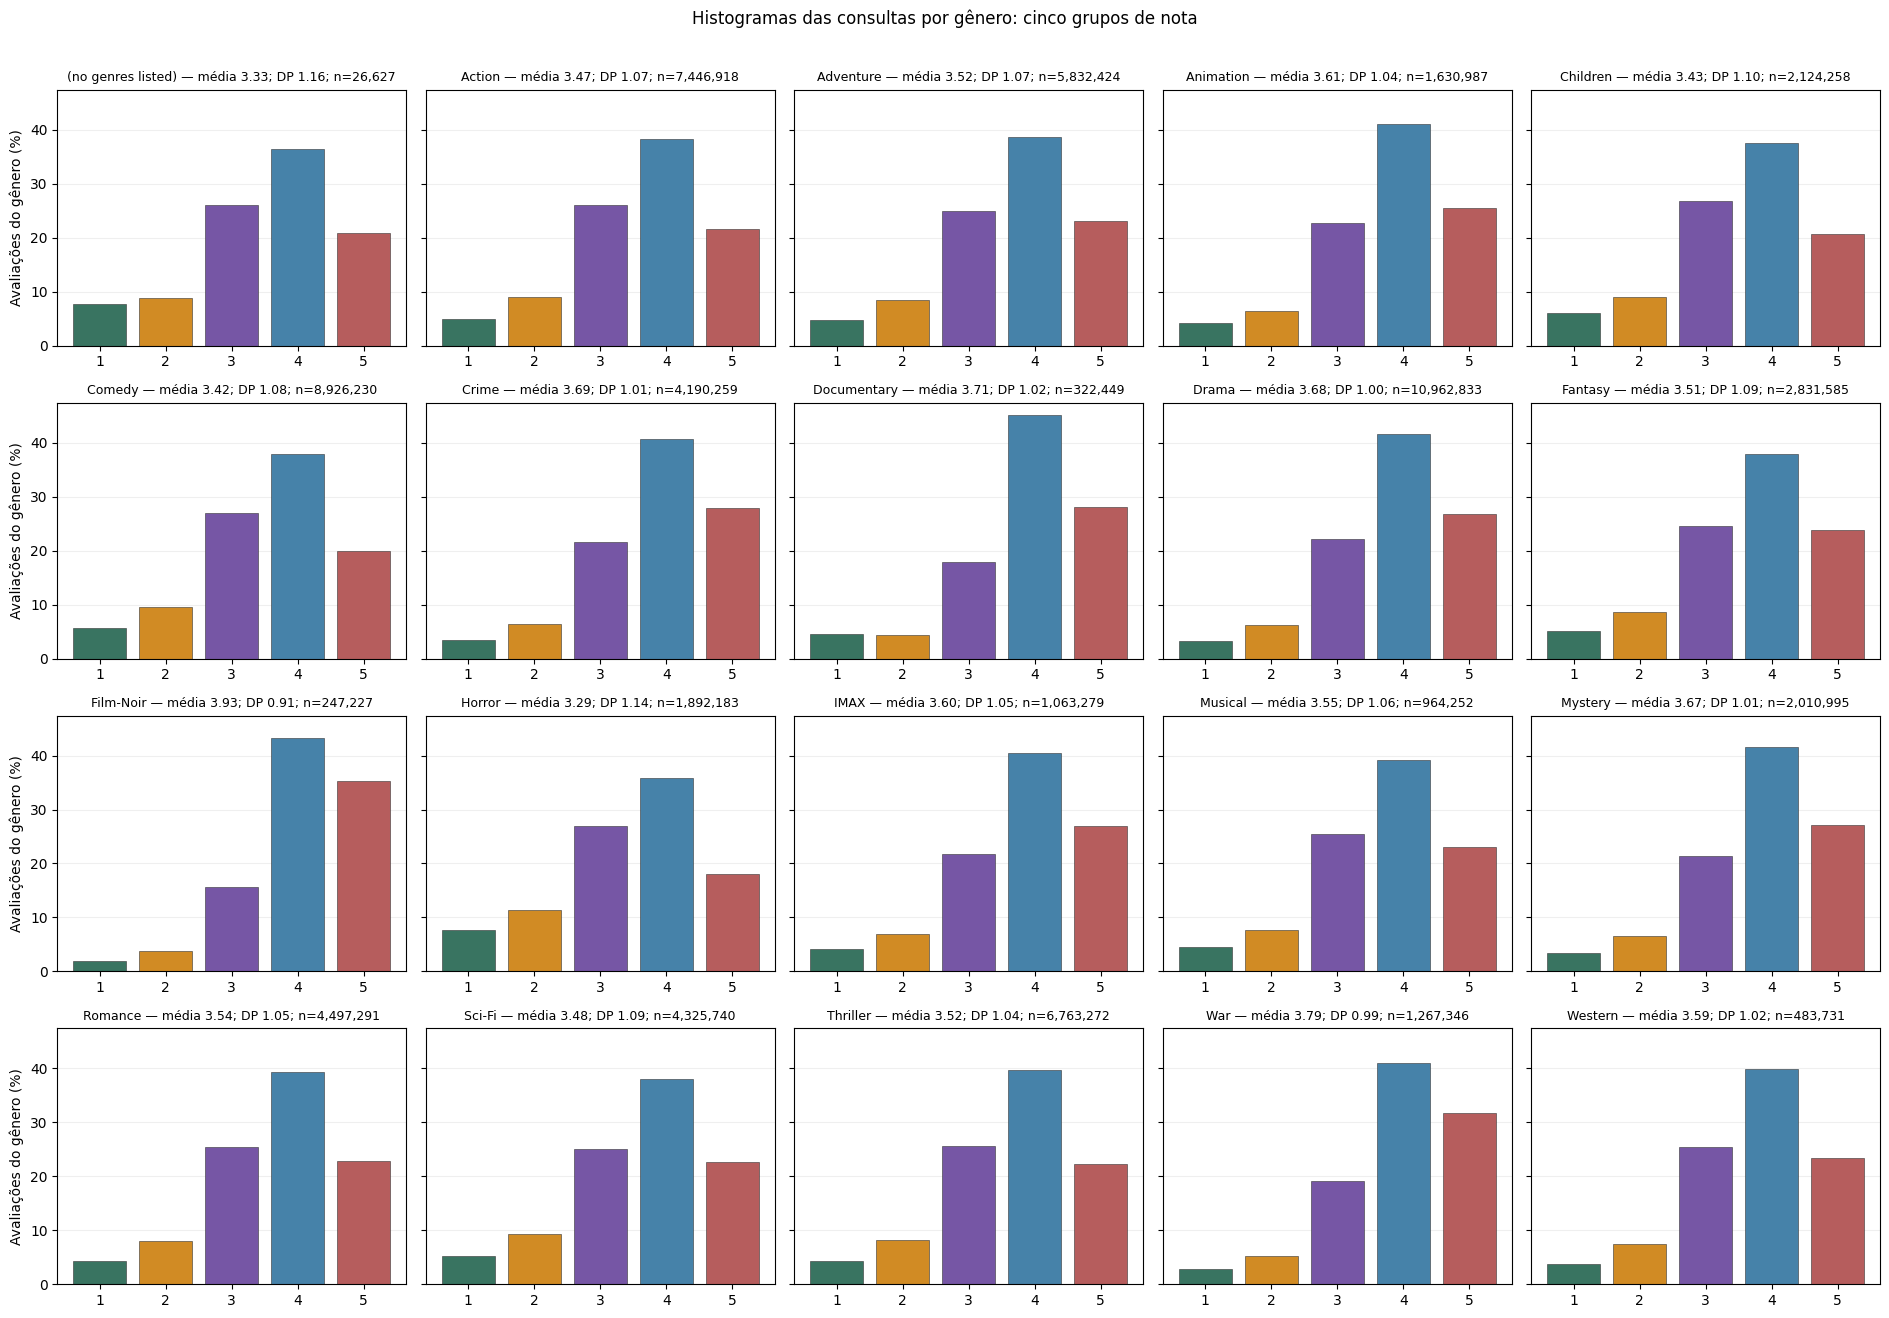

Média por filme: média=3.0714; DP=0.7398; n=59,047
Média por usuário: média=3.6792; DP=0.4774; n=162,541
Avaliações por filme: média=423.39; DP=2477.89; n=59,047
Avaliações por usuário: média=153.81; DP=268.05; n=162,541


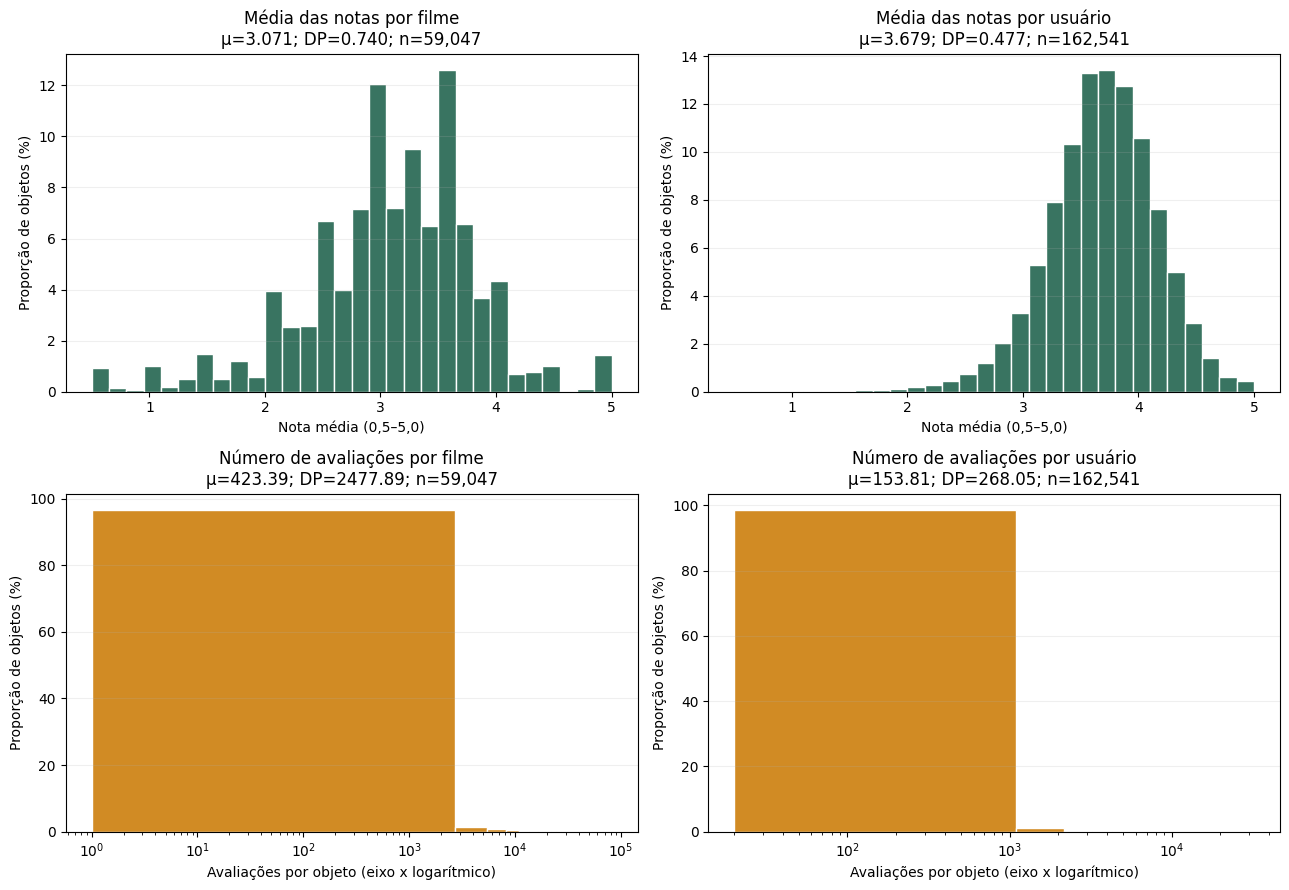

In [16]:
# [1.7-b] Histogramas das consultas por gênero, das médias e do volume por objeto
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

generos_consulta = [r["genre"] for r in movie_genres_sel.select("genre").distinct().orderBy("genre").collect()]
ratings_por_genero = ratings_genres_sel.filter(F.col("genre").isin(generos_consulta))
consulta_5 = (ratings_por_genero.withColumn("grupo_nota", F.ceil("rating").cast("int"))
    .groupBy("genre", "grupo_nota").count())
consulta_totais = consulta_5.groupBy("genre").agg(F.sum("count").alias("total_genero"))
consulta_5_pd = (consulta_5.join(consulta_totais, "genre")
    .withColumn("proporcao_no_genero_pct", F.col("count") / F.col("total_genero") * 100)
    .withColumn("participacao_total_avaliacoes_pct", F.col("count") / F.lit(total_avaliacoes) * 100)
    .withColumn("participacao_expansao_pct", F.col("count") / F.lit(linhas_ratings_genres_sel) * 100)
    .toPandas())
indice_completo = pd.MultiIndex.from_product([generos_consulta, [1, 2, 3, 4, 5]], names=["genre", "grupo_nota"])
consulta_5_pd = consulta_5_pd.set_index(["genre", "grupo_nota"]).reindex(indice_completo, fill_value=0).reset_index()
resumo_consultas = (ratings_por_genero.groupBy("genre")
    .agg(F.count("*").alias("n_avaliacoes"), F.avg("rating").alias("media"), F.stddev("rating").alias("dp"))
    .withColumn("participacao_total_avaliacoes_pct", F.col("n_avaliacoes") / F.lit(total_avaliacoes) * 100)
    .withColumn("participacao_expansao_pct", F.col("n_avaliacoes") / F.lit(linhas_ratings_genres_sel) * 100)
    .orderBy("genre").toPandas())
assert len(generos_consulta) == 20
assert consulta_5_pd.groupby("genre")["grupo_nota"].nunique().eq(5).all()
assert consulta_5_pd.groupby("genre")["proporcao_no_genero_pct"].sum().sub(100).abs().max() < 1e-8
print("Cada histograma usa cinco grupos. Proporções dentro do gênero somam 100%.")
print("A participação no total original usa 25.000.095 avaliações; a participação na expansão usa 67.809.886 linhas avaliação×gênero.")
print("Gêneros se sobrepõem; suas participações no total original podem somar mais de 100%.")
print("Contagens por gênero e grupo de nota:")
print(consulta_5_pd.pivot(index="genre", columns="grupo_nota", values="count").fillna(0).astype(int).to_string())
print("Proporções internas por gênero (%):")
print(consulta_5_pd.pivot(index="genre", columns="grupo_nota", values="proporcao_no_genero_pct").fillna(0).round(2).to_string())
print("Média, DP e participação por consulta:")
print(resumo_consultas.to_string(index=False, formatters={"media": "{:.4f}".format, "dp": "{:.4f}".format,
    "participacao_total_avaliacoes_pct": "{:.4f}%".format, "participacao_expansao_pct": "{:.4f}%".format}))

fig, axes = plt.subplots(4, 5, figsize=(19, 13), sharey=True)
cores = ["#397461", "#d18b24", "#7656a5", "#4682a9", "#b65d5d"]
for ax, genero in zip(axes.flat, generos_consulta):
    dados = consulta_5_pd[consulta_5_pd.genre == genero].sort_values("grupo_nota")
    resumo = resumo_consultas[resumo_consultas.genre == genero].iloc[0]
    ax.bar(dados["grupo_nota"].astype(str), dados["proporcao_no_genero_pct"], color=cores, edgecolor="#333333", linewidth=.4)
    ax.set_title(f"{genero} — média {resumo.media:.2f}; DP {resumo.dp:.2f}; n={int(resumo.n_avaliacoes):,}", fontsize=9)
    ax.set_xticks(range(5), ["1", "2", "3", "4", "5"])
    ax.grid(axis="y", alpha=.2)
    ax.set_axisbelow(True)
for ax in axes[:, 0]: ax.set_ylabel("Avaliações do gênero (%)")
fig.suptitle("Histogramas das consultas por gênero: cinco grupos de nota", y=1.01)
plt.tight_layout()
plt.show()

# Para filmes e usuários, cada barra mostra o percentual dos objetos naquela faixa.
medias_filme = estatisticas_filmes.select("media_avaliacoes").toPandas()["media_avaliacoes"].dropna()
medias_usuario = estatisticas_usuarios.select("media_avaliacoes").toPandas()["media_avaliacoes"].dropna()
contagens_filme = estatisticas_filmes.select("quantidade_avaliacoes").toPandas()["quantidade_avaliacoes"]
contagens_usuario = estatisticas_usuarios.select("quantidade_avaliacoes").toPandas()["quantidade_avaliacoes"]
for nome, valores in [("Média por filme", medias_filme), ("Média por usuário", medias_usuario)]:
    print(f"{nome}: média={valores.mean():.4f}; DP={valores.std(ddof=1):.4f}; n={len(valores):,}")
for nome, valores in [("Avaliações por filme", contagens_filme), ("Avaliações por usuário", contagens_usuario)]:
    print(f"{nome}: média={valores.mean():.2f}; DP={valores.std(ddof=1):.2f}; n={len(valores):,}")
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, valores, nome, cor in [(axes[0,0], medias_filme, "Média das notas por filme", "#397461"),
                                (axes[0,1], medias_usuario, "Média das notas por usuário", "#397461")]:
    ax.hist(valores, bins=30, weights=np.full(len(valores), 100/len(valores)), color=cor, edgecolor="white")
    ax.set_title(f"{nome}\nμ={valores.mean():.3f}; DP={valores.std(ddof=1):.3f}; n={len(valores):,}")
    ax.set_xlabel("Nota média (0,5–5,0)"); ax.set_ylabel("Proporção de objetos (%)"); ax.grid(axis="y", alpha=.2)
for ax, valores, nome, cor in [(axes[1,0], contagens_filme, "Número de avaliações por filme", "#d18b24"),
                                (axes[1,1], contagens_usuario, "Número de avaliações por usuário", "#d18b24")]:
    ax.hist(valores, bins=30, weights=np.full(len(valores), 100/len(valores)), color=cor, edgecolor="white")
    ax.set_xscale("log")
    ax.set_title(f"{nome}\nμ={valores.mean():.2f}; DP={valores.std(ddof=1):.2f}; n={len(valores):,}")
    ax.set_xlabel("Avaliações por objeto (eixo x logarítmico)"); ax.set_ylabel("Proporção de objetos (%)"); ax.grid(axis="y", alpha=.2)
plt.tight_layout()
plt.show()

**Leitura dos resultados.**

- **Por gênero:**
  - a média varia de 3,29 (Horror) a 3,93 (Film-Noir), cerca de 0,6 ponto entre os extremos;
  - gêneros de nicho e clássicos (Film-Noir, War, Documentary) têm média maior e desvio-padrão menor; Horror, Comedy e Children, média menor e desvio maior;
  - nos histogramas, o grupo 5 representa 35,34% das avaliações de Film-Noir e 18,06% das de Horror.
- **Por filme (suporte ≥ 50 avaliações):** os primeiros lugares misturam documentários de natureza, como Planet Earth II (4,48; 1.124 avaliações), e clássicos muito avaliados, como The Shawshank Redemption (4,41; 81.482 avaliações).
- **Média entre objetos:** a média das médias por filme (3,07) é bem menor que a média das médias por usuário (3,68). Cada objeto pesa igual: há muitos filmes pouco avaliados com médias baixas, enquanto os usuários avaliam sobretudo filmes populares e bem avaliados.
- **Volume:** o desvio-padrão do número de avaliações supera a média (filmes: 423,4 ± 2.477,9; usuários: 153,8 ± 268,1). Isso indica cauda longa; por isso os histogramas de volume usam eixo logarítmico.

#### Consultas com filtro

Além dos gêneros, cada consulta compara dois grupos de avaliações com o mesmo histograma de cinco grupos de nota:

- filmes populares (1% mais avaliados) × filmes de nicho (até a mediana de avaliações por filme);
- filmes antigos (antes de 1970) × recentes (2010 em diante), pelo ano do título;
- avaliações feitas antes de 2003 × a partir de 2003, quando surgiram as notas de meio ponto;
- usuários pouco ativos (25% com menos avaliações) × muito ativos (25% com mais);
- filmes sem gênero informado × com gênero.

Cada histograma usa as avaliações do grupo como denominador, e a legenda traz média, desvio-padrão e número de avaliações. A diferença entre os grupos também é medida pelo d de Cohen (diferença de médias dividida pelo desvio-padrão combinado), porque com milhões de avaliações qualquer diferença seria estatisticamente significativa.

Filmes de nicho: até 6 avaliações (mediana); populares: 9943 ou mais (1% mais avaliados)
Usuários pouco ativos: até 36 avaliações (Q1); muito ativos: 162 ou mais (Q3)


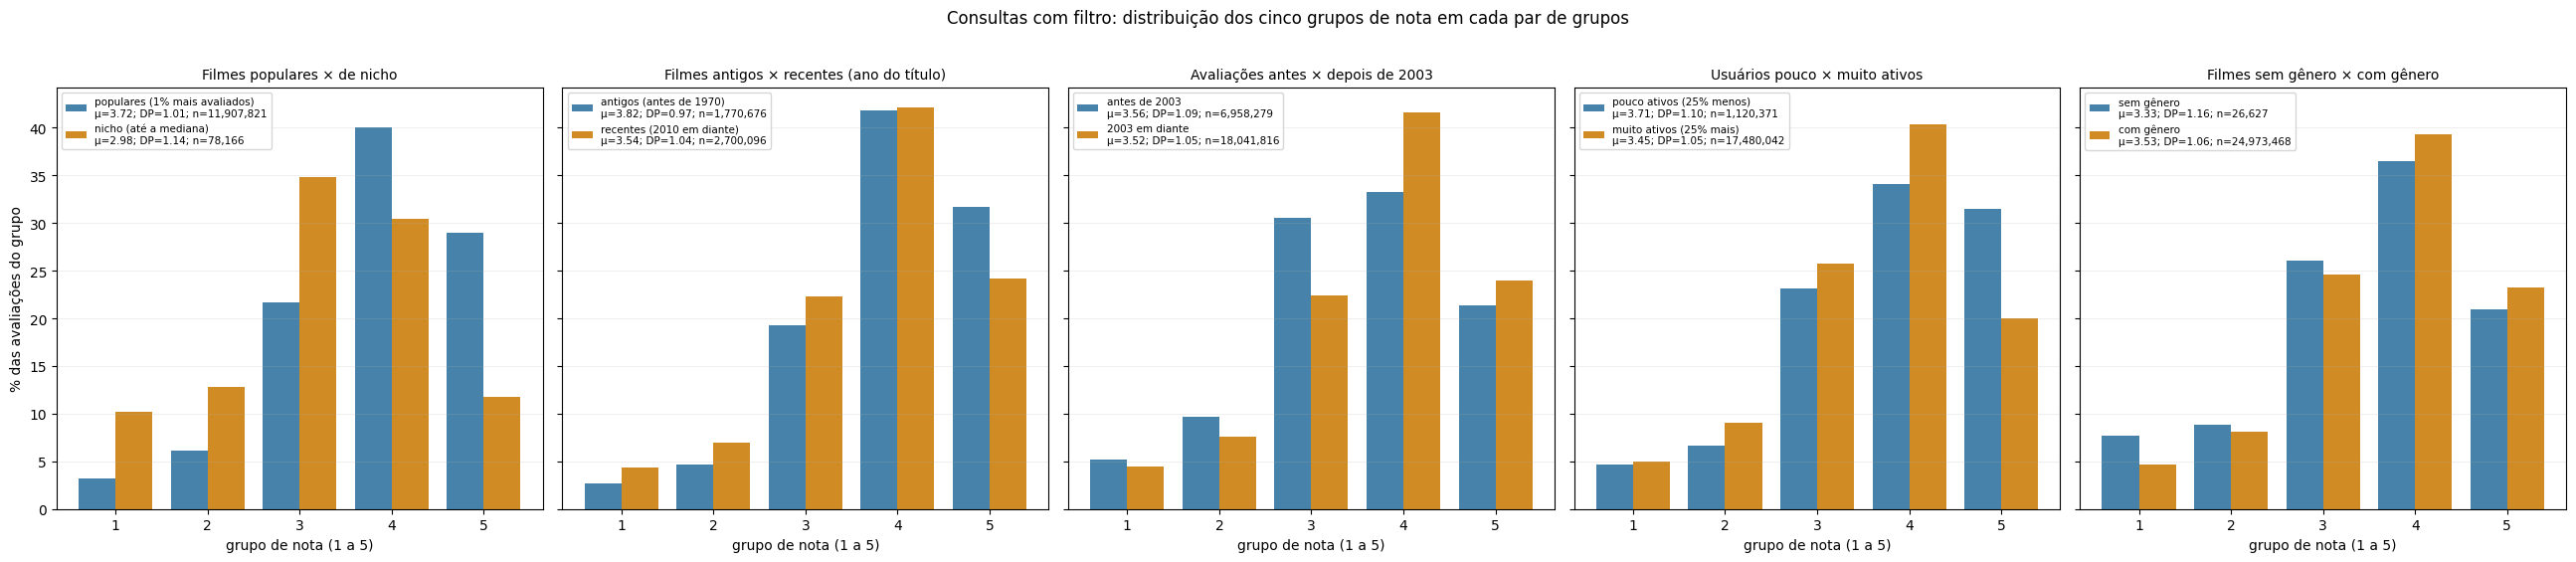

Denominador de cada histograma = avaliações do grupo; %_do_total usa 25.000.095 avaliações.
                                 consulta                         grupo  n_avaliacoes  %_do_total  média   DP  g1_%  g2_%  g3_%  g4_%  g5_%
              Filmes populares × de nicho populares (1% mais avaliados)      11907821       47.63   3.72 1.01  3.20  6.10 21.67 40.02 29.02
              Filmes populares × de nicho         nicho (até a mediana)         78166        0.31   2.98 1.14 10.23 12.78 34.84 30.42 11.73
Filmes antigos × recentes (ano do título)       antigos (antes de 1970)       1770676        7.08   3.82 0.97  2.64  4.65 19.27 41.76 31.68
Filmes antigos × recentes (ano do título)     recentes (2010 em diante)       2700096       10.80   3.54 1.04  4.39  6.99 22.30 42.12 24.20
        Avaliações antes × depois de 2003                 antes de 2003       6958279       27.83   3.56 1.09  5.22  9.67 30.54 33.25 21.32
        Avaliações antes × depois de 2003                2003 em dia

In [17]:
# [1.7-c] Consultas com filtro: histogramas de cinco grupos de nota, com média e desvio-padrão
q_volume_filme = estatisticas_filmes.approxQuantile("quantidade_avaliacoes", [0.5, 0.99], 0.0)
q_volume_usuario = estatisticas_usuarios.approxQuantile("quantidade_avaliacoes", [0.25, 0.75], 0.0)
LIMITE_NICHO, LIMITE_POPULAR = q_volume_filme
LIMITE_POUCO_ATIVO, LIMITE_MUITO_ATIVO = q_volume_usuario
ANO_ANTIGO, ANO_RECENTE, ANO_MEIO_PONTO = 1970, 2010, 2003
print(f"Filmes de nicho: até {LIMITE_NICHO:.0f} avaliações (mediana); populares: {LIMITE_POPULAR:.0f} ou mais (1% mais avaliados)")
print(f"Usuários pouco ativos: até {LIMITE_POUCO_ATIVO:.0f} avaliações (Q1); muito ativos: {LIMITE_MUITO_ATIVO:.0f} ou mais (Q3)")

ROTULOS = {
    "popular": "populares (1% mais avaliados)", "nicho": "nicho (até a mediana)",
    "antigo": f"antigos (antes de {ANO_ANTIGO})", "recente": f"recentes ({ANO_RECENTE} em diante)",
    "antes": f"antes de {ANO_MEIO_PONTO}", "depois": f"{ANO_MEIO_PONTO} em diante",
    "pouco": "pouco ativos (25% menos)", "muito": "muito ativos (25% mais)",
    "sem": "sem gênero", "com": "com gênero",
}
filmes_consulta = (estatisticas_filmes.select("movieId", "quantidade_avaliacoes")
    .join(movies_sel.select("movieId", "title", "genres"), "movieId")
    .withColumn("ano_txt", F.regexp_extract(F.trim(F.col("title")), r"\((\d{4})\)$", 1))
    .withColumn("ano_lanc", F.when(F.col("ano_txt") != "", F.col("ano_txt").cast("int")))
    .select("movieId",
            F.when(F.col("quantidade_avaliacoes") >= LIMITE_POPULAR, ROTULOS["popular"])
             .when(F.col("quantidade_avaliacoes") <= LIMITE_NICHO, ROTULOS["nicho"])
             .otherwise("intermediário").alias("popularidade"),
            F.when(F.col("ano_lanc") < ANO_ANTIGO, ROTULOS["antigo"])
             .when(F.col("ano_lanc") >= ANO_RECENTE, ROTULOS["recente"])
             .when(F.col("ano_lanc").isNotNull(), "intermediário").otherwise("sem ano").alias("epoca"),
            F.when(F.col("genres") == "(no genres listed)", ROTULOS["sem"]).otherwise(ROTULOS["com"]).alias("genero_informado")))
usuarios_consulta = estatisticas_usuarios.select("userId",
    F.when(F.col("quantidade_avaliacoes") <= LIMITE_POUCO_ATIVO, ROTULOS["pouco"])
     .when(F.col("quantidade_avaliacoes") >= LIMITE_MUITO_ATIVO, ROTULOS["muito"])
     .otherwise("intermediário").alias("atividade"))
# Uma única passagem pelas avaliações: contagem, soma e soma dos quadrados por combinação de filtros e grupo de nota.
tabela_consultas = (ratings_sel
    .join(F.broadcast(filmes_consulta), "movieId")
    .join(usuarios_consulta, "userId")
    .withColumn("periodo", F.when(F.year(F.from_unixtime("timestamp")) < ANO_MEIO_PONTO, ROTULOS["antes"])
                .otherwise(ROTULOS["depois"]))
    .withColumn("grupo_nota", F.ceil("rating").cast("int"))
    .groupBy("popularidade", "epoca", "genero_informado", "atividade", "periodo", "grupo_nota")
    .agg(F.count("*").alias("n"), F.sum("rating").alias("soma"), F.sum(F.col("rating") * F.col("rating")).alias("soma_q"))
    .toPandas())
assert int(tabela_consultas["n"].sum()) == total_avaliacoes

DEFINICAO_CONSULTAS = [
    ("popularidade", ("popular", "nicho"), "Filmes populares × de nicho"),
    ("epoca", ("antigo", "recente"), "Filmes antigos × recentes (ano do título)"),
    ("periodo", ("antes", "depois"), f"Avaliações antes × depois de {ANO_MEIO_PONTO}"),
    ("atividade", ("pouco", "muito"), "Usuários pouco × muito ativos"),
    ("genero_informado", ("sem", "com"), "Filmes sem gênero × com gênero"),
]
linhas_consulta, efeitos = [], []
fig, axes = plt.subplots(1, 5, figsize=(26, 5.5), sharey=True)
for ax, (coluna, chaves, titulo) in zip(axes, DEFINICAO_CONSULTAS):
    resumo_grupos = []
    for j, chave in enumerate(chaves):
        parte = tabela_consultas[tabela_consultas[coluna] == ROTULOS[chave]]
        n = int(parte["n"].sum())
        media = parte["soma"].sum() / n
        dp = ((parte["soma_q"].sum() - n * media ** 2) / (n - 1)) ** 0.5
        hist = parte.groupby("grupo_nota")["n"].sum().reindex([1, 2, 3, 4, 5], fill_value=0) / n * 100
        ax.bar(np.arange(1, 6) + (j - 0.5) * 0.4, hist.values, width=0.4, color=("#4682a9", "#d18b24")[j],
               label=f"{ROTULOS[chave]}\nμ={media:.2f}; DP={dp:.2f}; n={n:,}")
        linhas_consulta.append((titulo, ROTULOS[chave], n, 100 * n / total_avaliacoes, media, dp, *hist.values))
        resumo_grupos.append((n, media, dp))
    (n1, m1, s1), (n2, m2, s2) = resumo_grupos
    dp_combinado = (((n1 - 1) * s1 ** 2 + (n2 - 1) * s2 ** 2) / (n1 + n2 - 2)) ** 0.5
    efeitos.append((titulo, m1 - m2, (m1 - m2) / dp_combinado))
    ax.set_title(titulo, fontsize=10)
    ax.set_xticks(range(1, 6))
    ax.set_xlabel("grupo de nota (1 a 5)")
    ax.legend(fontsize=7.5, loc="upper left")
    ax.grid(axis="y", alpha=.2)
axes[0].set_ylabel("% das avaliações do grupo")
fig.suptitle("Consultas com filtro: distribuição dos cinco grupos de nota em cada par de grupos", y=1.02)
plt.tight_layout()
plt.show()

tabela_consulta = pd.DataFrame(linhas_consulta, columns=["consulta", "grupo", "n_avaliacoes", "%_do_total", "média", "DP",
                                                         "g1_%", "g2_%", "g3_%", "g4_%", "g5_%"])
print("Denominador de cada histograma = avaliações do grupo; %_do_total usa 25.000.095 avaliações.")
print(tabela_consulta.round(2).to_string(index=False))
print("\nDiferença de médias entre os dois grupos de cada consulta e d de Cohen (diferença / DP combinado):")
print(pd.DataFrame(efeitos, columns=["consulta", "diferença de médias", "d de Cohen"]).round(3).to_string(index=False))

**Leitura dos resultados.**

- **Popularidade:** é o filtro com maior efeito. Os filmes populares (1% mais avaliados, com 9.943 avaliações ou mais) têm média 3,72 e somam 47,6% de todas as avaliações; os de nicho (até 6 avaliações) têm média 2,98 e 10,2% de notas no grupo 1. O d de Cohen é 0,73, perto de um efeito grande.
- **Época do filme:** filmes antigos (antes de 1970) têm média 3,82, contra 3,54 dos recentes (d = 0,28).
- **Atividade do usuário:** os 25% menos ativos (até 36 avaliações) dão média 3,71; os 25% mais ativos (162 ou mais) dão 3,45 e respondem por 69,9% das avaliações (d = 0,24).
- **Filmes sem gênero:** média 3,33, contra 3,53 dos demais (d = −0,20), em apenas 0,11% das avaliações.
- **Antes × depois de 2003:** médias quase iguais (3,56 × 3,52; d = 0,03). A mudança de escala altera a forma do histograma (menos notas no grupo 3, mais no 4), não a média.

**Limitação:** popularidade e nota se influenciam mutuamente: filmes bons atraem avaliações. A consulta descreve a associação, não a causa.

**Consequência:** a popularidade dos filmes vistos é um atributo derivado relevante do usuário e entra no vetor revisado (3.8).

### 1.8 Exploração multivariada

No MovieLens, as colunas brutas são identificadores, texto, categorias ou a própria nota. Por isso, a análise multivariada usa atributos derivados por usuário e por filme, com denominadores explícitos, como orientado pelo professor.

A ordem de apresentação é: covariância, razão de correlação, Pearson, Spearman e visualização por matriz de dispersão. A correlação não demonstra causalidade.

Nesta etapa, o perfil de usuário usa um conjunto compacto de atributos. O perfil completo, com os 20 gêneros, é construído na transformação (3.1) a partir dos dados tratados.

**Escala e proporção antes das matrizes.** Antes de cada matriz, todos os atributos são levados para [0, 1]: contagens divididas pelo máximo, nota pela posição na escala de 0,5 a 5,0, desvio-padrão pelo maior valor observado e ano entre o primeiro e o último ano. As proporções já estão nesse intervalo. Assim, a covariância fica comparável entre atributos; a covariância na escala original aparece como consulta. Pearson e Spearman não mudam com essas transformações lineares.

Usuários: 162541
Soma de prop_avaliacoes_total: 1.0
Atributos de usuário em escala [0, 1]:
                  mean     std     50%     min  max
atividade_rel   0.0048  0.0083  0.0022  0.0006  1.0
nota_media_rel  0.7065  0.1061  0.7111  0.0000  1.0
nota_dp_rel     0.4023  0.1132  0.3932  0.0000  1.0
prop_positivas  0.5688  0.1996  0.5763  0.0000  1.0
prop_action     0.3135  0.1493  0.3030  0.0000  1.0
prop_comedy     0.3475  0.1333  0.3415  0.0000  1.0
prop_drama      0.4424  0.1398  0.4327  0.0000  1.0
Covariância na escala [0, 1] (comparável entre atributos):
                atividade_rel  nota_media_rel  nota_dp_rel  prop_positivas  prop_action  prop_comedy  prop_drama
atividade_rel         0.00007        -0.00015     -0.00002        -0.00034     -0.00007      0.00005    -0.00002
nota_media_rel       -0.00015         0.01125     -0.00570         0.01953      0.00092     -0.00244     0.00183
nota_dp_rel          -0.00002        -0.00570      0.01283        -0.00680     -0.00163      0.

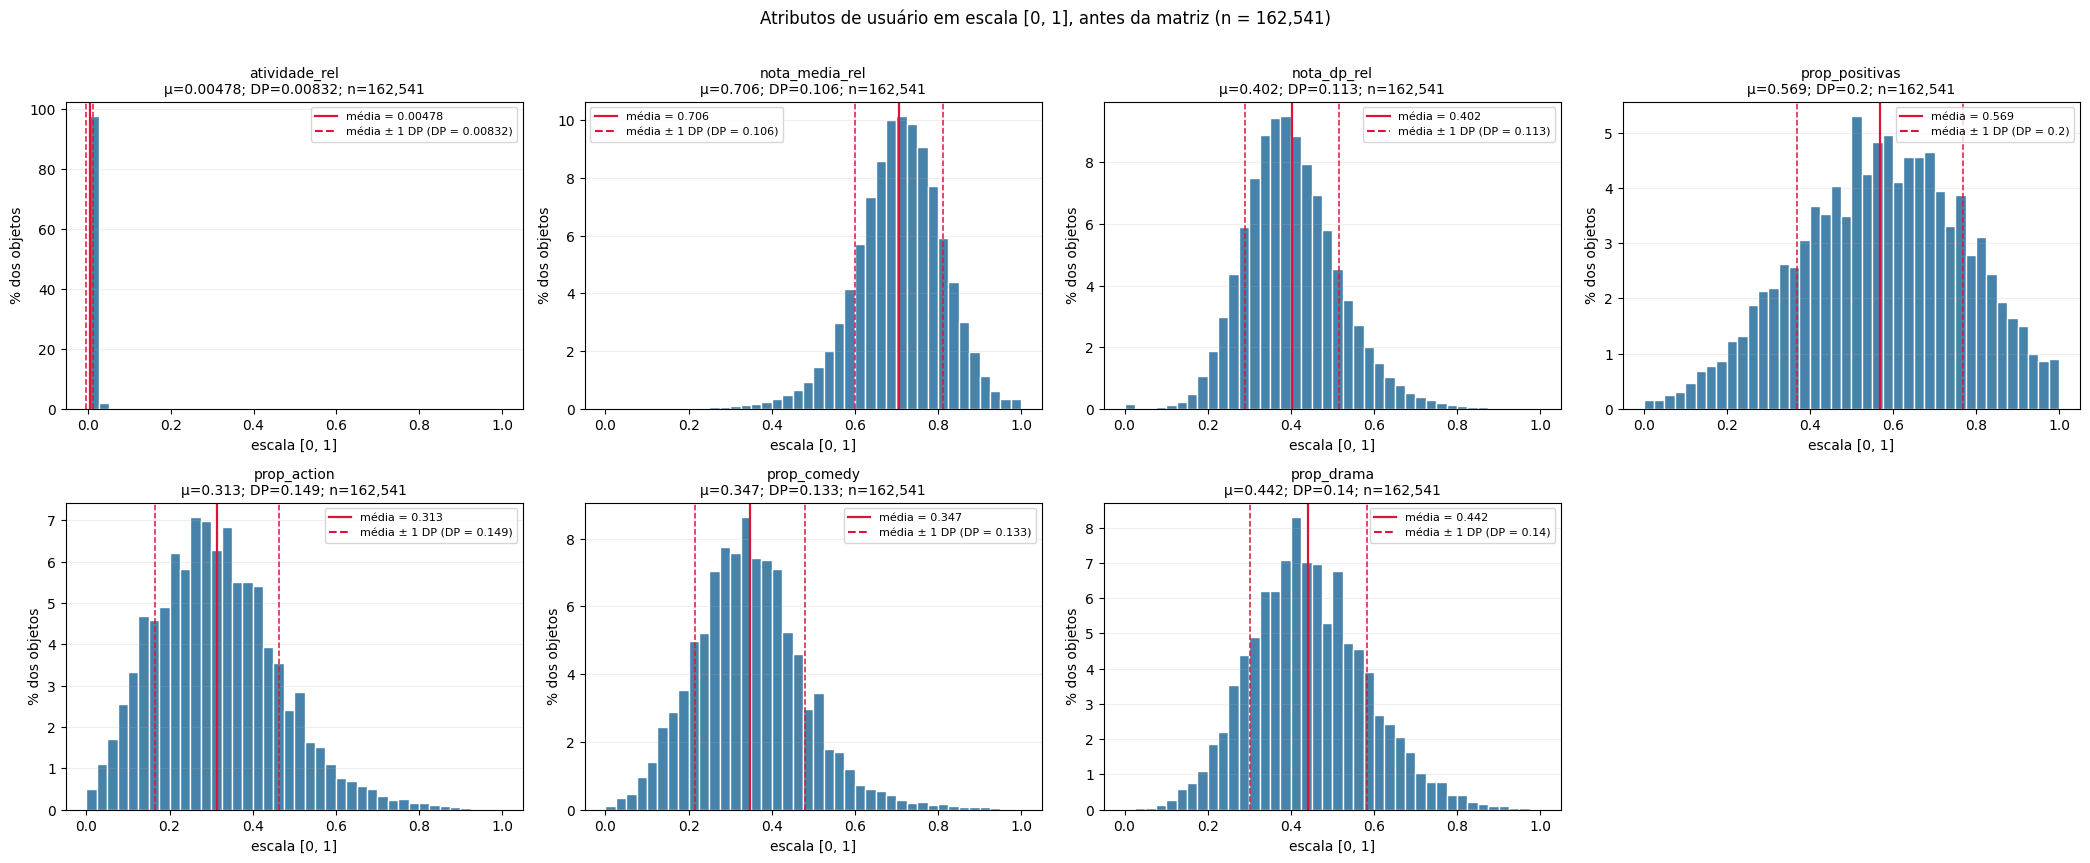

Pearson:
                        prop_avaliacoes_total  nota_media  nota_dp  prop_positivas  prop_action  prop_comedy  prop_drama
prop_avaliacoes_total                  1.000      -0.175   -0.020          -0.203       -0.060        0.041      -0.016
nota_media                            -0.175       1.000   -0.474           0.922        0.058       -0.172       0.123
nota_dp                               -0.020      -0.474    1.000          -0.301       -0.096        0.136      -0.067
prop_positivas                        -0.203       0.922   -0.301           1.000        0.029       -0.163       0.137
prop_action                           -0.060       0.058   -0.096           0.029        1.000       -0.418      -0.518
prop_comedy                            0.041      -0.172    0.136          -0.163       -0.418        1.000      -0.265
prop_drama                            -0.016       0.123   -0.067           0.137       -0.518       -0.265       1.000
Spearman:
                    

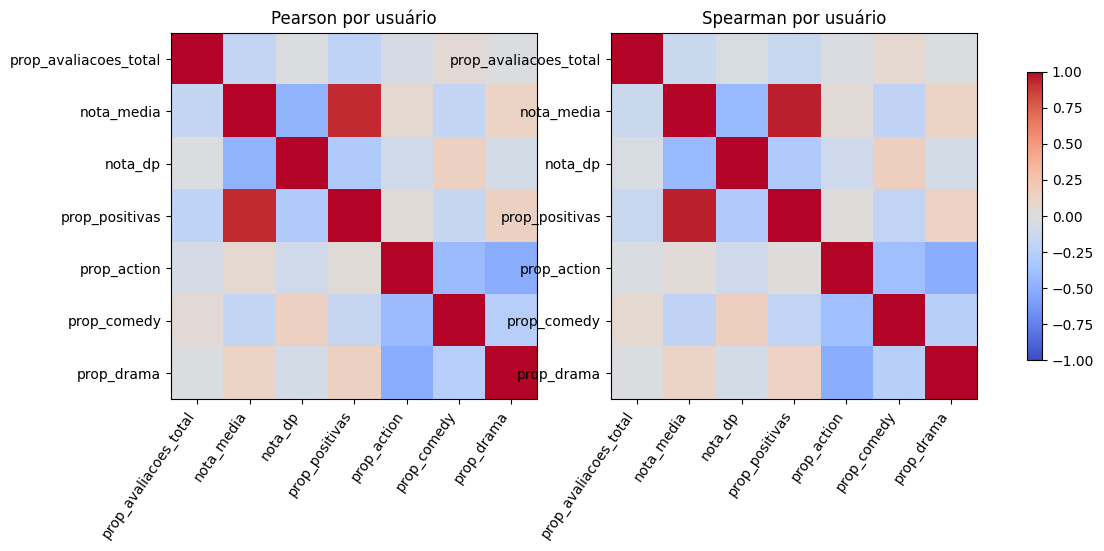

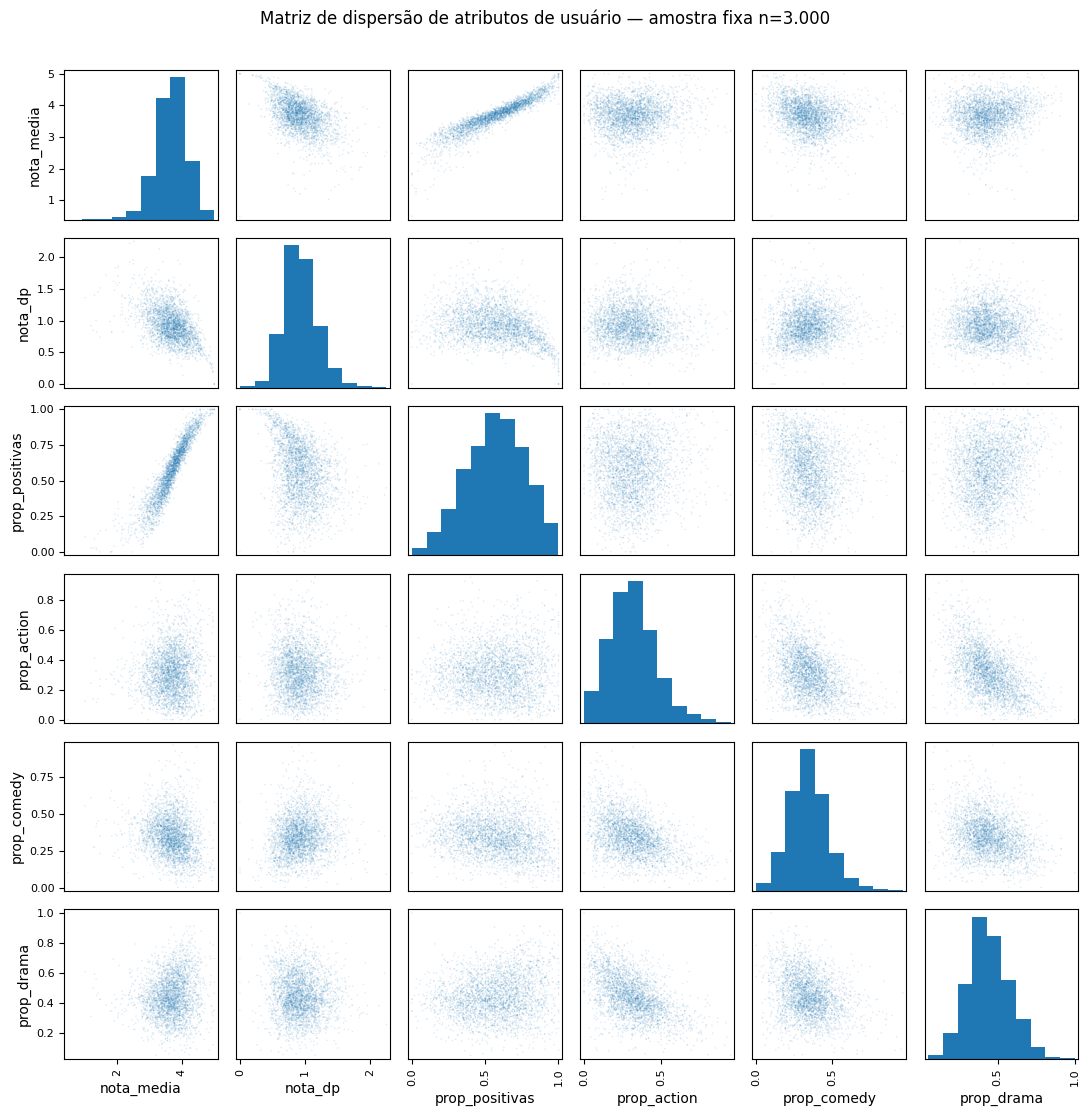

In [18]:
# [1.8-a] Covariância, Pearson e Spearman no grão de usuário e matriz de dispersão
# Denominadores: prop_avaliacoes_total = avaliações do usuário / total de avaliações;
# prop_positivas = avaliações do usuário com nota >= 4 / avaliações do usuário;
# prop_<gênero> = avaliações do usuário em filmes do gênero / avaliações do usuário.
usuarios_base = (ratings_sel.groupBy("userId").agg(
    F.count("*").alias("n_avaliacoes"), F.avg("rating").alias("nota_media"),
    F.stddev("rating").alias("nota_dp"),
    F.avg(F.when(F.col("rating") >= 4, 1.0).otherwise(0.0)).alias("prop_positivas"))
    .withColumn("prop_avaliacoes_total", F.col("n_avaliacoes") / F.lit(total_avaliacoes)))
generos_usuario = ratings_genres_sel.groupBy("userId").agg(*[
    F.sum(F.when(F.col("genre") == genero, 1).otherwise(0)).alias("n_" + genero.lower())
    for genero in ("Action", "Comedy", "Drama")])
usuarios_features = usuarios_base.join(generos_usuario, "userId", "left")
for genero in ("action", "comedy", "drama"):
    usuarios_features = usuarios_features.withColumn("prop_" + genero,
        F.coalesce(F.col("n_" + genero), F.lit(0)) / F.col("n_avaliacoes"))
atributos = ["prop_avaliacoes_total", "nota_media", "nota_dp", "prop_positivas",
             "prop_action", "prop_comedy", "prop_drama"]
usuarios_pd = usuarios_features.select("userId", *atributos).toPandas()
assert len(usuarios_pd) == usuarios_pd.userId.nunique() == 162541
assert usuarios_pd[atributos].notna().all().all()
assert usuarios_pd[[c for c in atributos if c.startswith("prop_")]].le(1).all().all()
assert abs(usuarios_pd["prop_avaliacoes_total"].sum() - 1) < 1e-10

covariancia = usuarios_pd[atributos].cov()
pearson = usuarios_pd[atributos].corr(method="pearson")
spearman = usuarios_pd[atributos].corr(method="spearman")
assert np.allclose(pearson.values, pearson.values.T)
assert np.allclose(spearman.values, spearman.values.T)
print("Usuários:", len(usuarios_pd))
print("Soma de prop_avaliacoes_total:", usuarios_pd["prop_avaliacoes_total"].sum())
# Escala e proporção antes da matriz: cada atributo vai para [0, 1] pelo seu domínio.
#   atividade_rel = avaliações do usuário / avaliações do usuário mais ativo (= prop_avaliacoes_total / máximo);
#   nota_media_rel = (nota_media − 0,5) / 4,5, a posição na escala de 0,5 a 5,0;
#   nota_dp_rel = nota_dp / maior DP observado; as proporções já estão em [0, 1].
usuarios_escala = pd.DataFrame({
    "atividade_rel": usuarios_pd["prop_avaliacoes_total"] / usuarios_pd["prop_avaliacoes_total"].max(),
    "nota_media_rel": (usuarios_pd["nota_media"] - 0.5) / 4.5,
    "nota_dp_rel": usuarios_pd["nota_dp"] / usuarios_pd["nota_dp"].max(),
    "prop_positivas": usuarios_pd["prop_positivas"],
    "prop_action": usuarios_pd["prop_action"],
    "prop_comedy": usuarios_pd["prop_comedy"],
    "prop_drama": usuarios_pd["prop_drama"],
})
assert usuarios_escala.min().min() >= 0 and usuarios_escala.max().max() <= 1 + 1e-12
print("Atributos de usuário em escala [0, 1]:")
print(usuarios_escala.describe().T[["mean", "std", "50%", "min", "max"]].round(4).to_string())
print("Covariância na escala [0, 1] (comparável entre atributos):")
print(usuarios_escala.cov().round(5).to_string())
print("Covariância na escala original (consulta; as unidades diferem entre atributos):")
print(covariancia.to_string(float_format=lambda x: f"{x:.6g}"))
fig, axes = plt.subplots(2, 4, figsize=(21, 8.5))
for ax, coluna in zip(axes.flat, usuarios_escala.columns):
    histograma_media_dp(ax, usuarios_escala[coluna], coluna, bins=40, rotulo_x="escala [0, 1]")
axes.flat[-1].axis("off")
fig.suptitle(f"Atributos de usuário em escala [0, 1], antes da matriz (n = {len(usuarios_escala):,})", y=1.01)
plt.tight_layout()
plt.show()
print("Pearson:\n", pearson.round(3).to_string())
print("Spearman:\n", spearman.round(3).to_string())
pares = [(a, b, pearson.loc[a, b], spearman.loc[a, b]) for i, a in enumerate(atributos) for b in atributos[i + 1:]]
for a, b, r, rho in sorted(pares, key=lambda x: abs(x[2]), reverse=True)[:5]:
    print(f"{a} × {b}: Pearson={r:.3f}; Spearman={rho:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, matriz, titulo in zip(axes, (pearson, spearman), ("Pearson", "Spearman")):
    imagem = ax.imshow(matriz, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(atributos)), atributos, rotation=55, ha="right")
    ax.set_yticks(range(len(atributos)), atributos)
    ax.set_title(titulo + " por usuário")
fig.colorbar(imagem, ax=axes, shrink=.75)
plt.show()

# Matriz de dispersão em amostra fixa de 3.000 usuários; a representatividade é verificada em 2.4.
cols_grafico = ["nota_media", "nota_dp", "prop_positivas", "prop_action", "prop_comedy", "prop_drama"]
amostra_scatter = usuarios_pd[cols_grafico].sample(n=min(3000, len(usuarios_pd)), random_state=42)
pd.plotting.scatter_matrix(amostra_scatter, figsize=(11, 11), diagonal="hist", alpha=0.15, s=5)
plt.suptitle("Matriz de dispersão de atributos de usuário — amostra fixa n=3.000", y=1.01)
plt.tight_layout()
plt.show()

**Leitura dos resultados.**

- **Média × proporção positiva:** associação muito forte (Pearson 0,922; Spearman 0,946). As duas medem a generosidade do usuário.
- **Composição de gêneros:** as proporções competem entre si: Action × Drama (−0,52) e Action × Comedy (−0,42). Quem avalia proporcionalmente mais ação avalia proporcionalmente menos drama e comédia; parte desse efeito vem do próprio uso de proporções.
- **Média × desvio da nota:** −0,47. Usuários com média maior tendem a variar menos.
- **Atividade:** `prop_avaliacoes_total` se associa pouco à média (−0,17 / −0,13); usuários muito ativos dão notas ligeiramente menores.
- **Pearson × Spearman:** os valores são próximos, o que indica relações aproximadamente lineares.

- **Escala [0, 1]:** a atividade tem média 0,0048 e mediana 0,0022. Quase todos os usuários ficam perto de zero, porque o mais ativo tem 32.202 avaliações. Na escala comparável, as maiores variâncias são da proporção positiva (0,040) e das proporções de gênero (0,018 a 0,022), e a maior covariância fora da diagonal é entre nota média e proporção positiva (0,0195), coerente com a correlação de 0,922. Na escala original, as variâncias iam de 1,1×10⁻¹⁰ a 0,23 e não permitiam essa comparação.

#### Covariância e correlações no grão de filme

Cada linha representa um filme, com participação no total de avaliações, média, desvio-padrão e ano de lançamento. A participação é n_avaliacoes / total_avaliacoes. O ano é extraído do título. Filmes sem ano ou sem desvio-padrão calculável ficam fora desta matriz, e essa população é informada na saída.

Filmes incluídos (ano e DP disponíveis): 48,398
Denominador da proporção: 25,000,095 avaliações válidas
Matriz por filme usa a participação no total, a média, o DP e o ano; a contagem bruta fica para consulta.
Atributos de filme em escala [0, 1] (ano: 1874 = 0 e 2019 = 1):
                 mean     std     50%  min  max
atividade_rel  0.0063  0.0335  0.0001  0.0  1.0
media_rel      0.5772  0.1387  0.5960  0.0  1.0
dp_rel         0.2999  0.1323  0.3023  0.0  1.0
ano_rel        0.8262  0.1688  0.8897  0.0  1.0
Covariância por filme na escala [0, 1] (comparável entre atributos):
               atividade_rel  media_rel   dp_rel  ano_rel
atividade_rel        0.00112    0.00061 -0.00000  0.00002
media_rel            0.00061    0.01925 -0.00314 -0.00063
dp_rel              -0.00000   -0.00314  0.01750  0.00286
ano_rel              0.00002   -0.00063  0.00286  0.02850
Covariância por filme na escala original (consulta):
                       prop_avaliacoes_total  media_nota      dp_nota  ano

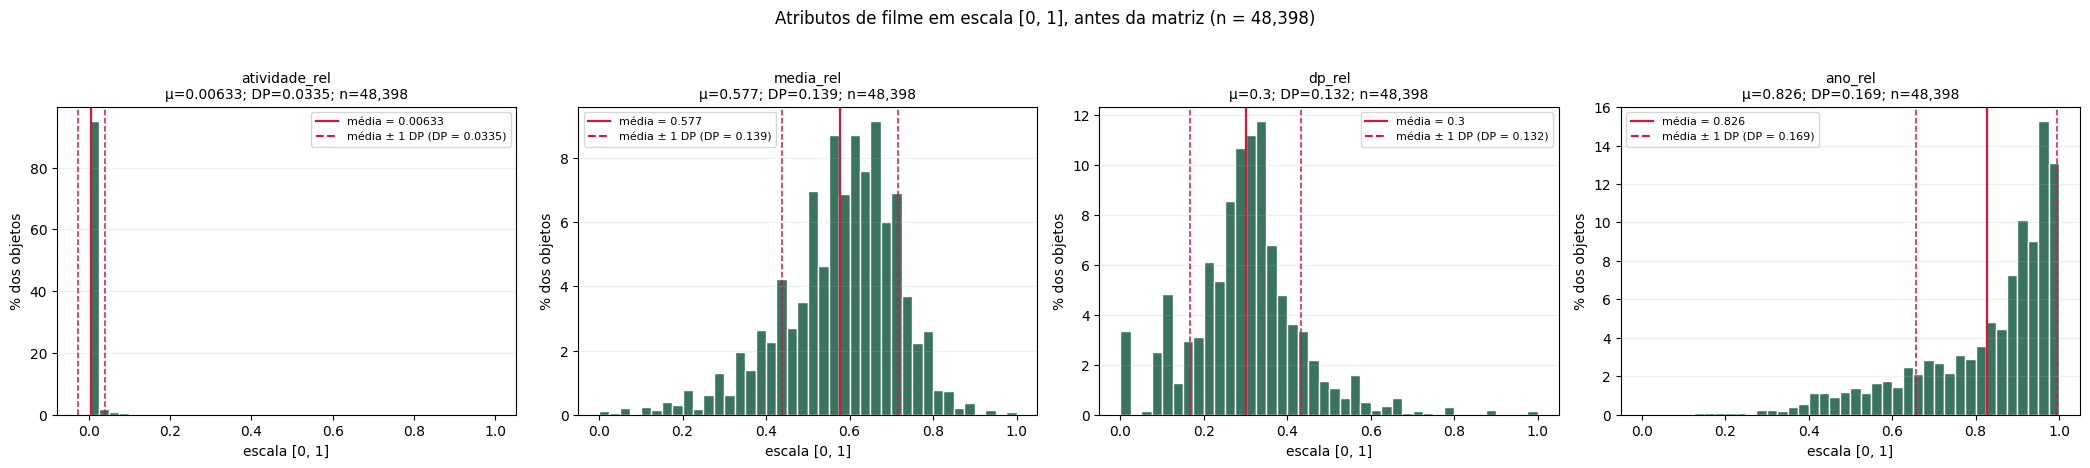

Pearson por filme:
                       prop_avaliacoes_total  media_nota  dp_nota  ano_lancamento
prop_avaliacoes_total                  1.000       0.132   -0.001           0.004
media_nota                             0.132       1.000   -0.171          -0.027
dp_nota                               -0.001      -0.171    1.000           0.128
ano_lancamento                         0.004      -0.027    0.128           1.000
Spearman por filme:
                       prop_avaliacoes_total  media_nota  dp_nota  ano_lancamento
prop_avaliacoes_total                  1.000       0.179    0.184          -0.045
media_nota                             0.179       1.000   -0.234          -0.024
dp_nota                                0.184      -0.234    1.000           0.117
ano_lancamento                        -0.045      -0.024    0.117           1.000


In [19]:
# [1.8-b] Covariância, Pearson e Spearman no grão de filme
# A participação de avaliações usa como denominador o total global de avaliações válidas.
filmes_cov_spark = (
    ratings_movies_sel.groupBy("movieId", "title")
    .agg(
        F.count("*").alias("n_avaliacoes"),
        F.avg("rating").alias("media_nota"),
        F.stddev("rating").alias("dp_nota"),
    )
    .withColumn("prop_avaliacoes_total", F.col("n_avaliacoes") / F.lit(total_avaliacoes))
    .withColumn("ano_texto", F.regexp_extract(F.col("title"), r"\((\d{4})\)$", 1))
    .withColumn("ano_lancamento", F.when(F.col("ano_texto") != "", F.col("ano_texto").cast("double")))
    .select("movieId", "n_avaliacoes", "prop_avaliacoes_total", "media_nota", "dp_nota", "ano_lancamento")
)
filmes_cov_pd = filmes_cov_spark.toPandas().dropna()
atributos_filme_cov = ["prop_avaliacoes_total", "media_nota", "dp_nota", "ano_lancamento"]
assert len(filmes_cov_pd) == filmes_cov_pd["movieId"].nunique() > 1
assert filmes_cov_pd["prop_avaliacoes_total"].between(0, 1).all()
assert 0 < filmes_cov_pd["prop_avaliacoes_total"].sum() <= 1
print(f"Filmes incluídos (ano e DP disponíveis): {len(filmes_cov_pd):,}")
print(f"Denominador da proporção: {total_avaliacoes:,} avaliações válidas")
print("Matriz por filme usa a participação no total, a média, o DP e o ano; a contagem bruta fica para consulta.")
# Escala e proporção antes da matriz: cada atributo do filme vai para [0, 1].
ano_min, ano_max = filmes_cov_pd["ano_lancamento"].min(), filmes_cov_pd["ano_lancamento"].max()
filmes_escala = pd.DataFrame({
    "atividade_rel": filmes_cov_pd["prop_avaliacoes_total"] / filmes_cov_pd["prop_avaliacoes_total"].max(),
    "media_rel": (filmes_cov_pd["media_nota"] - 0.5) / 4.5,
    "dp_rel": filmes_cov_pd["dp_nota"] / filmes_cov_pd["dp_nota"].max(),
    "ano_rel": (filmes_cov_pd["ano_lancamento"] - ano_min) / (ano_max - ano_min),
})
assert filmes_escala.min().min() >= 0 and filmes_escala.max().max() <= 1 + 1e-12
print(f"Atributos de filme em escala [0, 1] (ano: {ano_min:.0f} = 0 e {ano_max:.0f} = 1):")
print(filmes_escala.describe().T[["mean", "std", "50%", "min", "max"]].round(4).to_string())
print("Covariância por filme na escala [0, 1] (comparável entre atributos):")
print(filmes_escala.cov().round(5).to_string())
print("Covariância por filme na escala original (consulta):")
print(filmes_cov_pd[atributos_filme_cov].cov().to_string(float_format=lambda x: f"{x:.6g}"))
fig, axes = plt.subplots(1, 4, figsize=(21, 4.5))
for ax, coluna in zip(axes, filmes_escala.columns):
    histograma_media_dp(ax, filmes_escala[coluna], coluna, bins=40, cor="#397461", rotulo_x="escala [0, 1]")
fig.suptitle(f"Atributos de filme em escala [0, 1], antes da matriz (n = {len(filmes_escala):,})", y=1.03)
plt.tight_layout()
plt.show()
print("Pearson por filme:")
print(filmes_cov_pd[atributos_filme_cov].corr(method="pearson").round(3).to_string())
print("Spearman por filme:")
print(filmes_cov_pd[atributos_filme_cov].corr(method="spearman").round(3).to_string())

**Leitura dos resultados.** Entre filmes, a participação no total de avaliações se associa positivamente à média (Pearson 0,132; Spearman 0,179): filmes mais avaliados tendem a ter média um pouco maior. O ano de lançamento quase não tem relação linear com a média (−0,027), mas a razão η a seguir mostra uma associação não linear por década.

**Escala [0, 1]:** o ano tem a maior variância (0,0285) e a atividade a menor (0,0011; mediana 0,0001, porque o filme mais avaliado tem 81.491 avaliações). A maior covariância fora da diagonal é entre DP da nota e ano (0,0029): filmes mais recentes têm notas um pouco mais dispersas, o que confirma o Pearson de 0,128. Na escala original, a variância do ano (599) escondia todas as outras.

#### Razão de correlação η

Mede a associação entre uma variável categórica (década de lançamento) e uma numérica (média por filme). Só entram filmes com pelo menos 50 avaliações e décadas com pelo menos 20 filmes. Cada filme tem o mesmo peso. O resultado é uma associação descritiva, não causal.

Filmes com >=50 avaliações: 13176
Destes, com ano no fim do título: 13153
Filmes nas décadas com >=20 filmes: 13143
Décadas incluídas: 10
Razão de correlação η=0.2589; η²=0.0670
 decada  n_filmes  media_das_medias
   1920        68             3.624
   1930       196             3.617
   1940       305             3.591
   1950       434             3.549
   1960       604             3.509
   1970       788             3.414
   1980      1541             3.149
   1990      2653             3.165
   2000      3611             3.237
   2010      2943             3.309


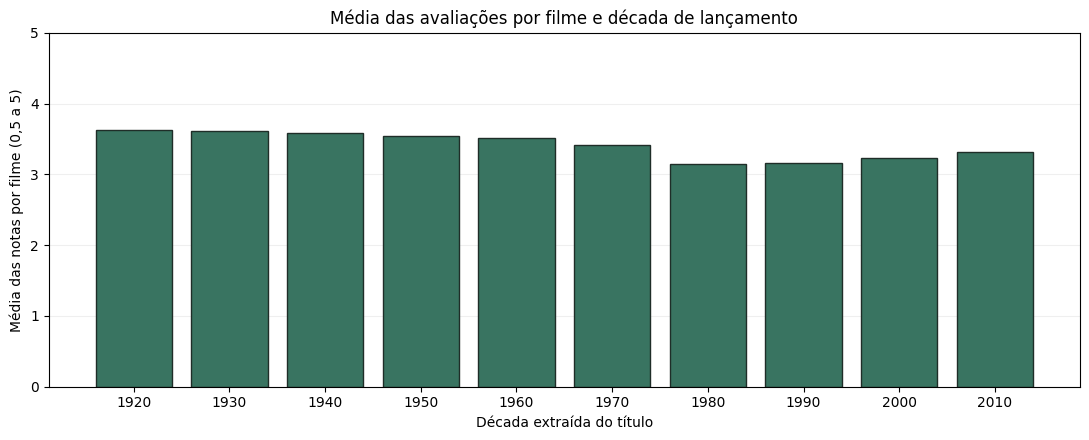

In [20]:
# [1.8-c] Razão de correlação η: década de lançamento × média por filme
MIN_AVALIACOES_FILME = 50
MIN_FILMES_DECADA = 20
estatisticas_filmes = estatisticas_filmes.cache()
filmes_com_suporte = estatisticas_filmes.filter(F.col('quantidade_avaliacoes') >= MIN_AVALIACOES_FILME)
total_com_suporte = filmes_com_suporte.count()
filmes_com_ano = (filmes_com_suporte
    .withColumn('ano_texto', F.regexp_extract(F.col('title'), r'\((\d{4})\)$', 1))
    .filter(F.col('ano_texto') != '')
    .withColumn('ano', F.col('ano_texto').cast('int'))
    .withColumn('decada', (F.floor(F.col('ano') / 10) * 10).cast('int'))
    .select('movieId', 'decada', 'media_avaliacoes'))
total_com_ano = filmes_com_ano.count()
contagens_decada = filmes_com_ano.groupBy('decada').count()
decadas_elegiveis = contagens_decada.filter(F.col('count') >= MIN_FILMES_DECADA).select('decada')
filmes_decada = filmes_com_ano.join(decadas_elegiveis, 'decada', 'inner').cache()
resumo_decada = (filmes_decada.groupBy('decada')
    .agg(F.count('*').alias('n_filmes'), F.avg('media_avaliacoes').alias('media_das_medias'))
    .orderBy('decada').toPandas())
assert len(resumo_decada) >= 2
n_filmes_analise = int(resumo_decada['n_filmes'].sum())
media_global = (resumo_decada['n_filmes'] * resumo_decada['media_das_medias']).sum() / n_filmes_analise
ss_entre = (resumo_decada['n_filmes'] * (resumo_decada['media_das_medias'] - media_global) ** 2).sum()
ss_total = filmes_decada.agg(F.sum((F.col('media_avaliacoes') - F.lit(float(media_global))) ** 2)).first()[0]
assert ss_total > 0
eta_quadrado = float(ss_entre / ss_total)
assert -1e-10 <= eta_quadrado <= 1 + 1e-10
eta = eta_quadrado ** 0.5
print('Filmes com >=50 avaliações:', total_com_suporte)
print('Destes, com ano no fim do título:', total_com_ano)
print('Filmes nas décadas com >=20 filmes:', n_filmes_analise)
print('Décadas incluídas:', len(resumo_decada))
print(f'Razão de correlação η={eta:.4f}; η²={eta_quadrado:.4f}')
print(resumo_decada.round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(resumo_decada['decada'].astype(str), resumo_decada['media_das_medias'], color='#397461', edgecolor='#1f2d28')
ax.set(title='Média das avaliações por filme e década de lançamento', xlabel='Década extraída do título', ylabel='Média das notas por filme (0,5 a 5)', ylim=(0, 5))
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**Leitura dos resultados.** A década responde por 6,7% da variação das médias por filme (η = 0,2589; η² = 0,0670).

- As médias caem de 3,62 (anos 1920) para 3,15 (anos 1980) e voltam a subir até 3,31 (anos 2010).
- O padrão não é linear, o que explica o Pearson próximo de zero.
- Uma explicação possível é a sobrevivência: filmes antigos que ainda recebem 50 ou mais avaliações tendem a ser clássicos.

A associação é descritiva, não causal.

#### Testes estatísticos e tamanhos de efeito

Os coeficientes descritivos são complementados por testes de hipótese:

- **(a)** significância e intervalo de confiança de 95% das correlações por usuário;
- **(b)** ANOVA de um fator e Kruskal-Wallis para a média por filme entre décadas, na mesma população da razão η;
- **(c)** qui-quadrado de independência entre cada gênero e os cinco grupos de nota.

No teste (c), cada avaliação é contada uma vez por teste (avaliações do gênero contra as demais), o que respeita a independência mesmo com gêneros multirrótulo. Com milhões de observações, valores-p muito pequenos são esperados mesmo para diferenças irrelevantes. Por isso, a leitura usa também o tamanho de efeito: r, η² e V de Cramér.

(a) Correlações por usuário (n=162,541); H0: correlação populacional = 0
                               par  pearson  ic95_inf  ic95_sup  p_pearson  spearman  p_spearman
       nota_media × prop_positivas   0.9223    0.9216    0.9231          0    0.9456           0
          prop_action × prop_drama  -0.5184    -0.522   -0.5149          0   -0.5126           0
              nota_media × nota_dp  -0.4744   -0.4782   -0.4707          0   -0.4372           0
         prop_action × prop_comedy  -0.4175   -0.4215   -0.4135          0   -0.3876           0
          nota_dp × prop_positivas  -0.3006   -0.3051   -0.2962          0   -0.3007           0
prop_avaliacoes_total × nota_media  -0.1747   -0.1794     -0.17          0   -0.1308           0



(b) Década × média por filme (13,143 filmes, 10 décadas); H0: mesma média/distribuição
ANOVA: F=104.84; p=2.12e-190   Kruskal-Wallis: H=922.89; p=7.24e-193   (η² já calculado = 0.0670)

(c) Gênero × grupo de nota (n=25,000,095 avaliações por teste); H0: independência
            gênero  avaliações      qui2  gl          p  V_cramer
             Drama    10962833 3.545e+05   4          0    0.1191
            Comedy     8926230 1.581e+05   4          0   0.07952
             Crime     4190259 1.089e+05   4          0   0.06601
            Horror     1892183  1.01e+05   4          0   0.06357
               War     1267346 8.123e+04   4          0     0.057
           Mystery     2010995 4.199e+04   4          0   0.04098
            Action     7446918  3.96e+04   4          0    0.0398
         Film-Noir      247227 3.488e+04   4          0   0.03735
          Children     2124258  2.29e+04   4          0   0.03027
       Documentary      322449 1.781e+04   4          0   0.02669
     

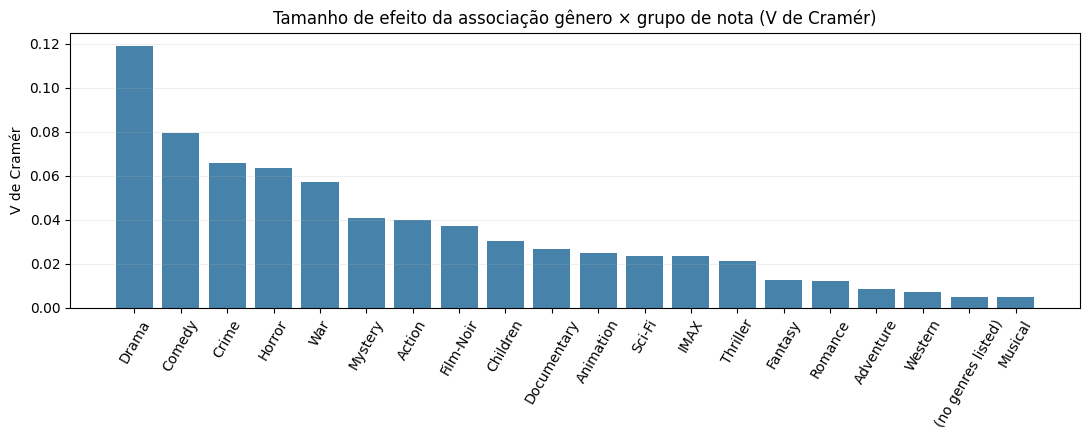

In [21]:
# [1.8-d] Testes estatísticos e tamanhos de efeito
from scipy import stats

# (a) Significância e intervalo de confiança de 95% das correlações por usuário (transformação z de Fisher).
n_u = len(usuarios_pd)
pares_teste = [("nota_media", "prop_positivas"), ("prop_action", "prop_drama"), ("nota_media", "nota_dp"),
               ("prop_action", "prop_comedy"), ("nota_dp", "prop_positivas"), ("prop_avaliacoes_total", "nota_media")]
linhas_corr = []
for a, b in pares_teste:
    r, p_r = stats.pearsonr(usuarios_pd[a], usuarios_pd[b])
    rho, p_rho = stats.spearmanr(usuarios_pd[a], usuarios_pd[b])
    z, ep = np.arctanh(r), 1 / np.sqrt(n_u - 3)
    ic_inf, ic_sup = np.tanh([z - 1.96 * ep, z + 1.96 * ep])
    linhas_corr.append((f"{a} × {b}", r, ic_inf, ic_sup, p_r, rho, p_rho))
testes_corr = pd.DataFrame(linhas_corr, columns=["par", "pearson", "ic95_inf", "ic95_sup", "p_pearson",
                                                 "spearman", "p_spearman"])
print(f"(a) Correlações por usuário (n={n_u:,}); H0: correlação populacional = 0")
print(testes_corr.to_string(index=False, float_format=lambda x: f"{x:.4g}"))

# (b) Década × média por filme: ANOVA de um fator e Kruskal-Wallis, na mesma população da razão η.
decadas_pd = filmes_decada.select("decada", "media_avaliacoes").toPandas()
grupos_decada = [g["media_avaliacoes"].to_numpy() for _, g in decadas_pd.groupby("decada")]
f_anova, p_anova = stats.f_oneway(*grupos_decada)
h_kw, p_kw = stats.kruskal(*grupos_decada)
print(f"\n(b) Década × média por filme ({len(decadas_pd):,} filmes, {len(grupos_decada)} décadas); H0: mesma média/distribuição")
print(f"ANOVA: F={f_anova:.2f}; p={p_anova:.3g}   Kruskal-Wallis: H={h_kw:.2f}; p={p_kw:.3g}   (η² já calculado = {eta_quadrado:.4f})")

# (c) Gênero × grupo de nota: qui-quadrado de independência 2×5 por gênero
# (avaliações do gênero × demais avaliações) e V de Cramér como tamanho de efeito.
total_por_grupo = h5_pd.set_index("grupo_nota")["count"].reindex([1, 2, 3, 4, 5]).to_numpy(dtype=float)
tabela_genero = consulta_5_pd.pivot(index="genre", columns="grupo_nota", values="count").reindex(columns=[1, 2, 3, 4, 5]).fillna(0)
linhas_qui = []
for genero, contagens in tabela_genero.iterrows():
    dentro = contagens.to_numpy(dtype=float)
    fora = total_por_grupo - dentro
    qui2, p_qui, gl, _ = stats.chi2_contingency(np.vstack([dentro, fora]), correction=False)
    linhas_qui.append((genero, int(dentro.sum()), qui2, gl, p_qui, np.sqrt(qui2 / total_por_grupo.sum())))
testes_genero = pd.DataFrame(linhas_qui, columns=["gênero", "avaliações", "qui2", "gl", "p", "V_cramer"]).sort_values("V_cramer", ascending=False)
print(f"\n(c) Gênero × grupo de nota (n={int(total_por_grupo.sum()):,} avaliações por teste); H0: independência")
print(testes_genero.to_string(index=False, float_format=lambda x: f"{x:.4g}"))

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(testes_genero["gênero"], testes_genero["V_cramer"], color="#4682a9")
ax.set(title="Tamanho de efeito da associação gênero × grupo de nota (V de Cramér)", ylabel="V de Cramér")
ax.tick_params(axis="x", rotation=60)
ax.grid(axis="y", alpha=.2)
plt.tight_layout()
plt.show()

**Leitura dos resultados.**

- **(a)** Todas as correlações testadas diferem de zero, com valor-p abaixo da precisão numérica e intervalos de confiança estreitos (por exemplo, r = 0,922, IC 95% de 0,922 a 0,923). Com 162.541 usuários, até r = −0,17 é significativo; a relevância depende do tamanho de r.
- **(b)** A ANOVA (F = 104,8) e o Kruskal-Wallis (H = 922,9) rejeitam a igualdade das médias por filme entre décadas (p ≈ 10⁻¹⁹⁰). O efeito é modesto (η² = 0,067).
- **(c)** Os 20 testes gênero × grupo de nota rejeitam a independência, mas os efeitos são pequenos:
  - o maior V de Cramér é o de Drama (0,119);
  - Comedy, Crime e Horror ficam entre 0,06 e 0,08;
  - os demais, abaixo de 0,06.

**Conclusão:** com milhões de avaliações, a significância estatística é quase automática. A interpretação deve se apoiar no tamanho de efeito. As diferenças de nota entre gêneros e décadas existem, mas são pequenas.

### 1.9 Fechamento da seleção: o que a exploração indica para o pré-processamento

| Achado da exploração (Seção 1) | Consequência para o pré-processamento (Seção 2) |
|---|---|
| A nota ocupa os 10 valores válidos e é assimétrica à esquerda; 0,5 e 1,0 ficam abaixo do whisker | conferir domínio e nulos; manter notas baixas como outliers legítimos |
| 5.062 filmes com `(no genres listed)`, parte deles com avaliações (1.6-c) | rótulo `Unknown`; imputar o gênero dos que têm avaliações suficientes (2.2-b) |
| `imdbId`/`tmdbId` são identificadores externos | atributos irrelevantes para P1/P2; ausências de `tmdbId` não exigem tratamento |
| Filmes do catálogo sem avaliação | ficam fora de P1/P2, pois não têm comportamento de avaliação |
| Volume muito assimétrico por usuário e por filme | usar proporções com denominadores explícitos e suporte mínimo; contagem bruta só descreve grupos |
| `nota_media` × `prop_positivas` muito associadas (Pearson 0,922; Spearman 0,946) | analisar redundância na seleção de características (3.2) |
| Gêneros raros com proporções pequenas | comparar escalas antes de calcular distâncias (3.3) |
| Notas de meio ponto só existem a partir de 2003 | registrar a mudança de escala; não exige tratamento |
| Mais da metade dos usuários avaliou tudo em um único dia | o perfil descreve sobretudo uma sessão; o tempo fica fora do perfil |
| Testes: diferenças significativas, mas pequenas (V de Cramér ≤ 0,12; η² ≤ 0,067) | interpretar pelo tamanho de efeito, não só pelo valor-p |
| Consultas com filtro: filmes populares têm notas bem maiores que os de nicho (d de Cohen 0,73); os demais filtros têm efeito pequeno | considerar a popularidade dos filmes vistos como atributo derivado do usuário (3.8) |
| Atributos com escalas muito diferentes nas matrizes (variâncias de 10⁻¹⁰ a 599) | comparar matrizes em escala [0, 1] e normalizar antes das distâncias (3.3) |
| Gêneros com pouca participação nas avaliações ou com muitos filmes pouco vistos (1.6-c) | manter os rótulos nos dados; agrupá-los no vetor revisado (3.8), para que não distorçam as distâncias |
| Tags descrevem poucos usuários e não respondem a P1 nem a P2 | ficam fora dos dados-alvo nesta fase |

A seleção está documentada: fontes, instâncias, atributos, tipos, domínios, população e associações exploratórias. Tags e IDs externos não entram no perfil sem uma pergunta que os justifique.

## 2. Pré-processamento

O objetivo é preparar os dados-alvo para a mineração. A etapa cobre:

- qualidade dos dados: ruídos, outliers, valores ausentes, inconsistências e redundâncias;
- integração das tabelas por atributos comuns;
- eliminação de atributos irrelevantes;
- amostragem.

As transformações de atributos ficam na Seção 3.

### 2.1 Qualidade: completude, unicidade, validade e integridade

In [22]:
# [2.1] Auditoria de qualidade dos dados-alvo
VALID_RATINGS = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]

print("=== Completude: quantidade de nulos por atributo ===")
for nome, df in datasets.items():
    if nome == "tags":  # fora dos dados-alvo nesta fase
        continue
    nulos = df.agg(*[
        F.sum(F.when(F.col(coluna).isNull(), 1).otherwise(0)).alias(coluna)
        for coluna in df.columns
    ])
    print(f"\n{nome}:")
    nulos.show(truncate=False)

def resumo_duplicatas(df, chaves):
    repetidos = df.groupBy(*chaves).count().filter(F.col("count") > 1)
    linha = repetidos.agg(
        F.count("*").alias("chaves_duplicadas"),
        F.coalesce(F.sum(F.col("count") - 1), F.lit(0)).alias("linhas_excedentes"),
    ).first()
    return linha["chaves_duplicadas"], linha["linhas_excedentes"]

print("\n=== Unicidade no grão esperado ===")
duplicatas_por_tabela = {}
for nome, df, chaves in [
    ("ratings", ratings_df, ["userId", "movieId"]),
    ("movies", movies_df, ["movieId"]),
    ("links", links_df, ["movieId"]),
]:
    chaves_dup, linhas_excedentes = resumo_duplicatas(df, chaves)
    duplicatas_por_tabela[nome] = linhas_excedentes
    print(f"{nome}: {chaves_dup} chaves duplicadas; {linhas_excedentes} linhas excedentes")

notas_invalidas = ratings_df.filter(
    F.col("rating").isNull() | (~F.col("rating").isin(*VALID_RATINGS))
).count()
filmes_sem_genero = movies_df.filter(
    F.col("genres").isNull()
    | (F.trim(F.col("genres")) == "")
    | (F.col("genres") == "(no genres listed)")
).count()
avaliacoes_orfas = ratings_df.join(
    movies_df.select("movieId").dropDuplicates(), on="movieId", how="left_anti"
).count()
print("\n=== Validade e integridade ===")
print("Notas inválidas:", notas_invalidas)
print("Filmes sem gênero informado:", filmes_sem_genero)
print("Avaliações sem filme correspondente:", avaliacoes_orfas)

=== Completude: quantidade de nulos por atributo ===

movies:


+-------+-----+------+
|movieId|title|genres|
+-------+-----+------+
|0      |0    |0     |
+-------+-----+------+


ratings:


+------+-------+------+---------+
|userId|movieId|rating|timestamp|
+------+-------+------+---------+
|0     |0      |0     |0        |
+------+-------+------+---------+


links:


+-------+------+------+
|movieId|imdbId|tmdbId|
+-------+------+------+
|0      |0     |107   |
+-------+------+------+


=== Unicidade no grão esperado ===


ratings: 0 chaves duplicadas; 0 linhas excedentes


movies: 0 chaves duplicadas; 0 linhas excedentes


links: 0 chaves duplicadas; 0 linhas excedentes



=== Validade e integridade ===
Notas inválidas: 0
Filmes sem gênero informado: 5062
Avaliações sem filme correspondente: 0


### 2.2 Limpeza e tratamento

Para valores ausentes, há quatro alternativas: ignorar, adaptar o algoritmo, descartar ou substituir/estimar.

| Ocorrência | Classificação | Decisão |
|---|---|---|
| `ratings`: 0 nulos, 0 duplicatas e 0 notas inválidas | qualidade verificada | nenhuma avaliação removida; a regra de deduplicação (mais recente pelo `timestamp`) fica no código para reprodutibilidade |
| 5.062 filmes `(no genres listed)` | valor ausente em atributo usado no perfil | rótulo `Unknown`; os que têm pelo menos 10 avaliações recebem gênero imputado (2.2-b) |
| 107 links sem `tmdbId` | valor ausente em atributo irrelevante | ignorar: links não entram na análise |
| Tags | fora dos dados-alvo | não tratadas nesta fase |
| Notas 0,5 e 1,0 fora do whisker | outlier legítimo | manter |
| Pares usuário–filme não avaliados | não são valores ausentes | não imputar; preencher criaria avaliações artificiais |

In [23]:
# [2.2] Limpeza determinística e conversão de timestamps
ratings_clean = (
    ratings_df
    .filter(
        F.col("userId").isNotNull()
        & F.col("movieId").isNotNull()
        & F.col("rating").isin(*VALID_RATINGS)
    )
)

# A auditoria evita ordenar 25 milhões de linhas quando não há duplicatas.
if duplicatas_por_tabela["ratings"]:
    ordem_avaliacao = Window.partitionBy("userId", "movieId").orderBy(
        F.col("timestamp").desc_nulls_last()
    )
    ratings_clean = (
        ratings_clean
        .withColumn("_ordem", F.row_number().over(ordem_avaliacao))
        .filter(F.col("_ordem") == 1)
        .drop("_ordem")
    )

ratings_clean = ratings_clean.withColumn(
    "rating_datetime", F.from_unixtime("timestamp").cast("timestamp")
).cache()
ratings_clean.count()  # materializa o cache para as estatísticas seguintes

movies_clean = (
    movies_df
    .filter(F.col("movieId").isNotNull() & F.col("title").isNotNull())
    .dropDuplicates(["movieId"])
    .withColumn(
        "genres",
        F.when(
            F.col("genres").isNull()
            | (F.trim(F.col("genres")) == "")
            | (F.col("genres") == "(no genres listed)"),
            F.lit("Unknown"),
        ).otherwise(F.col("genres")),
    )
)

links_clean = (
    links_df
    .filter(F.col("movieId").isNotNull())
    .dropDuplicates(["movieId"])
)

clean_datasets = {
    "ratings_clean": ratings_clean,
    "movies_clean": movies_clean,
    "links_clean": links_clean,
}
for nome, df in clean_datasets.items():
    df.createOrReplaceTempView(nome)
print("Views limpas criadas:", ", ".join(clean_datasets))

Views limpas criadas: ratings_clean, movies_clean, links_clean


#### Imputação do gênero dos filmes sem gênero

O gênero é usado no perfil, e os filmes sem gênero com avaliações levam essas avaliações para `Unknown`, que não representa preferência. Em vez de dar a moda (Drama) a todos, o gênero é estimado a partir de quem avaliou o filme:

- **atributos do filme:** a média do perfil de gêneros dos seus avaliadores, calculada sem o próprio filme (para o gênero dele não vazar), dividida pela média geral (lift);
- **métodos comparados:** moda, gênero de maior lift, Naive Bayes e kNN com 15 vizinhos, em validação cruzada de 5 partes nos filmes com gênero conhecido;
- **medida:** acerto quando o gênero previsto está entre os gêneros verdadeiros do filme. O erro do Naive Bayes serve de taxa de ruído de referência;
- **regra:** só filmes com pelo menos 10 avaliações recebem gênero, e só se o melhor método superar a moda por pelo menos 10 pontos percentuais. Os demais continuam `Unknown`.

Filmes sem gênero com avaliações: 4,568; com pelo menos 10 avaliações: 320 (16,758 de 26,627 avaliações)
Filmes com gênero conhecido usados para validar: 24,010



Validação cruzada (5 partes) nos filmes com gênero conhecido:
             método  acerto_%  erro_%  acerto_% (10 a 49 avaliações)  acerto_% (50 ou mais avaliações)
moda (sempre Drama)     47.31   52.69                          46.63                             47.86
         maior lift     39.69   60.31                          36.29                             42.51
        Naive Bayes     69.60   30.40                          65.39                             73.09
         kNN (k=15)     83.44   16.56                          78.11                             87.85
Erro do Naive Bayes (taxa de ruído de referência): 30.40%

Melhor método: kNN (k=15) (83.44% de acerto; ganho de 36.13 p.p. sobre a moda). Imputar: sim


Filmes com gênero imputado: 320; continuam como Unknown: 4,742

Gêneros imputados: {'Drama': 122, 'Comedy': 56, 'Documentary': 51, 'Animation': 27, 'Horror': 20, 'Action': 17, 'Thriller': 8, 'Sci-Fi': 5, 'Children': 5, 'Romance': 4, 'Adventure': 3, 'Fantasy': 1, 'Musical': 1}
Exemplos (filmes sem gênero mais avaliados):
                                                  title  n_avaliadores genero_imputado  confianca
Pirates of the Caribbean: Dead Men Tell No Tales (2017)           1687       Adventure       0.80
                                      Hereditary (2018)           1313          Horror       0.80
                                      Green Room (2015)           1060        Thriller       0.67
                                        Whiplash (2013)           1030           Drama       0.87
       Fantastic Beasts and Where to Find Them 2 (2018)            891       Adventure       0.80
                                               Paterson            571           Drama    

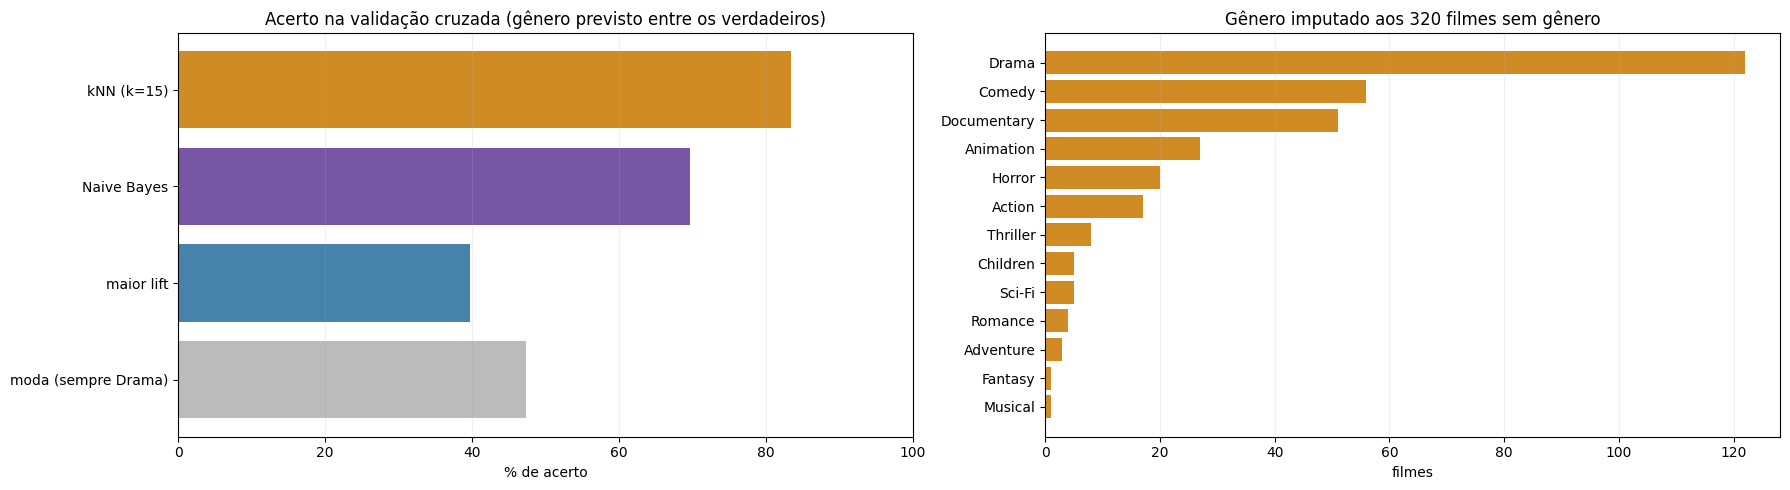

In [24]:
# [2.2-b] Imputação do gênero dos filmes sem gênero, a partir do perfil de quem os avaliou
from sklearn.model_selection import KFold
from sklearn.multiclass import OneVsRestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler

MIN_AVALIADORES = 10  # perfil de avaliadores só é confiável com pelo menos 10 avaliações do filme
K_IMPUTACAO = 15
generos_reais = sorted(r["genre"] for r in movies_clean.select(F.explode(F.split("genres", r"\|")).alias("genre"))
                       .distinct().collect() if r["genre"] != "Unknown")
cols_g = ["g_" + g.lower().replace("-", "_") for g in generos_reais]

# Vetor fracionário de cada filme (1/k para cada um dos seus k gêneros); filmes sem gênero têm vetor nulo.
filmes_vetor = (movies_clean.select("movieId", F.split("genres", r"\|").alias("gs"))
    .withColumn("conhecido", F.when(F.array_contains("gs", "Unknown"), 0).otherwise(1))
    .withColumn("k", F.size("gs"))
    .select("movieId", "conhecido",
            *[F.when(F.array_contains("gs", g), 1.0 / F.col("k")).otherwise(0.0).alias(c) for g, c in zip(generos_reais, cols_g)]))
avaliacoes_vetor = ratings_clean.select("userId", "movieId").join(F.broadcast(filmes_vetor), "movieId")
totais_usuario = avaliacoes_vetor.groupBy("userId").agg(F.sum("conhecido").alias("n_conhecidos"),
                                                        *[F.sum(c).alias("u_" + c) for c in cols_g])
# Perfil de cada avaliador SEM o próprio filme (deixa-um-fora), para o gênero do filme não vazar para o seu perfil.
denominador = F.col("n_conhecidos") - F.col("conhecido")
perfil_avaliadores_pd = (avaliacoes_vetor.join(totais_usuario, "userId")
    .where(denominador > 0)
    .select("movieId", *[F.when(denominador > 0, (F.col("u_" + c) - F.col(c)) / denominador).alias(c) for c in cols_g])
    .groupBy("movieId").agg(F.count("*").alias("n_avaliadores"), *[F.avg(c).alias(c) for c in cols_g])
    .join(movies_clean.select("movieId", "title", "genres"), "movieId")
    .toPandas())
perfil_avaliadores_pd["lista_generos"] = perfil_avaliadores_pd["genres"].str.split("|")

conhecidos = perfil_avaliadores_pd[(perfil_avaliadores_pd["genres"] != "Unknown")
                                   & (perfil_avaliadores_pd["n_avaliadores"] >= MIN_AVALIADORES)].reset_index(drop=True)
alvos = perfil_avaliadores_pd[(perfil_avaliadores_pd["genres"] == "Unknown")
                              & (perfil_avaliadores_pd["n_avaliadores"] >= MIN_AVALIADORES)].reset_index(drop=True)
sem_genero_avaliados = perfil_avaliadores_pd[perfil_avaliadores_pd["genres"] == "Unknown"]
print(f"Filmes sem gênero com avaliações: {len(sem_genero_avaliados):,}; com pelo menos {MIN_AVALIADORES} avaliações: "
      f"{len(alvos):,} ({int(alvos['n_avaliadores'].sum()):,} de {int(sem_genero_avaliados['n_avaliadores'].sum()):,} avaliações)")
print(f"Filmes com gênero conhecido usados para validar: {len(conhecidos):,}")

# Atributos: preferência dos avaliadores por gênero em relação à média (lift), padronizada.
media_generos = conhecidos[cols_g].mean()
lift_conhecidos = (conhecidos[cols_g] / media_generos).to_numpy()
padronizador = StandardScaler().fit(lift_conhecidos)
X_conhecidos = padronizador.transform(lift_conhecidos)
binarizador = MultiLabelBinarizer(classes=generos_reais)
Y_conhecidos = binarizador.fit_transform(conhecidos["lista_generos"])
pos_drama = generos_reais.index("Drama")

# Validação cruzada em 5 partes: acerto = gênero previsto está entre os gêneros verdadeiros do filme.
acertos = {"moda (sempre Drama)": [], "maior lift": [], "Naive Bayes": [], f"kNN (k={K_IMPUTACAO})": []}
faixa_teste = []
for treino, teste in KFold(n_splits=5, shuffle=True, random_state=42).split(X_conhecidos):
    linhas = np.arange(len(teste))
    Y_teste = Y_conhecidos[teste]
    acertos["moda (sempre Drama)"].append(Y_teste[:, pos_drama])
    acertos["maior lift"].append(Y_teste[linhas, lift_conhecidos[teste].argmax(axis=1)])
    nb = OneVsRestClassifier(GaussianNB()).fit(X_conhecidos[treino], Y_conhecidos[treino])
    acertos["Naive Bayes"].append(Y_teste[linhas, nb.predict_proba(X_conhecidos[teste]).argmax(axis=1)])
    _, vizinhos = NearestNeighbors(n_neighbors=K_IMPUTACAO).fit(X_conhecidos[treino]).kneighbors(X_conhecidos[teste])
    votos = Y_conhecidos[treino][vizinhos].sum(axis=1)
    acertos[f"kNN (k={K_IMPUTACAO})"].append(Y_teste[linhas, votos.argmax(axis=1)])
    faixa_teste.append(conhecidos.loc[teste, "n_avaliadores"].to_numpy())
faixa_teste = np.concatenate(faixa_teste)
faixas = [("10 a 49", (faixa_teste >= 10) & (faixa_teste < 50)), ("50 ou mais", faixa_teste >= 50)]
linhas_val = []
for metodo, lista in acertos.items():
    acerto = np.concatenate(lista)
    linhas_val.append((metodo, 100 * acerto.mean(), 100 * (1 - acerto.mean()),
                       *[100 * acerto[m].mean() for _, m in faixas]))
validacao = pd.DataFrame(linhas_val, columns=["método", "acerto_%", "erro_%"] + [f"acerto_% ({n} avaliações)" for n, _ in faixas])
print("\nValidação cruzada (5 partes) nos filmes com gênero conhecido:")
print(validacao.round(2).to_string(index=False))
print(f"Erro do Naive Bayes (taxa de ruído de referência): {validacao.set_index('método').loc['Naive Bayes', 'erro_%']:.2f}%")

# Decisão: imputar com o melhor método só se ele superar a moda por pelo menos 10 pontos percentuais.
modelos = validacao[~validacao["método"].str.startswith("moda")].sort_values("acerto_%", ascending=False)
melhor = modelos.iloc[0]
ganho = melhor["acerto_%"] - validacao.set_index("método").loc["moda (sempre Drama)", "acerto_%"]
imputar = ganho >= 10 and len(alvos) > 0
print(f"\nMelhor método: {melhor['método']} ({melhor['acerto_%']:.2f}% de acerto; ganho de {ganho:.2f} p.p. sobre a moda). "
      f"Imputar: {'sim' if imputar else 'não'}")

if imputar:
    X_alvos = padronizador.transform((alvos[cols_g] / media_generos).to_numpy())
    if melhor["método"].startswith("kNN"):
        _, vizinhos = NearestNeighbors(n_neighbors=K_IMPUTACAO).fit(X_conhecidos).kneighbors(X_alvos)
        pontuacao = Y_conhecidos[vizinhos].sum(axis=1) / K_IMPUTACAO
    elif melhor["método"] == "Naive Bayes":
        pontuacao = OneVsRestClassifier(GaussianNB()).fit(X_conhecidos, Y_conhecidos).predict_proba(X_alvos)
    else:
        pontuacao = (alvos[cols_g] / media_generos).to_numpy()
    alvos["genero_imputado"] = [generos_reais[i] for i in pontuacao.argmax(axis=1)]
    alvos["confianca"] = pontuacao.max(axis=1)
    imputados = spark.createDataFrame(alvos[["movieId", "genero_imputado"]].astype({"movieId": "int64"}))
    movies_clean = (movies_clean.join(F.broadcast(imputados), "movieId", "left")
        .withColumn("genero_foi_imputado", F.col("genero_imputado").isNotNull())
        .withColumn("genres", F.coalesce(F.col("genero_imputado"), F.col("genres")))
        .drop("genero_imputado"))
else:
    movies_clean = movies_clean.withColumn("genero_foi_imputado", F.lit(False))
movies_clean = movies_clean.cache()
movies_clean.createOrReplaceTempView("movies_clean")
n_imputados = movies_clean.filter("genero_foi_imputado").count()
print(f"Filmes com gênero imputado: {n_imputados:,}; continuam como Unknown: "
      f"{movies_clean.filter(F.col('genres') == 'Unknown').count():,}")
if imputar:
    print("\nGêneros imputados:", alvos["genero_imputado"].value_counts().to_dict())
    print("Exemplos (filmes sem gênero mais avaliados):")
    print(alvos.sort_values("n_avaliadores", ascending=False)[["title", "n_avaliadores", "genero_imputado", "confianca"]]
          .head(12).round(2).to_string(index=False))

    fig, axes = plt.subplots(1, 2, figsize=(18, 5))
    axes[0].barh(validacao["método"], validacao["acerto_%"], color=["#bbbbbb", "#4682a9", "#7656a5", "#d18b24"])
    axes[0].set(title="Acerto na validação cruzada (gênero previsto entre os verdadeiros)", xlabel="% de acerto", xlim=(0, 100))
    axes[0].grid(axis="x", alpha=.2)
    contagem = alvos["genero_imputado"].value_counts().sort_values()
    axes[1].barh(contagem.index, contagem.values, color="#d18b24")
    axes[1].set(title=f"Gênero imputado aos {len(alvos):,} filmes sem gênero", xlabel="filmes")
    axes[1].grid(axis="x", alpha=.2)
    plt.tight_layout()
    plt.show()

**Leitura dos resultados.**

- **Validação:** em 24.010 filmes com gênero conhecido, o kNN acerta 83,4%, contra 47,3% da moda (sempre Drama): ganho de 36,1 pontos percentuais. O Naive Bayes acerta 69,6%, e seu erro, de 30,4%, é a taxa de ruído de referência. O gênero de maior lift acerta 39,7%, abaixo da moda: o lift divide pela média geral do gênero, o que amplia os gêneros raros.
- **Suporte:** o acerto do kNN sobe de 78,1% nos filmes com 10 a 49 avaliações para 87,9% nos filmes com 50 ou mais. O acerto cresce com o número de avaliações, e por isso a imputação exige pelo menos 10.
- **Resultado:** 320 filmes recebem gênero, e 4.742 continuam `Unknown` (494 sem avaliação e 4.248 com 1 a 9 avaliações). Os gêneros imputados mais frequentes são Drama (122 filmes), Comedy (56), Documentary (51) e Animation (27).
- **Exemplos:** entre os filmes sem gênero mais avaliados, Whiplash recebe Drama, Hereditary recebe Horror, Pitch Perfect 3 recebe Comedy e Cosmos recebe Documentary. A confiança é a fração dos 15 filmes vizinhos que têm o gênero imputado; nos exemplos, vai de 0,60 a 1,00.

**Limitação:** cada filme recebe um único gênero, o mais provável, enquanto os gêneros do catálogo se sobrepõem (as proporções de 1.6 somam mais de 100%). O acerto mede se o gênero previsto está entre os verdadeiros, não se a lista completa foi recuperada.

**Consequência:** a imputação tira de `Unknown` 63% das avaliações de filmes sem gênero. A coluna `genero_foi_imputado` de `movies_clean` permite repetir qualquer análise sem os filmes imputados.

### 2.3 Integração das tabelas

Avaliações e filmes são integrados pela chave `movieId`. A junção deve preservar uma linha por avaliação. A expansão por gênero multiplica linhas de forma esperada e só é usada nas análises por gênero.

In [25]:
# [2.3-a] Comparação entre dados-alvo e dados tratados; liberação do cache da seleção
linhas_removidas = total_avaliacoes - ratings_clean.count()
print("Avaliações removidas na limpeza:", linhas_removidas)
if linhas_removidas == 0:
    print("Os resultados de 1.5–1.8 valem também para as avaliações tratadas; "
          "nos gêneros, os filmes sem gênero passam a `Unknown` ou recebem gênero imputado (2.2-b); 2.6 mostra o efeito.")
_ = ratings_sel.unpersist()  # ratings_clean já está materializado em cache (2.2)

Avaliações removidas na limpeza: 0
Os resultados de 1.5–1.8 valem também para as avaliações tratadas; nos gêneros, os filmes sem gênero passam a `Unknown` ou recebem gênero imputado (2.2-b); 2.6 mostra o efeito.


In [26]:
# [2.3-b] Integração: joins no grão esperado e expansão por gênero
movie_genres = (
    movies_clean
    .withColumn("genre", F.explode(F.split(F.col("genres"), r"\|")))
    .select("movieId", "title", "genre")
)

ratings_movies = ratings_clean.join(
    movies_clean.select("movieId", "title", "genres"),
    on="movieId",
    how="inner",
)

ratings_genres = ratings_clean.join(
    movie_genres,
    on="movieId",
    how="inner",
)

movie_genres.createOrReplaceTempView("movie_genres")
ratings_movies.createOrReplaceTempView("ratings_movies")
ratings_genres.createOrReplaceTempView("ratings_genres")

linhas_ratings = ratings_clean.count()
linhas_ratings_movies = ratings_movies.count()
linhas_ratings_genres = ratings_genres.count()

print("Avaliações limpas:", linhas_ratings)
print("Avaliações após join com filmes:", linhas_ratings_movies)
print("Linhas após expansão por gênero:", linhas_ratings_genres)
print("Cobertura do join ratings-movies:", round(linhas_ratings_movies / linhas_ratings * 100, 4), "%")

assert linhas_ratings_movies == linhas_ratings, (
    "O join com movies alterou o grão das avaliações. Verifique chaves órfãs ou duplicadas."
)

print("Views derivadas criadas: movie_genres, ratings_movies e ratings_genres")

Avaliações limpas: 25000095
Avaliações após join com filmes: 25000095
Linhas após expansão por gênero: 67809886
Cobertura do join ratings-movies: 100.0 %
Views derivadas criadas: movie_genres, ratings_movies e ratings_genres


In [27]:
# [2.3-c] Verificações finais do pré-processamento
contagens_finais = spark.createDataFrame([
    ("usuários com avaliações", ratings_clean.select("userId").distinct().count()),
    ("filmes avaliados", ratings_clean.select("movieId").distinct().count()),
    ("filmes no catálogo", movies_clean.select("movieId").distinct().count()),
    ("gêneros", movie_genres.select("genre").distinct().count()),
], ["medida", "valor"])

contagens_finais.show(truncate=False)

assert ratings_clean.filter(
    F.col("userId").isNull()
    | F.col("movieId").isNull()
    | (~F.col("rating").isin(*VALID_RATINGS))
).limit(1).count() == 0

assert movies_clean.groupBy("movieId").count().filter(F.col("count") > 1).limit(1).count() == 0

print("Verificações concluídas: dados limpos, notas válidas e joins no grão esperado.")

+-----------------------+------+
|medida                 |valor |
+-----------------------+------+
|usuários com avaliações|162541|
|filmes avaliados       |59047 |
|filmes no catálogo     |62423 |
|gêneros                |20    |
+-----------------------+------+



Verificações concluídas: dados limpos, notas válidas e joins no grão esperado.


### 2.4 Amostragem

Todas as medidas usam a base completa. As amostras servem apenas aos gráficos que ficariam pesados com 25 milhões de pontos: boxplot/violin com cerca de 100 mil avaliações e matriz de dispersão com 3.000 usuários. A amostra precisa ser representativa. Por isso, a célula compara as proporções e os momentos da amostra com os da população.

In [28]:
# [2.4] Representatividade das amostras usadas nos gráficos
populacao_pct = rating_distribution.select("rating", "proporcao_pct").toPandas().set_index("rating")["proporcao_pct"]
amostra_pct = amostra_pd["rating"].value_counts(normalize=True).mul(100).reindex(populacao_pct.index, fill_value=0)
comparacao_notas = pd.DataFrame({"populacao_%": populacao_pct, "amostra_%": amostra_pct.round(4)})
comparacao_notas["diferenca_pp"] = (comparacao_notas["amostra_%"] - comparacao_notas["populacao_%"]).round(4)
print(f"Amostra de notas: n={len(amostra_pd):,} (aleatória simples, semente 42)")
print(comparacao_notas.to_string())
print(f"Média: população={estatisticas_notas['media']:.4f}; amostra={amostra_pd['rating'].mean():.4f}")
print(f"DP: população={estatisticas_notas['desvio_padrao']:.4f}; amostra={amostra_pd['rating'].std(ddof=1):.4f}")
print(f"Maior diferença absoluta de proporção: {comparacao_notas['diferenca_pp'].abs().max():.4f} ponto percentual")

comparacao_usuarios = pd.DataFrame({
    "media_populacao": usuarios_pd[cols_grafico].mean(),
    "media_amostra": amostra_scatter.mean(),
    "dp_populacao": usuarios_pd[cols_grafico].std(ddof=1),
    "dp_amostra": amostra_scatter.std(ddof=1),
}).round(4)
print(f"Usuários: população n={len(usuarios_pd):,}; amostra da matriz de dispersão n={len(amostra_scatter):,}")
print(comparacao_usuarios.to_string())

Amostra de notas: n=100,099 (aleatória simples, semente 42)
        populacao_%  amostra_%  diferenca_pp
rating                                      
0.5          1.5723     1.5774        0.0051
1.0          3.1072     3.0979       -0.0093
1.5          1.5980     1.6004        0.0024
2.0          6.5634     6.6115        0.0481
2.5          5.0512     5.0820        0.0308
3.0         19.5876    19.4987       -0.0889
3.5         12.7092    12.7044       -0.0048
4.0         26.5591    26.5657        0.0066
4.5          8.8021     8.9212        0.1191
5.0         14.4498    14.3408       -0.1090
Média: população=3.5339; amostra=3.5329
DP: população=1.0607; amostra=1.0607
Maior diferença absoluta de proporção: 0.1191 ponto percentual
Usuários: população n=162,541; amostra da matriz de dispersão n=3,000
                media_populacao  media_amostra  dp_populacao  dp_amostra
nota_media               3.6792         3.6700        0.4774      0.4929
nota_dp                  0.9287         0.92

**Leitura dos resultados.**

- **Amostra de notas:** as 100.099 notas diferem da população em no máximo 0,12 ponto percentual (nota 4,5). A média é 3,5329, contra 3,5339, e o desvio-padrão é igual (1,0607).
- **Amostra de usuários:** nos 3.000 usuários, médias e desvios ficam próximos dos da população (por exemplo, `nota_media` 3,670 contra 3,679).

As amostras são representativas para os gráficos em que foram usadas.

### 2.5 Valores ausentes

A tabela de avaliações não tem nulos (2.1). Os ausentes relevantes são as combinações usuário × filme sem avaliação. A célula mede a esparsidade dessa matriz e testa, num recorte de 500 usuários sorteados e dos 300 filmes mais avaliados, a alternativa de substituir os ausentes pela média da categoria (primeiro gênero do filme) ou pela média do filme. O efeito é medido no desvio-padrão das notas e na correlação entre usuários, comparada à correlação calculada só nos filmes que os dois avaliaram.

Matriz usuário × filme: 162,541 usuários × 59,047 filmes avaliados = 9,597,558,427 células
Células com nota: 25,000,095 (0.2605%); sem nota: 9,572,558,332 (99.7395%)


Porcentagem dos filmes avaliados que cada usuário avaliou (mín, Q1, mediana, Q3, máx): [0.0339, 0.061, 0.1202, 0.2744, 54.5362]



Recorte: 500 usuários × 300 filmes mais avaliados; 17.20% das células têm nota; 2 usuários não avaliaram nenhum desses filmes.
Correlação entre usuários: só observadas = pares com pelo menos 10 filmes avaliados em comum.
                         variante  células usadas  média     DP  pares de usuários  Pearson médio  % pares com r > 0,9
            só células observadas           25795 3.7732 1.0158              41440         0.1183               0.0290
imputação pela média da categoria          150000 3.5800 0.4473             124750         0.1865               0.0168
    imputação pela média do filme          150000 3.7368 0.5226             124750         0.5387               1.0269


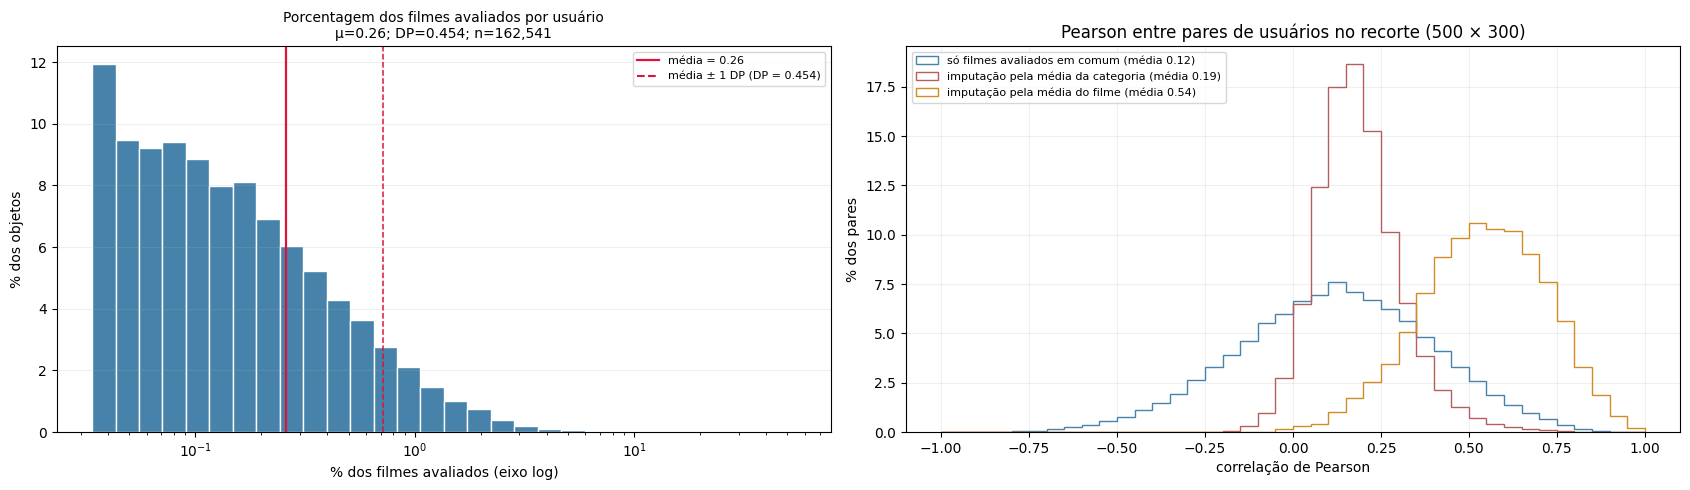

In [29]:
# [2.5] Valores ausentes: esparsidade da matriz usuário × filme e efeito de imputar pela média
n_usuarios_av = ratings_clean.select("userId").distinct().count()
n_filmes_av = ratings_clean.select("movieId").distinct().count()
celulas_matriz = n_usuarios_av * n_filmes_av
densidade = linhas_ratings / celulas_matriz
print(f"Matriz usuário × filme: {n_usuarios_av:,} usuários × {n_filmes_av:,} filmes avaliados = {celulas_matriz:,} células")
print(f"Células com nota: {linhas_ratings:,} ({100 * densidade:.4f}%); "
      f"sem nota: {celulas_matriz - linhas_ratings:,} ({100 * (1 - densidade):.4f}%)")
avaliacoes_por_usuario = ratings_clean.groupBy("userId").count().toPandas()["count"]
cobertura_pct = 100 * avaliacoes_por_usuario / n_filmes_av
print("Porcentagem dos filmes avaliados que cada usuário avaliou (mín, Q1, mediana, Q3, máx):",
      cobertura_pct.quantile([0, .25, .5, .75, 1]).round(4).tolist())

# Recorte para medir o efeito da imputação: 500 usuários sorteados e os 300 filmes mais avaliados.
N_USUARIOS_DEMO, N_FILMES_DEMO = 500, 300
ids_usuarios = np.sort(ratings_clean.select("userId").distinct().toPandas()["userId"].to_numpy())
usuarios_demo = np.sort(np.random.default_rng(42).choice(ids_usuarios, size=N_USUARIOS_DEMO, replace=False))
filmes_demo = (ratings_clean.groupBy("movieId").count()
               .orderBy(F.desc("count"), F.asc("movieId")).limit(N_FILMES_DEMO).cache())
ordem_filmes = filmes_demo.toPandas()["movieId"].tolist()
recorte = (ratings_clean.filter(F.col("userId").isin(usuarios_demo.tolist()))
           .join(F.broadcast(filmes_demo.select("movieId")), "movieId")
           .select("userId", "movieId", "rating").toPandas())
matriz_demo = (recorte.pivot_table(index="userId", columns="movieId", values="rating")
               .reindex(index=usuarios_demo, columns=ordem_filmes))

# "Categoria" do filme = primeiro gênero listado; a média da categoria usa todas as avaliações da base.
genero_principal = movies_clean.select("movieId", F.split(F.col("genres"), r"\|").getItem(0).alias("genero_principal"))
media_categoria = (ratings_clean.join(genero_principal, "movieId")
                   .groupBy("genero_principal").agg(F.avg("rating").alias("media_categoria")))
categoria_filmes = (genero_principal.join(filmes_demo.select("movieId"), "movieId")
                    .join(media_categoria, "genero_principal").toPandas().set_index("movieId")["media_categoria"])
media_filmes_demo = (ratings_clean.join(filmes_demo.select("movieId"), "movieId").groupBy("movieId")
                     .agg(F.avg("rating").alias("media_filme")).toPandas().set_index("movieId")["media_filme"])
imputada_categoria = matriz_demo.fillna(categoria_filmes.reindex(ordem_filmes))
imputada_filme = matriz_demo.fillna(media_filmes_demo.reindex(ordem_filmes))
assert imputada_categoria.notna().all().all() and imputada_filme.notna().all().all()

observadas = matriz_demo.notna().to_numpy()
sem_nota_no_recorte = int((observadas.sum(axis=1) == 0).sum())
triangulo = np.triu_indices(N_USUARIOS_DEMO, 1)
corr_coavaliados = matriz_demo.T.corr(min_periods=10).to_numpy()[triangulo]
corr_coavaliados = corr_coavaliados[~np.isnan(corr_coavaliados)]
with np.errstate(invalid="ignore", divide="ignore"):
    corr_categoria = np.corrcoef(imputada_categoria.to_numpy())[triangulo]
    corr_filme = np.corrcoef(imputada_filme.to_numpy())[triangulo]
corr_categoria, corr_filme = corr_categoria[~np.isnan(corr_categoria)], corr_filme[~np.isnan(corr_filme)]
linhas_imputacao = [
    ("só células observadas", int(observadas.sum()), np.nanmean(matriz_demo.to_numpy()), np.nanstd(matriz_demo.to_numpy(), ddof=1),
     len(corr_coavaliados), corr_coavaliados.mean(), 100 * (corr_coavaliados > 0.9).mean()),
    ("imputação pela média da categoria", observadas.size, imputada_categoria.to_numpy().mean(), imputada_categoria.to_numpy().std(ddof=1),
     len(corr_categoria), corr_categoria.mean(), 100 * (corr_categoria > 0.9).mean()),
    ("imputação pela média do filme", observadas.size, imputada_filme.to_numpy().mean(), imputada_filme.to_numpy().std(ddof=1),
     len(corr_filme), corr_filme.mean(), 100 * (corr_filme > 0.9).mean()),
]
tabela_imputacao = pd.DataFrame(linhas_imputacao, columns=["variante", "células usadas", "média", "DP",
                                                           "pares de usuários", "Pearson médio", "% pares com r > 0,9"])
print(f"\nRecorte: {N_USUARIOS_DEMO} usuários × {N_FILMES_DEMO} filmes mais avaliados; "
      f"{100 * observadas.mean():.2f}% das células têm nota; {sem_nota_no_recorte} usuários não avaliaram nenhum desses filmes.")
print("Correlação entre usuários: só observadas = pares com pelo menos 10 filmes avaliados em comum.")
print(tabela_imputacao.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
histograma_media_dp(axes[0], cobertura_pct, "Porcentagem dos filmes avaliados por usuário", log_x=True,
                    rotulo_x="% dos filmes avaliados (eixo log)")
bordas = np.linspace(-1, 1, 41)
for valores, rotulo, cor in [(corr_coavaliados, "só filmes avaliados em comum", "#4682a9"),
                             (corr_categoria, "imputação pela média da categoria", "#b65d5d"),
                             (corr_filme, "imputação pela média do filme", "#d18b24")]:
    axes[1].hist(valores, bins=bordas, weights=np.full(len(valores), 100 / len(valores)), histtype="step", lw=1.8,
                 color=cor, label=f"{rotulo} (média {valores.mean():.2f})")
axes[1].set(title=f"Pearson entre pares de usuários no recorte ({N_USUARIOS_DEMO} × {N_FILMES_DEMO})",
            xlabel="correlação de Pearson", ylabel="% dos pares")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=.2)
plt.tight_layout()
plt.show()

**Leitura dos resultados.**

- **Esparsidade:** a matriz usuário × filme tem 9.597.558.427 células, das quais só 25.000.095 (0,26%) têm nota. O usuário mediano avaliou 0,12% dos filmes; o mais ativo, 54,5%.
- **Recorte de teste:** mesmo entre os 300 filmes mais avaliados, só 17,2% das células têm nota.
- **Efeito da imputação:**
  - o DP das notas cai de 1,02 (só notas reais) para 0,45 com a média da categoria e 0,52 com a média do filme: a variação real é reduzida à metade;
  - a correlação média entre usuários sobe de 0,12 (filmes avaliados em comum) para 0,19 com a média da categoria e 0,54 com a média do filme. Os usuários passam a parecer semelhantes porque compartilham os valores preenchidos, não porque avaliaram igual.

**Limitação:** o teste usa um recorte de 500 usuários e dos filmes mais populares, onde a matriz é muito menos vazia que no total.

**Consequência:** os ausentes não são preenchidos. O perfil de 3.1 usa apenas os filmes avaliados por cada usuário, que é a alternativa de ignorar os valores ausentes. Uma imputação pela média do perfil só faz sentido depois de P1, quando os segmentos existirem.

### 2.6 Distribuições depois do tratamento

Nenhuma avaliação foi removida. Por isso, só se repetem os testes que o tratamento pode alterar:

- **(a)** a distribuição da nota, que deve ser idêntica;
- **(b)** filmes, avaliações, média e desvio-padrão por gênero, antes e depois da imputação;
- **(c)** as notas dos filmes que receberam gênero, comparadas às do gênero inteiro;
- **(d)** o qui-quadrado gênero × grupo de nota, com o V de Cramér antes e depois.

Volume, tempo, década e correlações por filme não dependem do gênero. As correlações por usuário mudam só nas avaliações dos filmes imputados, cuja quantidade aparece em (b).

(a) Distribuição da nota idêntica antes e depois do tratamento: True (25,000,095 avaliações)



(b) Gêneros antes × depois (Unknown = (no genres listed) nos dados-alvo):
             filmes_antes  filmes_depois  Δ_filmes  avaliacoes_antes  avaliacoes_depois  Δ_avaliacoes  media_antes  media_depois  Δ_media  dp_antes  dp_depois
genre                                                                                                                                                         
Drama               25606          25728       122          10962833           10968312          5479       3.6772        3.6772  -0.0000    0.9981     0.9982
Adventure            4145           4148         3           5832424            5835032          2608       3.5174        3.5173  -0.0001    1.0682     1.0682
Comedy              16870          16926        56           8926230            8928827          2597       3.4240        3.4240   0.0000    1.0834     1.0834
Horror               5989           6009        20           1892183            1893900          1717       3.2936        3.2937  


(c) Notas dos filmes que receberam gênero, comparadas à média do gênero:
     genres  avaliacoes  media_imputados  dp_imputados  media_do_genero
      Drama        5479            3.668         1.094            3.677
  Adventure        2608            3.247         1.073            3.517
     Comedy        2597            3.428         1.171            3.424
     Horror        1717            3.493         1.178            3.294
   Thriller        1204            3.581         0.949            3.523
Documentary        1202            3.641         1.220            3.705
     Action         854            2.942         1.154            3.467
  Animation         418            3.283         1.148            3.615
     Sci-Fi         362            3.559         1.109            3.478
    Romance         151            3.182         1.035            3.543
   Children          92            2.929         1.270            3.432
    Musical          58            3.888         1.151        


(d) Gênero × grupo de nota nos dados tratados (V de Cramér antes e depois):
     gênero  avaliações      qui2          p  V_cramer_depois  V_cramer_antes        Δ_V
      Drama    10968312  3.55e+05          0           0.1192          0.1191  7.819e-05
     Comedy     8928827 1.581e+05          0          0.07952         0.07952 -2.017e-06
      Crime     4190259 1.089e+05          0          0.06601         0.06601          0
     Horror     1893900 1.009e+05          0          0.06354         0.06357 -2.512e-05
        War     1267346 8.123e+04          0            0.057           0.057          0
    Mystery     2010995 4.199e+04          0          0.04098         0.04098          0
     Action     7447772 3.966e+04          0          0.03983          0.0398  3.061e-05
  Film-Noir      247227 3.488e+04          0          0.03735         0.03735          0
   Children     2124350 2.291e+04          0          0.03027         0.03027  6.639e-06
Documentary      323651 1.786e+04

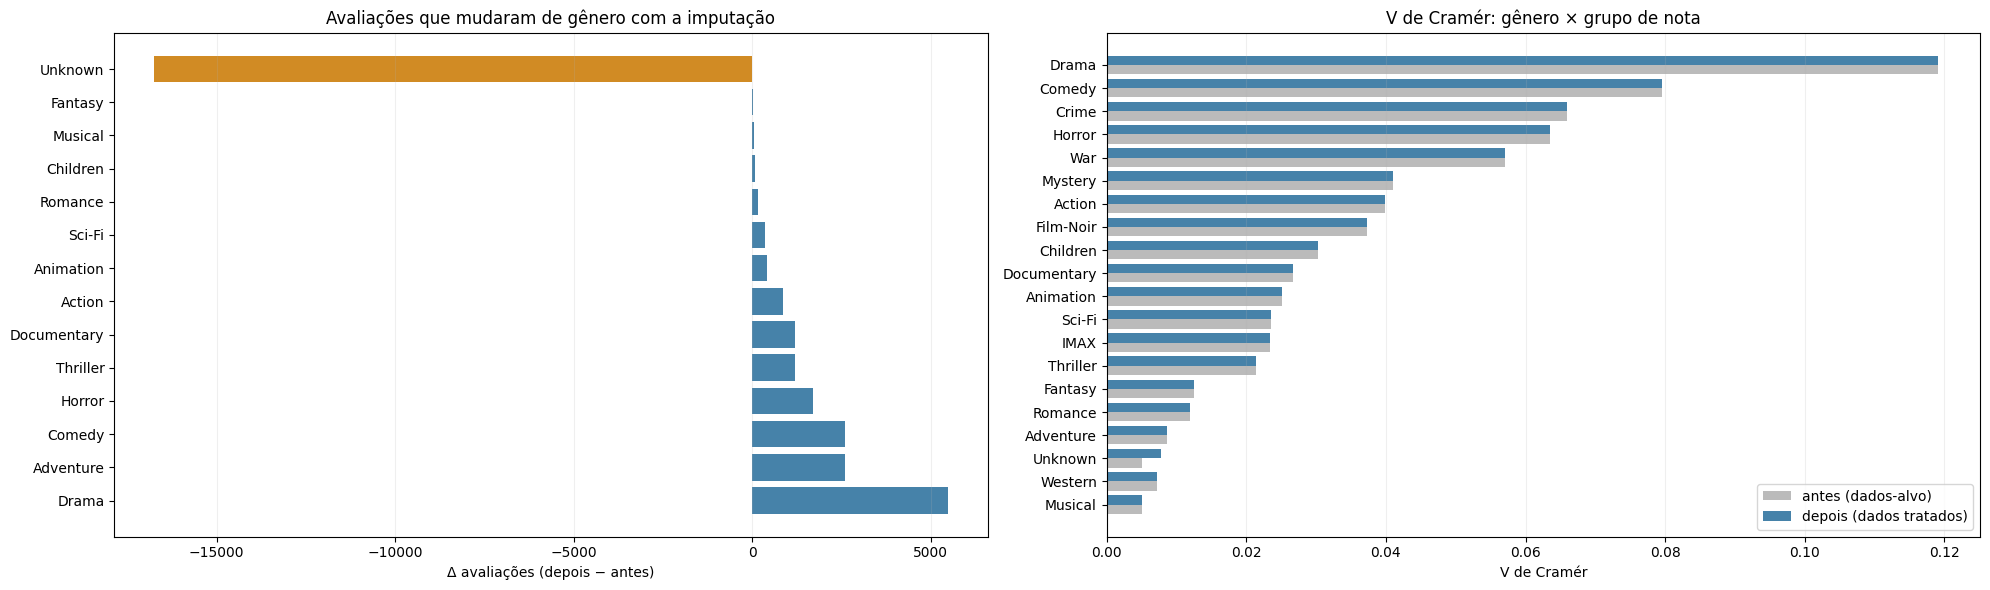

In [30]:
# [2.6] Distribuições depois do tratamento: o que muda com a imputação de gênero
from scipy import stats

# (a) Nota: nenhuma avaliação foi removida, então a distribuição precisa ser idêntica à de 1.5.
dist_nota_tratada = ratings_clean.groupBy("rating").count().toPandas().set_index("rating")["count"].sort_index()
dist_nota_alvo = rating_distribution.select("rating", "count").toPandas().set_index("rating")["count"].sort_index()
print(f"(a) Distribuição da nota idêntica antes e depois do tratamento: {dist_nota_tratada.equals(dist_nota_alvo)} "
      f"({int(dist_nota_tratada.sum()):,} avaliações)")

# (b) Gêneros: filmes, avaliações, média e DP antes (dados-alvo) e depois (dados tratados).
antes = dist_generos.assign(genre=dist_generos["genre"].replace({SEM_GENERO: "Unknown"}))[
    ["genre", "filmes", "avaliacoes", "media", "dp"]].set_index("genre")
depois = (ratings_genres.groupBy("genre")
    .agg(F.count("*").alias("avaliacoes"), F.avg("rating").alias("media"), F.stddev("rating").alias("dp"))
    .join(movie_genres.groupBy("genre").agg(F.count("*").alias("filmes")), "genre", "right")
    .toPandas().fillna({"avaliacoes": 0}).set_index("genre"))
comparacao_generos = antes.merge(depois, left_index=True, right_index=True, how="left", suffixes=("_antes", "_depois"))
comparacao_generos["Δ_filmes"] = comparacao_generos["filmes_depois"] - comparacao_generos["filmes_antes"]
comparacao_generos["Δ_avaliacoes"] = comparacao_generos["avaliacoes_depois"] - comparacao_generos["avaliacoes_antes"]
comparacao_generos["Δ_media"] = comparacao_generos["media_depois"] - comparacao_generos["media_antes"]
comparacao_generos = comparacao_generos.sort_values("Δ_avaliacoes", ascending=False)
print("\n(b) Gêneros antes × depois (Unknown = (no genres listed) nos dados-alvo):")
print(comparacao_generos[["filmes_antes", "filmes_depois", "Δ_filmes", "avaliacoes_antes", "avaliacoes_depois",
                          "Δ_avaliacoes", "media_antes", "media_depois", "Δ_media", "dp_antes", "dp_depois"]]
      .round(4).to_string())

# (c) Avaliações dos filmes imputados: nota média por gênero imputado, comparada à do gênero inteiro.
imputados_notas = (ratings_clean.join(movies_clean.filter("genero_foi_imputado").select("movieId", "genres"), "movieId")
    .groupBy("genres").agg(F.count("*").alias("avaliacoes"), F.avg("rating").alias("media_imputados"),
                           F.stddev("rating").alias("dp_imputados")).toPandas())
if len(imputados_notas):
    imputados_notas = imputados_notas.merge(depois[["media"]].rename(columns={"media": "media_do_genero"}),
                                            left_on="genres", right_index=True)
    print("\n(c) Notas dos filmes que receberam gênero, comparadas à média do gênero:")
    print(imputados_notas.sort_values("avaliacoes", ascending=False).round(3).to_string(index=False))

# (d) Gênero × grupo de nota: mesmo qui-quadrado e V de Cramér de 1.8-d, agora nos dados tratados.
contagens_tratadas = (ratings_genres.withColumn("grupo_nota", F.ceil("rating").cast("int"))
    .groupBy("genre", "grupo_nota").count().toPandas()
    .pivot(index="genre", columns="grupo_nota", values="count").reindex(columns=[1, 2, 3, 4, 5]).fillna(0))
linhas_v = []
for genero, contagens in contagens_tratadas.iterrows():
    dentro = contagens.to_numpy(dtype=float)
    fora = total_por_grupo - dentro
    qui2, p_qui, _, _ = stats.chi2_contingency(np.vstack([dentro, fora]), correction=False)
    linhas_v.append((genero, int(dentro.sum()), qui2, p_qui, np.sqrt(qui2 / total_por_grupo.sum())))
testes_genero_tratado = pd.DataFrame(linhas_v, columns=["gênero", "avaliações", "qui2", "p", "V_cramer_depois"])
v_antes = testes_genero[["gênero", "V_cramer"]].rename(columns={"V_cramer": "V_cramer_antes"})
v_antes["gênero"] = v_antes["gênero"].replace({SEM_GENERO: "Unknown"})
testes_genero_tratado = testes_genero_tratado.merge(v_antes, on="gênero", how="left")
testes_genero_tratado["Δ_V"] = testes_genero_tratado["V_cramer_depois"] - testes_genero_tratado["V_cramer_antes"]
print("\n(d) Gênero × grupo de nota nos dados tratados (V de Cramér antes e depois):")
print(testes_genero_tratado.sort_values("V_cramer_depois", ascending=False).to_string(index=False, float_format=lambda x: f"{x:.4g}"))

fig, axes = plt.subplots(1, 2, figsize=(20, 6))
mudou = comparacao_generos[comparacao_generos["Δ_avaliacoes"] != 0]
axes[0].barh(mudou.index, mudou["Δ_avaliacoes"], color=["#d18b24" if v < 0 else "#4682a9" for v in mudou["Δ_avaliacoes"]])
axes[0].set(title="Avaliações que mudaram de gênero com a imputação", xlabel="Δ avaliações (depois − antes)")
axes[0].grid(axis="x", alpha=.2)
ordem_v = testes_genero_tratado.sort_values("V_cramer_depois")
pos = np.arange(len(ordem_v))
axes[1].barh(pos - 0.2, ordem_v["V_cramer_antes"], height=0.4, color="#bbbbbb", label="antes (dados-alvo)")
axes[1].barh(pos + 0.2, ordem_v["V_cramer_depois"], height=0.4, color="#4682a9", label="depois (dados tratados)")
axes[1].set_yticks(pos, ordem_v["gênero"])
axes[1].set(title="V de Cramér: gênero × grupo de nota", xlabel="V de Cramér")
axes[1].legend()
axes[1].grid(axis="x", alpha=.2)
plt.tight_layout()
plt.show()

**Leitura dos resultados.**

- **(a) Nota:** a distribuição das 25.000.095 notas é idêntica antes e depois do tratamento, porque nenhuma avaliação foi removida. Os histogramas e resumos de 1.5 continuam válidos.
- **(b) Gêneros:** `Unknown` perde 320 filmes e 16.758 avaliações (de 26.627 para 9.869). As avaliações vão sobretudo para Drama (+5.479), Adventure (+2.608) e Comedy (+2.597). Em todos os gêneros, a média muda no máximo 0,0002 e o desvio-padrão no máximo 0,0008 (Documentary). A média de `Unknown` cai de 3,33 para 3,06: os filmes que continuam sem gênero são os menos vistos e têm notas mais baixas.
- **(c) Filmes imputados:** suas notas nem sempre seguem a média do gênero. Em Drama e Comedy ficam próximas (3,67 contra 3,68; 3,43 contra 3,42); em Horror ficam acima (3,49 contra 3,29); em Action, Children e Animation, abaixo (2,94 contra 3,47; 2,93 contra 3,43; 3,28 contra 3,62). A imputação usa quem avaliou o filme, não a nota. Como as avaliações imputadas são no máximo 0,37% das avaliações de um gênero (Documentary), as médias dos gêneros não mudam.
- **(d) Associação gênero × nota:** o V de Cramér praticamente não muda. A maior variação é a de `Unknown` (de 0,0051 para 0,0077), que perdeu os filmes mais avaliados. Drama continua o gênero mais associado à nota (V = 0,119), e todas as associações seguem fracas.

**Consequência:** o tratamento não altera as distribuições estudadas na Seção 1. O efeito da imputação fica restrito a `Unknown`, que passa a 0,04% das avaliações, e chega ao perfil por usuário em 3.1.

## 3. Transformação

A transformação prepara a representação que P1 usará:

- **3.1** — construção do perfil por usuário: as avaliações são convertidas em proporções;
- **3.2** — seleção de características;
- **3.3** — normalização;
- **3.4** — transformação de características por PCA e escolha de d′;
- **3.5** — efeito da dimensionalidade sobre as distâncias e dimensionalidade intrínseca;
- **3.6** — visualização do espaço transformado;
- **3.7** — preparação para o agrupamento: valores atípicos e tendência de agrupamento;
- **3.8** — vetor revisado: atributos derivados, proporções fracionárias e limite de gêneros;
- **3.9** — solução indexada para buscas por similaridade;
- **3.10** — resultado da transformação e entrada de P1.

Todas as células usam os dados tratados da Seção 2.

### 3.1 Perfil por usuário

In [31]:
# [3.1] Perfil por usuário a partir dos dados pré-processados
# prop_avaliacoes_total = avaliações do usuário / avaliações tratadas;
# prop_positivas = avaliações do usuário com nota >= LIMIAR_POSITIVA / avaliações do usuário;
# prop_<gênero> = avaliações do usuário em filmes do gênero / avaliações do usuário (gêneros se sobrepõem).
LIMIAR_POSITIVA = 4.0
usuarios_base_p1 = (ratings_clean.groupBy("userId").agg(
        F.count("*").alias("n_avaliacoes"),
        F.avg("rating").alias("nota_media"),
        F.stddev("rating").alias("nota_dp"),
        F.avg(F.when(F.col("rating") >= LIMIAR_POSITIVA, 1.0).otherwise(0.0)).alias("prop_positivas"))
    .withColumn("prop_avaliacoes_total", F.col("n_avaliacoes") / F.lit(linhas_ratings)))
lista_generos = [r["genre"] for r in movie_genres.select("genre").distinct().orderBy("genre").collect()]
sufixo = {g: g.lower().replace("-", "_") for g in lista_generos}
contagens_genero = ratings_genres.groupBy("userId").agg(*[
    F.sum(F.when(F.col("genre") == g, 1).otherwise(0)).alias("n_" + sufixo[g]) for g in lista_generos])
perfil_completo = usuarios_base_p1.join(contagens_genero, "userId", "left").fillna(0)
for g in lista_generos:
    perfil_completo = perfil_completo.withColumn("prop_" + sufixo[g], F.col("n_" + sufixo[g]) / F.col("n_avaliacoes"))
cols_prop = ["prop_" + sufixo[g] for g in lista_generos]
atributos_estruturados = ["prop_avaliacoes_total", "nota_media", "nota_dp", "prop_positivas"] + cols_prop

perfil_pd = perfil_completo.select("userId", "n_avaliacoes", *atributos_estruturados).toPandas()
assert len(lista_generos) == 20 and "Unknown" in lista_generos
assert len(perfil_pd) == perfil_pd.userId.nunique() == 162541
assert perfil_pd[atributos_estruturados].notna().all().all()
assert perfil_pd[cols_prop].ge(0).all().all() and perfil_pd[cols_prop].le(1).all().all()
assert abs(perfil_pd["prop_avaliacoes_total"].sum() - 1) < 1e-10
print(f"Perfil: {len(perfil_pd):,} usuários × {len(atributos_estruturados)} atributos "
      "(userId e n_avaliacoes ficam fora da matriz e servem para identificar e descrever grupos).")
print(perfil_pd[atributos_estruturados].describe().T[["mean", "std", "min", "50%", "max"]].round(4).to_string())

Perfil: 162,541 usuários × 24 atributos (userId e n_avaliacoes ficam fora da matriz e servem para identificar e descrever grupos).
                         mean     std  min     50%     max
prop_avaliacoes_total  0.0000  0.0000  0.0  0.0000  0.0013
nota_media             3.6792  0.4774  0.5  3.7000  5.0000
nota_dp                0.9287  0.2614  0.0  0.9076  2.3085
prop_positivas         0.5688  0.1996  0.0  0.5763  1.0000
prop_action            0.3135  0.1493  0.0  0.3030  1.0000
prop_adventure         0.2552  0.1233  0.0  0.2407  0.9615
prop_animation         0.0686  0.0737  0.0  0.0500  1.0000
prop_children          0.0896  0.0815  0.0  0.0722  1.0000
prop_comedy            0.3475  0.1333  0.0  0.3415  1.0000
prop_crime             0.1795  0.0864  0.0  0.1707  0.8824
prop_documentary       0.0083  0.0210  0.0  0.0000  1.0000
prop_drama             0.4426  0.1399  0.0  0.4328  1.0000
prop_fantasy           0.1145  0.0723  0.0  0.1014  0.8571
prop_film_noir         0.0086  0.0200  0.0 

**Leitura dos resultados.** Em média, 44,3% das avaliações de um usuário são de filmes de Drama, 34,8% de Comedy e 31,4% de Action. Gêneros como Documentary (0,8%) e Film-Noir (0,9%) têm proporções pequenas. As proporções de gênero de um usuário somam mais que 1 porque os gêneros se sobrepõem.

#### Histogramas dos atributos do perfil

Todos os atributos do perfil aparecem como histograma, com a média e média ± 1 desvio-padrão marcadas. O número de avaliações e a participação no total usam eixo logarítmico, por causa da assimetria. A tabela registra média, desvio-padrão, mediana, assimetria e a porcentagem de usuários com valor zero.

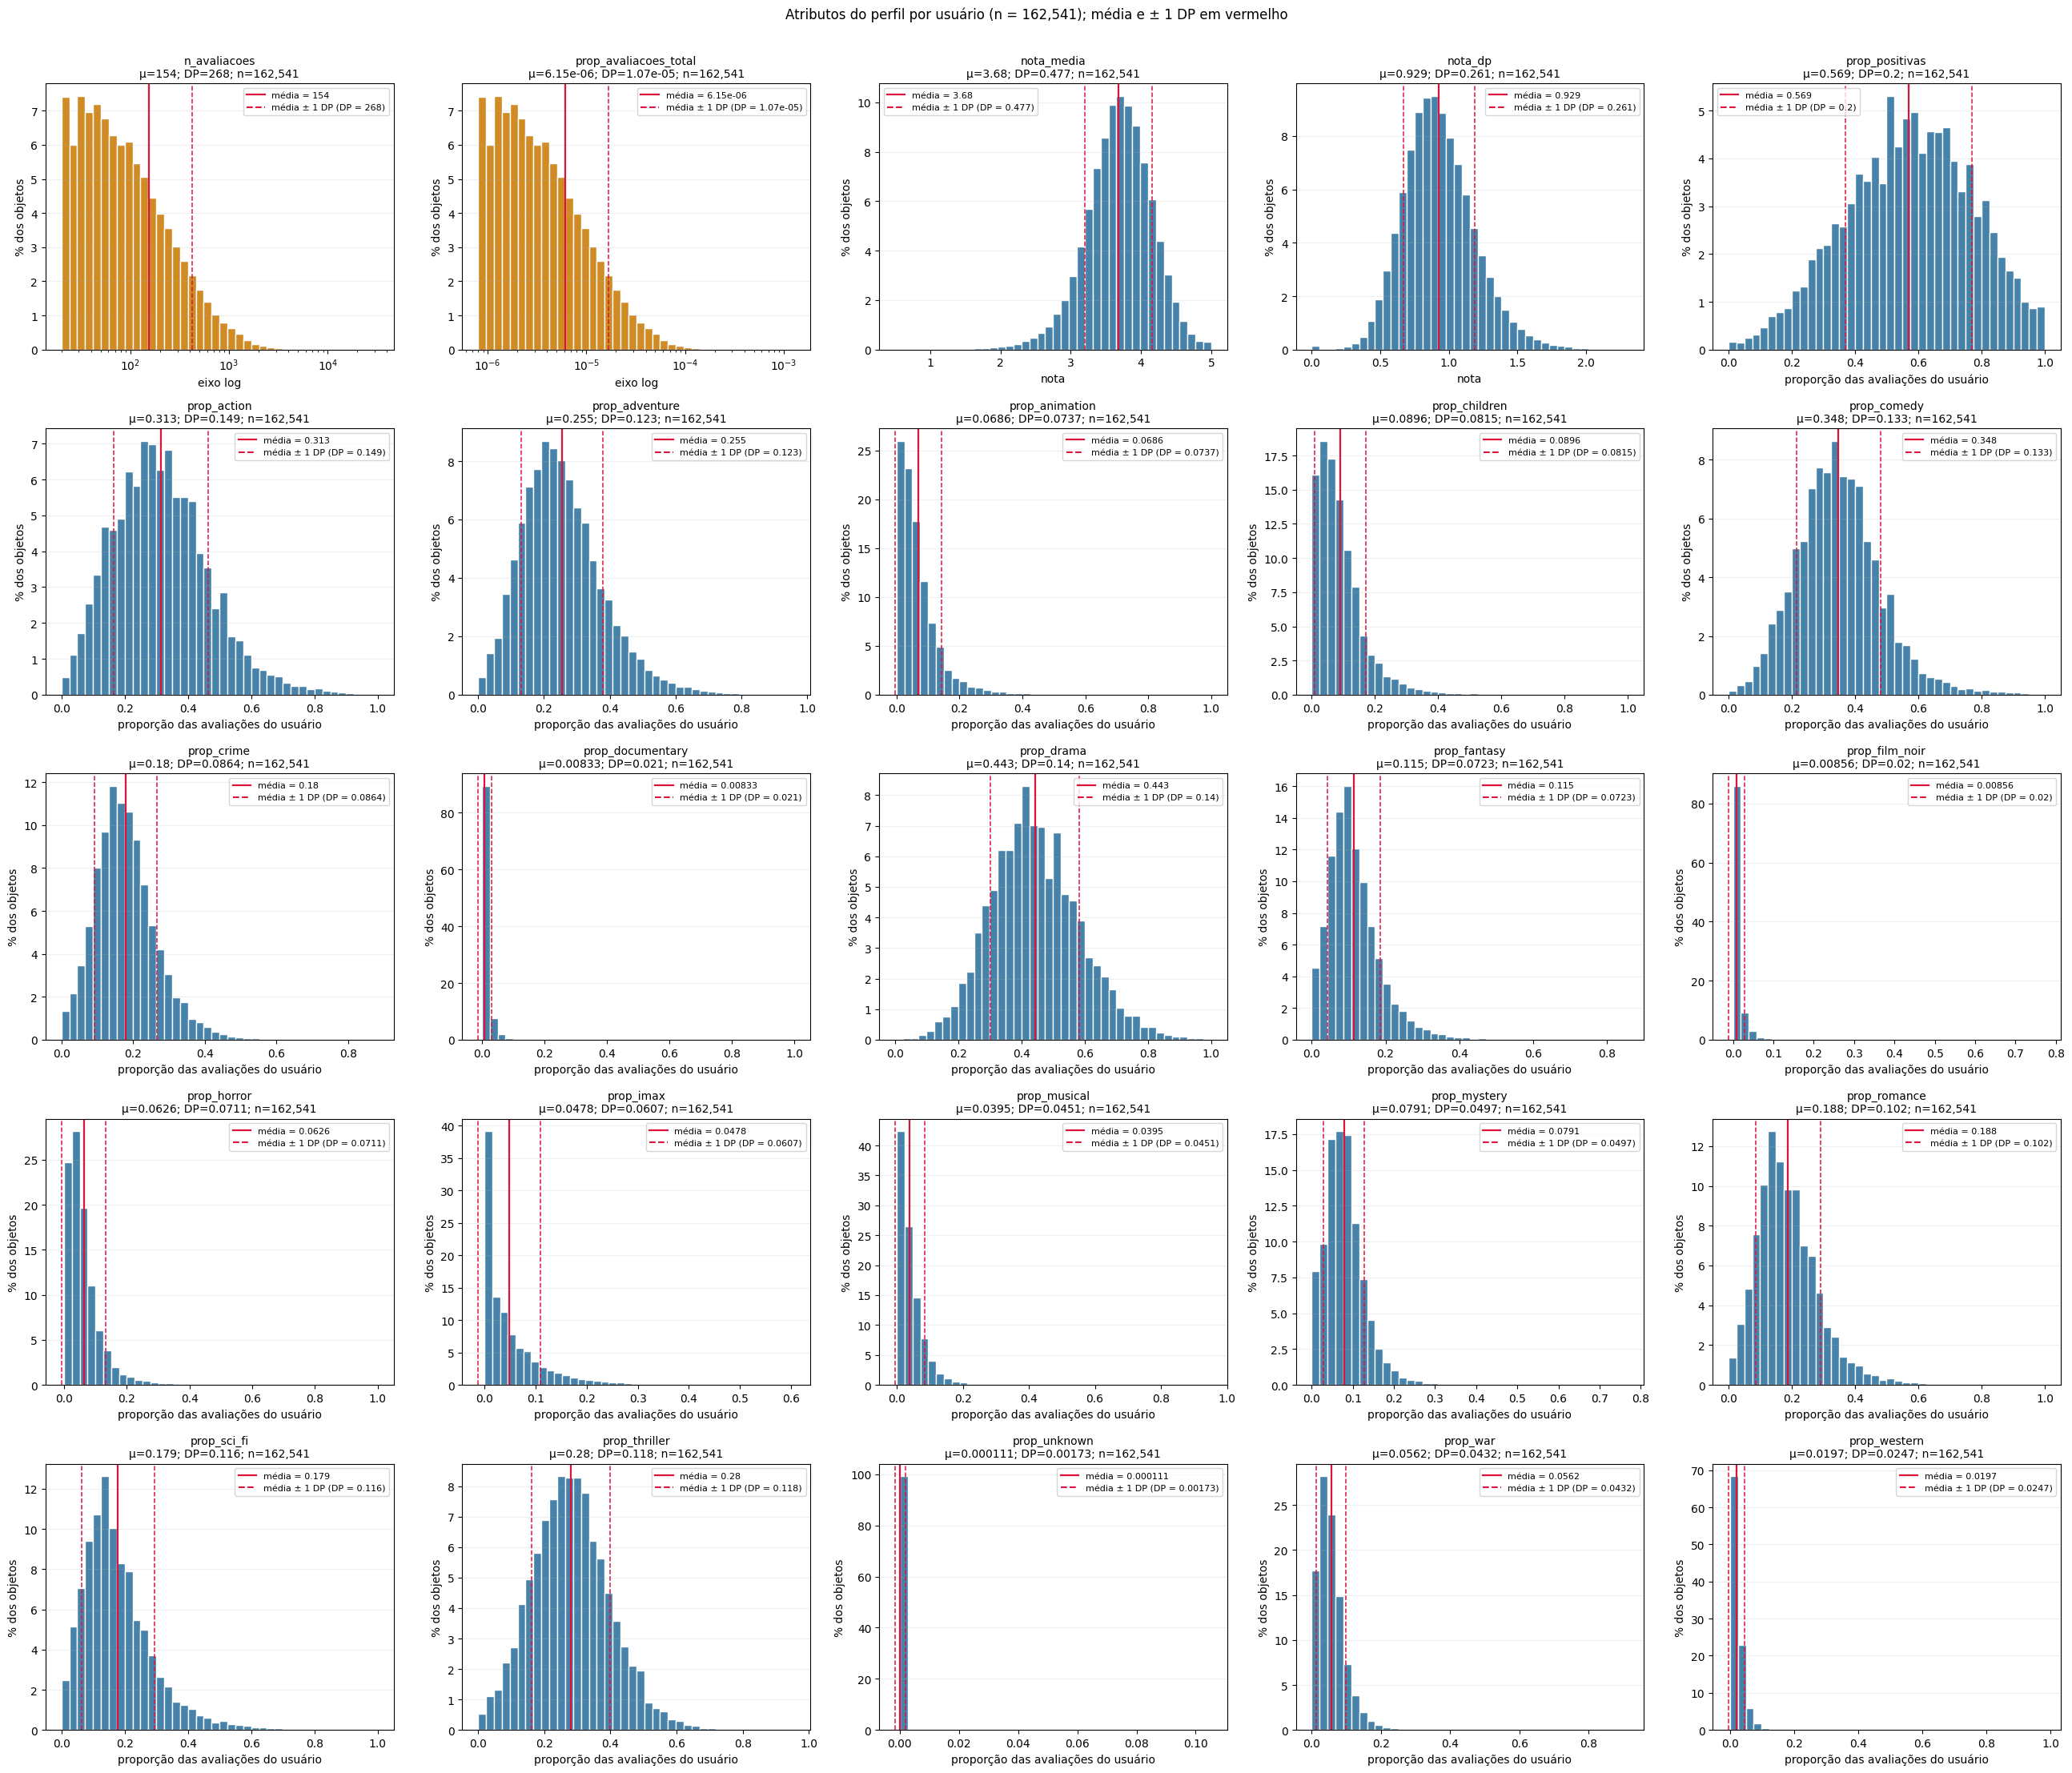

                           mean       std   median     skew  %_zeros
n_avaliacoes           153.8079  268.0476  71.0000  16.3372   0.0000
prop_avaliacoes_total    0.0000    0.0000   0.0000  16.3372   0.0000
nota_media               3.6792    0.4774   3.7000  -0.5585   0.0000
nota_dp                  0.9287    0.2614   0.9076   0.4758   0.1458
prop_positivas           0.5688    0.1996   0.5763  -0.1791   0.1224
prop_action              0.3135    0.1493   0.3030   0.5665   0.3482
prop_adventure           0.2552    0.1233   0.2407   0.7825   0.4430
prop_animation           0.0686    0.0737   0.0500   3.1697  13.7295
prop_children            0.0896    0.0815   0.0722   2.6037   8.7055
prop_comedy              0.3475    0.1333   0.3415   0.6019   0.0984
prop_crime               0.1795    0.0864   0.1707   0.8746   1.0373
prop_documentary         0.0083    0.0210   0.0000  11.9277  62.8198
prop_drama               0.4426    0.1399   0.4328   0.3311   0.0135
prop_fantasy             0.1145   

In [32]:
# [3.1-b] Histogramas dos atributos do perfil, com média e desvio-padrão
atributos_histograma = ["n_avaliacoes"] + atributos_estruturados
fig, axes = plt.subplots(5, 5, figsize=(26, 22))
for ax, atributo in zip(axes.flat, atributos_histograma):
    escala_log = atributo in ("n_avaliacoes", "prop_avaliacoes_total")
    rotulo = "eixo log" if escala_log else ("proporção das avaliações do usuário" if atributo.startswith("prop_") else "nota")
    histograma_media_dp(ax, perfil_pd[atributo], atributo, bins=40, log_x=escala_log,
                        cor="#d18b24" if escala_log else "#4682a9", rotulo_x=rotulo)
fig.suptitle(f"Atributos do perfil por usuário (n = {len(perfil_pd):,}); média e ± 1 DP em vermelho", y=1.005)
plt.tight_layout()
plt.show()
resumo_perfil = perfil_pd[atributos_histograma].agg(["mean", "std", "median", "skew"]).T
resumo_perfil["%_zeros"] = 100 * (perfil_pd[atributos_histograma] == 0).mean()
print(resumo_perfil.round(4).to_string())

**Leitura dos resultados.**

- **Volume:** o número de avaliações por usuário tem assimetria de 16,3 (média 153,8, mediana 71); a participação no total herda a mesma forma.
- **Nota:** a nota média tem assimetria −0,56 (média 3,68); o DP da nota é zero para 0,15% dos usuários, que deram sempre a mesma nota.
- **Gêneros comuns** (Drama, Comedy, Action, Thriller): distribuições próximas de simétricas, com menos de 0,4% de zeros.
- **Gêneros raros:** a maioria dos usuários tem proporção zero em Unknown (98,7%), Documentary (62,8%), Film-Noir (58,3%), Western (32,3%), IMAX (26,8%) e Musical (22,4%). A cauda dos poucos usuários que avaliam esses gêneros explica os valores z extremos de 3.3 e os atípicos de 3.7.

**Consequência:** os gêneros raros pedem tratamento próprio. O vetor revisado (3.8) os agrupa e tira `Unknown`, e a atividade entra em escala logarítmica.

### 3.2 Seleção de características

O trabalho usa a abordagem de **filtro**, porque ela independe do método de aprendizado. *Wrappers* e *embedded* dependem de um algoritmo e acrescentariam um segundo viés.

O CFS procura atributos correlacionados com a classe e pouco correlacionados entre si. Sem classe, só a segunda parte se aplica: os pares são ordenados pelo valor absoluto da correlação, em ordem decrescente. Fisher e ReliefF exigem classes. Depois de P1, eles podem usar os grupos encontrados como classe, mas para **descrever** quais atributos separam os grupos, não para escolher a entrada.

**Critério registrado:** |Pearson| e |Spearman| ≥ 0,9 indicam redundância forte. O limiar é uma escolha explícita e pode ser revisto. Em cada par redundante, mantém-se o atributo que usa a escala completa da nota.

Ranking dos pares por |Pearson| (10 primeiros):
    atributo_1     atributo_2  pearson  spearman  abs_pearson
    nota_media prop_positivas    0.922     0.946        0.922
prop_animation  prop_children    0.823     0.804        0.823
   prop_action prop_adventure    0.674     0.694        0.674
   prop_action    prop_sci_fi    0.659     0.696        0.659
prop_animation   prop_fantasy    0.619     0.607        0.619
 prop_children   prop_musical    0.606     0.568        0.606
prop_adventure   prop_fantasy    0.589     0.548        0.589
prop_adventure     prop_drama   -0.585    -0.585        0.585
 prop_children   prop_fantasy    0.583     0.572        0.583
prop_adventure    prop_sci_fi    0.570     0.613        0.570
Pares com |Pearson| e |Spearman| >= 0.9:
atributo_1     atributo_2  pearson  spearman  abs_pearson
nota_media prop_positivas    0.922     0.946        0.922
- prop_positivas: removido por redundância com nota_media; depende de um limiar de nota ainda a validar
- prop_av

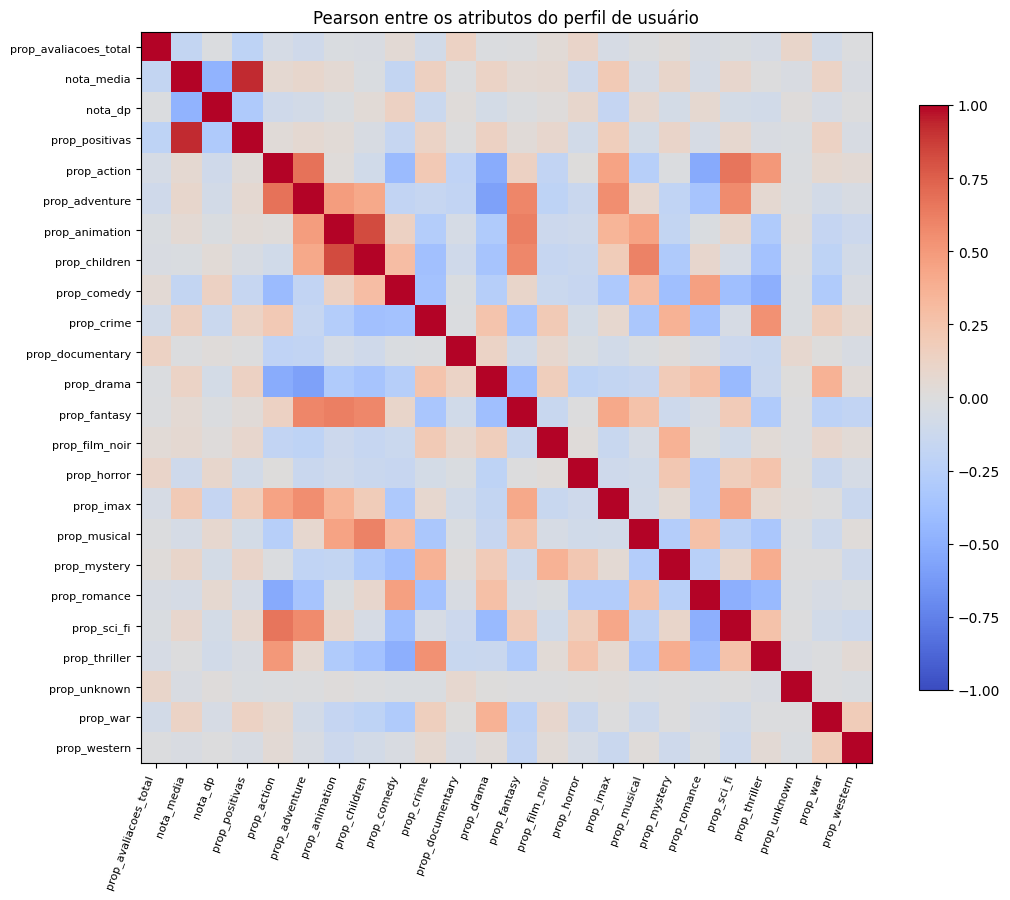

In [33]:
# [3.2] Seleção de características por filtro: redundância entre atributos
LIMIAR_REDUNDANCIA = 0.9
pearson_perfil = perfil_pd[atributos_estruturados].corr(method="pearson")
spearman_perfil = perfil_pd[atributos_estruturados].corr(method="spearman")
ranking = pd.DataFrame(
    [(a, b, pearson_perfil.loc[a, b], spearman_perfil.loc[a, b])
     for i, a in enumerate(atributos_estruturados) for b in atributos_estruturados[i + 1:]],
    columns=["atributo_1", "atributo_2", "pearson", "spearman"])
ranking["abs_pearson"] = ranking["pearson"].abs()
ranking = ranking.sort_values("abs_pearson", ascending=False).reset_index(drop=True)
print("Ranking dos pares por |Pearson| (10 primeiros):")
print(ranking.head(10).round(3).to_string(index=False))

redundantes = ranking[(ranking["pearson"].abs() >= LIMIAR_REDUNDANCIA) & (ranking["spearman"].abs() >= LIMIAR_REDUNDANCIA)]
print(f"Pares com |Pearson| e |Spearman| >= {LIMIAR_REDUNDANCIA}:")
print(redundantes.round(3).to_string(index=False) if len(redundantes) else "nenhum")

decisoes = {
    "prop_positivas": "removido por redundância com nota_media; depende de um limiar de nota ainda a validar",
    "prop_avaliacoes_total": "fora da distância: mede atividade, é muito assimétrico e dominaria a distância; descreve grupos",
}
pares_sem_decisao = redundantes[~redundantes["atributo_1"].isin(decisoes) & ~redundantes["atributo_2"].isin(decisoes)]
if len(pares_sem_decisao):
    print("ATENÇÃO: pares redundantes sem decisão registrada:")
    print(pares_sem_decisao.to_string(index=False))
atributos_p1 = [a for a in atributos_estruturados if a not in decisoes]
for atributo, motivo in decisoes.items():
    print(f"- {atributo}: {motivo}")
print(f"Entrada candidata de P1 ({len(atributos_p1)} atributos):", ", ".join(atributos_p1))

fig, ax = plt.subplots(figsize=(11, 9))
imagem = ax.imshow(pearson_perfil, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(atributos_estruturados)), atributos_estruturados, rotation=70, ha="right", fontsize=8)
ax.set_yticks(range(len(atributos_estruturados)), atributos_estruturados, fontsize=8)
ax.set_title("Pearson entre os atributos do perfil de usuário")
fig.colorbar(imagem, ax=ax, shrink=.8)
plt.tight_layout()
plt.show()

### 3.3 Normalização: padronização × re-escala

A escala muda o peso de cada atributo na distância e no erro do PCA. Duas opções são comparadas:

- **Padronização z-score:** subtrai a média e divide pelo desvio-padrão. Todos os atributos passam a ter a mesma variância, então gêneros raros com pouca variação são ampliados.
- **Re-escala min-max:** leva cada atributo para [0, 1] e preserva diferenças de variância entre atributos.

A coluna `peso_var` mostra a variância do atributo dividida pela soma das variâncias. Ela indica a participação média do atributo na distância euclidiana ao quadrado entre dois usuários.

In [34]:
# [3.3] Normalização: padronização z-score × re-escala min-max
from sklearn.preprocessing import MinMaxScaler, StandardScaler

X_p1_original = perfil_pd[atributos_p1].astype(float)
assert X_p1_original.shape == (162541, 22)
assert np.isfinite(X_p1_original.to_numpy()).all()

scaler_p1 = StandardScaler()
X_p1_padronizado = pd.DataFrame(scaler_p1.fit_transform(X_p1_original), columns=atributos_p1, index=perfil_pd.index)
X_p1_minmax = pd.DataFrame(MinMaxScaler().fit_transform(X_p1_original), columns=atributos_p1, index=perfil_pd.index)
assert np.allclose(X_p1_padronizado.mean(), 0, atol=1e-10)
assert np.allclose(X_p1_padronizado.std(ddof=0), 1, atol=1e-10)
assert X_p1_minmax.min().ge(-1e-12).all() and X_p1_minmax.max().le(1 + 1e-12).all()

comparacao_escalas = pd.DataFrame({
    "media_original": X_p1_original.mean(),
    "dp_original": X_p1_original.std(ddof=0),
    "z_min": X_p1_padronizado.min(),
    "z_max": X_p1_padronizado.max(),
    "peso_var_z_%": 100 * X_p1_padronizado.var(ddof=0) / X_p1_padronizado.var(ddof=0).sum(),
    "peso_var_minmax_%": 100 * X_p1_minmax.var(ddof=0) / X_p1_minmax.var(ddof=0).sum(),
}).round(4)
print("Matrizes candidatas:", X_p1_padronizado.shape, "(z-score) e", X_p1_minmax.shape, "(min-max)")
print(comparacao_escalas.to_string())
extremos = (X_p1_padronizado.abs() > 10).sum()
print("Usuários com |z| > 10 por atributo:", extremos[extremos > 0].to_dict())

Matrizes candidatas: (162541, 22) (z-score) e (162541, 22) (min-max)
                  media_original  dp_original   z_min    z_max  peso_var_z_%  peso_var_minmax_%
nota_media                3.6792       0.4774 -6.6599   2.7668        4.5455             5.8106
nota_dp                   0.9287       0.2614 -3.5523   5.2778        4.5455             6.6224
prop_action               0.3135       0.1493 -2.0993   4.5970        4.5455            11.5155
prop_adventure            0.2552       0.1233 -2.0691   5.7283        4.5455             8.4927
prop_animation            0.0686       0.0737 -0.9306  12.6345        4.5455             2.8061
prop_children             0.0896       0.0815 -1.0999  11.1757        4.5455             3.4266
prop_comedy               0.3475       0.1333 -2.6072   4.8950        4.5455             9.1741
prop_crime                0.1795       0.0864 -2.0778   8.1331        4.5455             4.9525
prop_documentary          0.0083       0.0210 -0.3967  47.2155     

### 3.4 PCA e escolha de d′

O PCA é aplicado à matriz padronizada, que já está centrada e em escala comparável. Nesse caso, a covariância equivale à matriz de correlação.

Critérios para escolher d′:

- **Scree plot** com variância explicada e acumulada; o limiar de 80% é um parâmetro registrado;
- **Broken-stick:** retém os componentes iniciais cuja variância supera a esperada para autovalores aleatórios;
- **Kaiser-Guttman:** retém autovalores ≥ 1 em dados padronizados.

Cada critério tem seu próprio viés. A matriz PCA é uma alternativa a comparar em P1, não uma substituição obrigatória dos 22 atributos.

 componente  autovalor  variancia_%  acumulada_%  broken_stick_%
          1     4.2687      19.4030      19.4030         16.7764
          2     4.0634      18.4699      37.8729         12.2310
          3     1.8729       8.5129      46.3858          9.9582
          4     1.5090       6.8590      53.2448          8.4431
          5     1.2022       5.4644      58.7092          7.3067
          6     1.1710       5.3226      64.0317          6.3976
          7     1.0016       4.5527      68.5845          5.6401
          8     0.9557       4.3439      72.9283          4.9907
          9     0.9153       4.1603      77.0886          4.4225
         10     0.8559       3.8905      80.9791          3.9175
         11     0.6737       3.0622      84.0413          3.4629
         12     0.5981       2.7188      86.7601          3.0497
         13     0.5116       2.3257      89.0857          2.6709
         14     0.4598       2.0901      91.1758          2.3213
         15     0.4358   

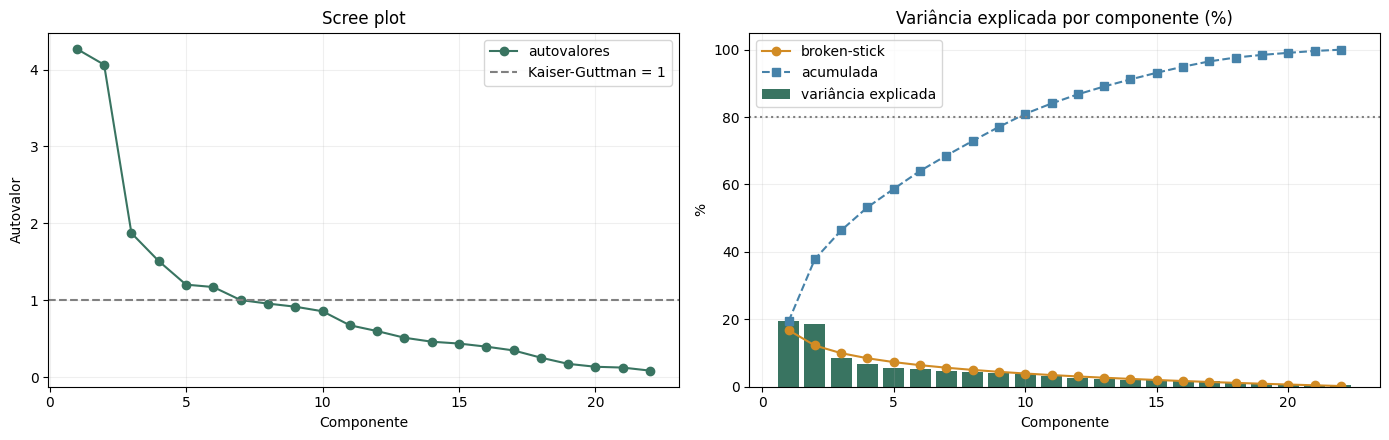

Atributos com maior carga absoluta em cada componente retido:
CP1: prop_children (+0.39), prop_animation (+0.38), prop_fantasy (+0.37), prop_adventure (+0.35)
CP2: prop_action (+0.41), prop_romance (-0.37), prop_sci_fi (+0.36), prop_comedy (-0.34)
CP3: nota_media (+0.48), nota_dp (-0.41), prop_horror (-0.38), prop_drama (+0.35)
CP4: prop_mystery (+0.50), prop_western (-0.39), prop_film_noir (+0.37), prop_horror (+0.33)
CP5: prop_western (+0.43), nota_dp (+0.35), prop_film_noir (+0.32), prop_musical (+0.31)
CP6: prop_documentary (+0.52), prop_unknown (+0.47), nota_dp (+0.32), prop_thriller (-0.25)
CP7: prop_western (+0.47), prop_unknown (+0.38), nota_dp (-0.37), prop_documentary (+0.37)
Matriz candidata no espaço PCA: (162541, 7); variância retida = 68.58%


In [35]:
# [3.4] PCA sobre a matriz padronizada e critérios para d'
from sklearn.decomposition import PCA

pca_completo = PCA(svd_solver="full").fit(X_p1_padronizado)
autovalores = pca_completo.explained_variance_
p = len(autovalores)
prop_var = pca_completo.explained_variance_ratio_
acumulada = np.cumsum(prop_var)
broken_stick = np.array([sum(1 / i for i in range(k, p + 1)) / p for k in range(1, p + 1)])

LIMIAR_VARIANCIA = 0.80
d_kaiser = int((autovalores >= 1).sum())
acima_broken = prop_var > broken_stick
d_broken = p if acima_broken.all() else int(np.argmin(acima_broken))
d_variancia = int(np.searchsorted(acumulada, LIMIAR_VARIANCIA) + 1)

tabela_pca = pd.DataFrame({
    "componente": np.arange(1, p + 1), "autovalor": autovalores, "variancia_%": 100 * prop_var,
    "acumulada_%": 100 * acumulada, "broken_stick_%": 100 * broken_stick}).round(4)
print(tabela_pca.to_string(index=False))
print(f"d' por Kaiser-Guttman (autovalor >= 1): {d_kaiser}")
print(f"d' por broken-stick: {d_broken}")
print(f"d' para {LIMIAR_VARIANCIA:.0%} da variância acumulada: {d_variancia}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(range(1, p + 1), autovalores, "o-", color="#397461", label="autovalores")
axes[0].axhline(1, ls="--", color="gray", label="Kaiser-Guttman = 1")
axes[0].set(title="Scree plot", xlabel="Componente", ylabel="Autovalor")
axes[0].legend()
axes[1].bar(range(1, p + 1), 100 * prop_var, color="#397461", label="variância explicada")
axes[1].plot(range(1, p + 1), 100 * broken_stick, "o-", color="#d18b24", label="broken-stick")
axes[1].plot(range(1, p + 1), 100 * acumulada, "s--", color="#4682a9", label="acumulada")
axes[1].axhline(100 * LIMIAR_VARIANCIA, ls=":", color="gray")
axes[1].set(title="Variância explicada por componente (%)", xlabel="Componente", ylabel="%")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

# Candidato registrado: Kaiser-Guttman, por ser o critério estatístico definido para dados padronizados.
d_pca = d_kaiser
assert 1 <= d_pca <= p
cargas = pd.DataFrame(pca_completo.components_[:d_pca].T, index=atributos_p1,
                      columns=[f"CP{k}" for k in range(1, d_pca + 1)])
print("Atributos com maior carga absoluta em cada componente retido:")
for cp in cargas.columns:
    principais = cargas[cp].abs().sort_values(ascending=False).head(4).index
    print(f"{cp}: " + ", ".join(f"{a} ({cargas.loc[a, cp]:+.2f})" for a in principais))
X_p1_pca = pd.DataFrame(pca_completo.transform(X_p1_padronizado)[:, :d_pca], columns=cargas.columns, index=perfil_pd.index)
print(f"Matriz candidata no espaço PCA: {X_p1_pca.shape}; variância retida = {100 * acumulada[d_pca - 1]:.2f}%")

### 3.5 Dimensionalidade e concentração de distâncias

Em alta dimensionalidade, as distâncias tendem a se concentrar: a menor e a maior ficam proporcionalmente próximas, o que prejudica métodos baseados em distância. Como P1 usará distâncias entre usuários, a célula mede a distribuição de pares de distância em uma amostra fixa de 2.000 usuários. As medidas usadas são:

- **Contraste relativo** = (máx − mín) / mín;
- **Variância relativa** = desvio-padrão / média das distâncias.

Valores menores indicam mais concentração. As medidas são comparadas nos três espaços candidatos.

Amostra fixa de 2,000 usuários (semente 42); distância euclidiana
                espaço   pares  média     DP    mín     máx  contraste_relativo  variancia_relativa
z-score (22 atributos) 1999000 6.0853 2.3521 0.7691 33.3141             42.3138              0.3865
min-max (22 atributos) 1999000 0.5818 0.2021 0.0727  1.8573             24.5483              0.3473
   PCA (7 componentes) 1999000 5.0027 2.1263 0.2514 23.5805             92.7915              0.4250


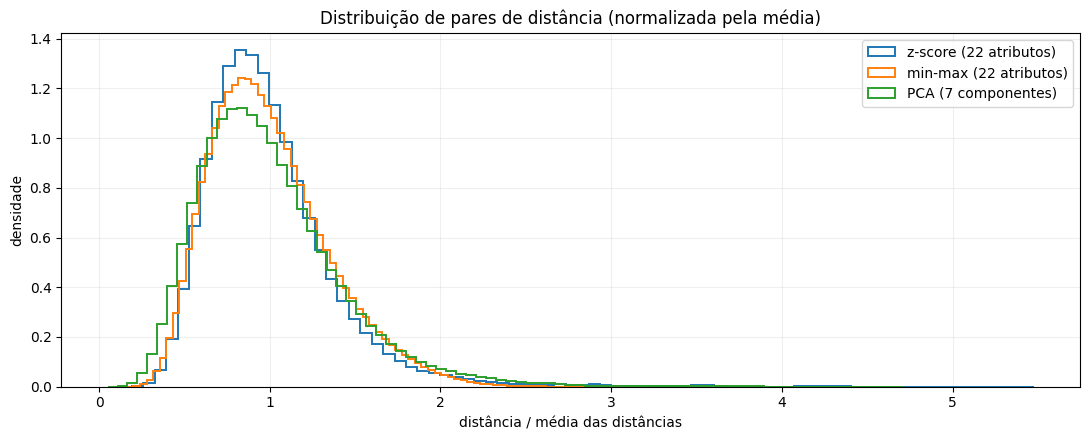

In [36]:
# [3.5] Concentração de distâncias nos espaços candidatos
from scipy.spatial.distance import pdist

N_AMOSTRA_DIST = 2000
idx_dist = perfil_pd.sample(n=N_AMOSTRA_DIST, random_state=42).index
espacos = {
    f"z-score ({X_p1_padronizado.shape[1]} atributos)": X_p1_padronizado,
    f"min-max ({X_p1_minmax.shape[1]} atributos)": X_p1_minmax,
    f"PCA ({X_p1_pca.shape[1]} componentes)": X_p1_pca,
}
linhas_dist, distancias = [], {}
for nome, X in espacos.items():
    d = pdist(X.loc[idx_dist].to_numpy(), metric="euclidean")
    d = d[d > 0]  # pares idênticos não entram no contraste relativo
    distancias[nome] = d
    linhas_dist.append((nome, len(d), d.mean(), d.std(), d.min(), d.max(),
                        (d.max() - d.min()) / d.min(), d.std() / d.mean()))
tabela_dist = pd.DataFrame(linhas_dist, columns=["espaço", "pares", "média", "DP", "mín", "máx",
                                                 "contraste_relativo", "variancia_relativa"])
print(f"Amostra fixa de {N_AMOSTRA_DIST:,} usuários (semente 42); distância euclidiana")
print(tabela_dist.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 4.5))
for nome, d in distancias.items():
    ax.hist(d / d.mean(), bins=80, histtype="step", density=True, linewidth=1.4, label=nome)
ax.set(title="Distribuição de pares de distância (normalizada pela média)",
       xlabel="distância / média das distâncias", ylabel="densidade")
ax.legend()
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

#### Dimensionalidade intrínseca

A dimensionalidade intrínseca estima quantas dimensões efetivas descrevem a estrutura dos dados, independentemente do número de atributos. O estimador de máxima verossimilhança de Levina–Bickel usa as distâncias aos k vizinhos mais próximos (k = 10 a 20) em uma amostra fixa. Valores bem menores que 22 indicam atributos correlacionados e reforçam a redução por PCA.

In [37]:
# [3.5-b] Dimensionalidade intrínseca estimada por máxima verossimilhança (Levina–Bickel)
from sklearn.neighbors import NearestNeighbors

def dimensao_intrinseca_mle(X, k1=10, k2=20):
    distancias_viz, _ = NearestNeighbors(n_neighbors=k2 + 1).fit(X).kneighbors(X)
    distancias_viz = np.maximum(distancias_viz[:, 1:], 1e-12)  # descarta o próprio ponto
    estimativas = []
    for k in range(k1, k2 + 1):
        soma_logs = np.log(distancias_viz[:, [k - 1]] / distancias_viz[:, :k - 1]).sum(axis=1)
        estimativas.append(np.mean((k - 1) / np.maximum(soma_logs, 1e-12)))
    return float(np.mean(estimativas)), [float(e) for e in estimativas]

N_AMOSTRA_ID = 10_000
idx_id = perfil_pd.sample(n=N_AMOSTRA_ID, random_state=42).index
linhas_id = []
for nome, X in [("z-score (22 atributos)", X_p1_padronizado), ("PCA (7 componentes)", X_p1_pca)]:
    media_id, por_k = dimensao_intrinseca_mle(X.loc[idx_id].to_numpy())
    linhas_id.append((nome, X.shape[1], media_id, min(por_k), max(por_k)))
tabela_id = pd.DataFrame(linhas_id, columns=["espaço", "dimensões", "ID_MLE (média k=10..20)", "mín", "máx"])
print(f"Amostra fixa de {N_AMOSTRA_ID:,} usuários (semente 42)")
print(tabela_id.round(2).to_string(index=False))

Amostra fixa de 10,000 usuários (semente 42)
                espaço  dimensões  ID_MLE (média k=10..20)   mín   máx
z-score (22 atributos)         22                    13.33 12.77 14.15
   PCA (7 componentes)          7                     7.12  6.89  7.48


**Leitura dos resultados.** A dimensionalidade intrínseca estimada é de cerca de 13 no espaço padronizado de 22 atributos (12,8 a 14,2, conforme k) e de cerca de 7 no espaço PCA de 7 componentes. Os 22 atributos têm redundância, mas a estrutura dos dados não cabe em duas ou três dimensões.

**Consequência:** o PCA com 7 componentes (68,58% da variância) é uma redução útil para as distâncias, mas descarta parte da estrutura. O critério de 80% da variância (10 componentes) fica mais próximo da dimensionalidade intrínseca e é uma alternativa a testar em P1.

### 3.6 Visualização do espaço transformado

Projeções 2D de uma amostra fixa de usuários:

- **PCA:** os dois primeiros componentes;
- **MDS:** preserva as distâncias entre pares, calculado em 500 usuários por custo computacional;
- **t-SNE:** preserva vizinhanças locais, aplicado sobre o espaço PCA;
- **coordenadas paralelas:** os 22 atributos padronizados.

Antes de P1 não há grupos. Por isso, a cor indica o grupo da nota média do usuário, só como referência visual.

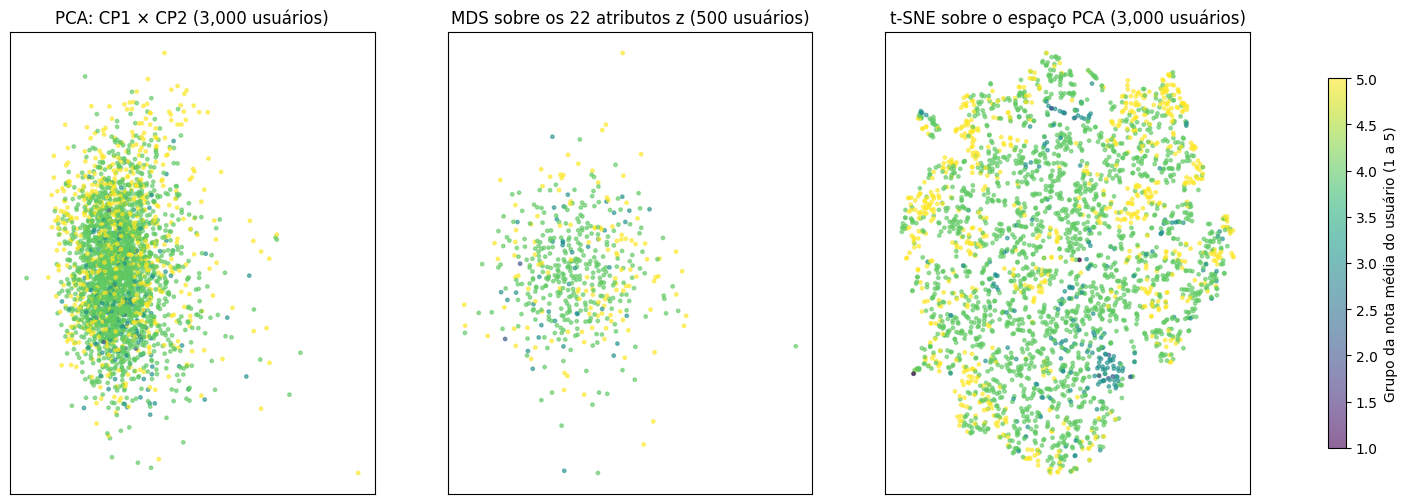

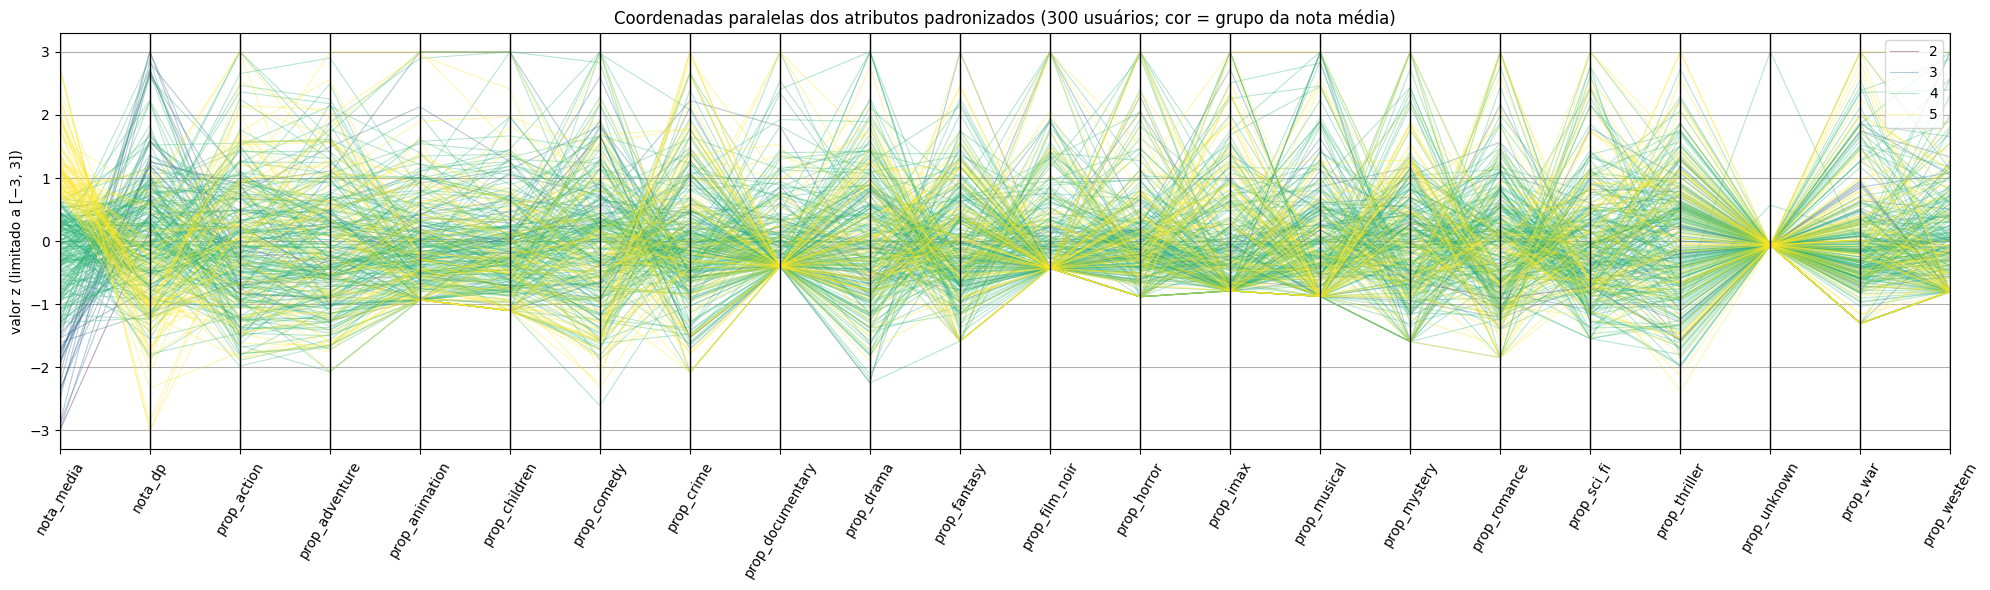

In [38]:
# [3.6] Visualização do espaço transformado: PCA 2D, MDS, t-SNE e coordenadas paralelas
from sklearn.manifold import MDS, TSNE

idx_vis = perfil_pd.sample(n=3000, random_state=7).index
grupo_media_vis = np.ceil(perfil_pd.loc[idx_vis, "nota_media"]).clip(1, 5).astype(int).to_numpy()
pca_2d = X_p1_pca.loc[idx_vis, ["CP1", "CP2"]].to_numpy()
tsne_2d = TSNE(n_components=2, perplexity=30, init="pca", random_state=42).fit_transform(X_p1_pca.loc[idx_vis].to_numpy())
idx_mds = idx_vis[:500]
mds_2d = MDS(n_components=2, n_init=1, max_iter=300, random_state=42).fit_transform(X_p1_padronizado.loc[idx_mds].to_numpy())

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
projecoes = [
    (axes[0], pca_2d, grupo_media_vis, f"PCA: CP1 × CP2 ({len(idx_vis):,} usuários)"),
    (axes[1], mds_2d, grupo_media_vis[:len(idx_mds)], f"MDS sobre os 22 atributos z ({len(idx_mds)} usuários)"),
    (axes[2], tsne_2d, grupo_media_vis, f"t-SNE sobre o espaço PCA ({len(idx_vis):,} usuários)"),
]
for ax, coords, cor, titulo in projecoes:
    pontos = ax.scatter(coords[:, 0], coords[:, 1], c=cor, cmap="viridis", s=6, alpha=.6, vmin=1, vmax=5)
    ax.set_title(titulo)
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(pontos, ax=axes, shrink=.8, label="Grupo da nota média do usuário (1 a 5)")
plt.show()

# Coordenadas paralelas: 300 usuários, 22 atributos padronizados (limitados a [−3, 3] apenas no gráfico).
paralelas = X_p1_padronizado.loc[idx_vis[:300]].clip(-3, 3).copy()
paralelas["grupo_nota_media"] = grupo_media_vis[:300].astype(str)
fig, ax = plt.subplots(figsize=(20, 6))
pd.plotting.parallel_coordinates(paralelas.sort_values("grupo_nota_media"), "grupo_nota_media", ax=ax,
                                 colormap="viridis", alpha=.35, linewidth=.8)
ax.set_title("Coordenadas paralelas dos atributos padronizados (300 usuários; cor = grupo da nota média)")
ax.tick_params(axis="x", rotation=60)
ax.set_ylabel("valor z (limitado a [−3, 3])")
plt.tight_layout()
plt.show()

**Leitura dos resultados.**

- **Projeções 2D:** PCA, MDS e t-SNE mostram uma nuvem contínua de usuários, sem grupos isolados.
- **Nota média:** a cor não organiza a estrutura principal. Usuários com médias diferentes aparecem misturados, com poucas regiões locais de médias mais baixas ou mais altas no t-SNE.
- **Coordenadas paralelas:** a variação entre usuários está sobretudo nas proporções de gênero.

**Consequência:** espera-se que um agrupamento produza regiões de um contínuo, definidas principalmente pela composição de gêneros, e não grupos naturalmente separados.

### 3.7 Preparação para o agrupamento: valores atípicos e tendência de agrupamento

Antes de P1, duas verificações no espaço transformado.

**Valores atípicos.** O k-means e outros métodos baseados em médias são sensíveis a objetos muito afastados, que deslocam os centróides. Atípicos podem ser objetos legítimos, e não erros: aqui seriam usuários com gosto muito concentrado em poucos gêneros. Três critérios são calculados:

- **(a) univariado:** |z| > 3 em cada atributo padronizado;
- **(b) multivariado:** distância de Mahalanobis ao centro no espaço PCA, comparada ao quantil 0,999 da χ² com 7 graus de liberdade (referência sob normalidade multivariada);
- **(c) vizinhança:** distância ao 10º vizinho mais próximo acima do percentil 99.

Um usuário é marcado como atípico quando está longe do centro (b) **e** isolado dos vizinhos (c). Quem está longe do centro, mas tem vizinhos próximos, pode formar um grupo de nicho e não é marcado. Nenhum usuário é removido: a marcação `atipico` permite comparar P1 com e sem esses usuários.

(a) |z| > 3 em pelo menos um dos 22 atributos: 31,863 de 162,541 usuários (19.60%)
                  usuarios_|z|>3  %_usuarios  assimetria
prop_imax                   3367       2.071       2.066
prop_animation              3025       1.861       3.170
prop_children               2653       1.632       2.604
prop_sci_fi                 2535       1.560       1.679
prop_horror                 2526       1.554       4.540
prop_musical                2423       1.491       3.647
prop_fantasy                2392       1.472       1.506
prop_film_noir              2324       1.430       9.574
prop_documentary            2306       1.419      11.928
prop_romance                2111       1.299       1.433

(b) Mahalanobis² > χ²(0,999; 7 gl) = 24.32: 4,008 usuários (2.47%); sob normalidade multivariada seriam esperados 163 (0,10%)



(c) Distância ao 10º vizinho > percentil 99 (2.313): 1,626 usuários (1% por construção); mediana da distância = 0.839

Atípicos (b e c ao mesmo tempo): 1,409 usuários (0.87%)
Longe do centro, mas com vizinhos próximos (possível nicho, não marcado): 2,599
Isolados, mas perto do centro (não marcados): 217

Atributo com maior |z| em cada usuário atípico (10 mais frequentes):
prop_unknown        329
prop_documentary    207
prop_western        196
prop_film_noir      173
prop_musical         86
prop_war             81
prop_horror          73
prop_animation       69
prop_mystery         59
nota_dp              35

Atípicos × demais usuários:
              atípicos (mediana)  demais (mediana)
n_avaliacoes              40.000            71.000
nota_media                 3.793             3.700
nota_dp                    0.940             0.907


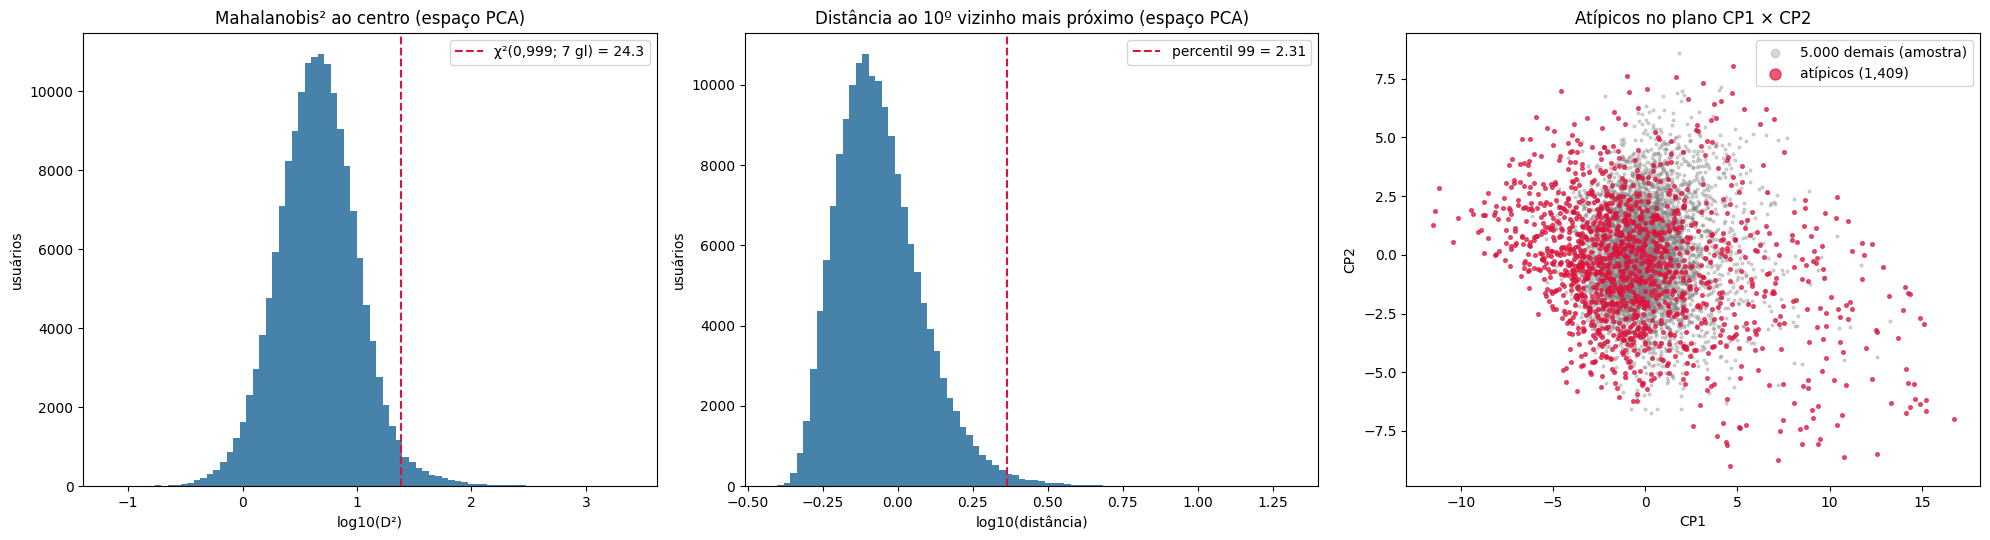

In [39]:
# [3.7-a] Valores atípicos no espaço do perfil: |z| por atributo, Mahalanobis e distância ao 10º vizinho
from scipy import stats
from sklearn.neighbors import NearestNeighbors

n_usuarios = len(X_p1_padronizado)

# (a) Univariado: |z| > 3 em cada atributo padronizado (regra indicativa: vários atributos são assimétricos).
LIMIAR_Z = 3
acima_z = X_p1_padronizado.abs() > LIMIAR_Z
algum_z = acima_z.any(axis=1)
tabela_z = pd.DataFrame({
    "usuarios_|z|>3": acima_z.sum(),
    "%_usuarios": 100 * acima_z.mean(),
    "assimetria": X_p1_original.skew(),
}).sort_values("usuarios_|z|>3", ascending=False)
print(f"(a) |z| > {LIMIAR_Z} em pelo menos um dos {X_p1_padronizado.shape[1]} atributos: "
      f"{algum_z.sum():,} de {n_usuarios:,} usuários ({100 * algum_z.mean():.2f}%)")
print(tabela_z.head(10).round(3).to_string())

# (b) Multivariado: distância de Mahalanobis ao centro no espaço PCA (cada componente dividido pela sua variância).
X_pca_np = X_p1_pca.to_numpy()
centrado = X_pca_np - X_pca_np.mean(axis=0)
d2_mahal = (centrado ** 2 / centrado.var(axis=0)).sum(axis=1)
GL = X_pca_np.shape[1]
LIMIAR_D2 = stats.chi2.ppf(0.999, df=GL)
longe_centro = d2_mahal > LIMIAR_D2
print(f"\n(b) Mahalanobis² > χ²(0,999; {GL} gl) = {LIMIAR_D2:.2f}: {longe_centro.sum():,} usuários "
      f"({100 * longe_centro.mean():.2f}%); sob normalidade multivariada seriam esperados {0.001 * n_usuarios:,.0f} (0,10%)")

# (c) Vizinhança: distância ao 10º vizinho mais próximo no espaço PCA (a coluna 0 é o próprio usuário).
K_VIZ = 10
dist_viz, _ = NearestNeighbors(n_neighbors=K_VIZ + 1, n_jobs=-1).fit(X_pca_np).kneighbors(X_pca_np)
dist_k = dist_viz[:, K_VIZ]
LIMIAR_K = np.quantile(dist_k, 0.99)
isolado = dist_k > LIMIAR_K
print(f"\n(c) Distância ao {K_VIZ}º vizinho > percentil 99 ({LIMIAR_K:.3f}): {isolado.sum():,} usuários (1% por construção); "
      f"mediana da distância = {np.median(dist_k):.3f}")

# Marcação: atípico = longe do centro (b) e isolado dos vizinhos (c) ao mesmo tempo.
atipico = longe_centro & isolado
perfil_pd["atipico"] = atipico
print(f"\nAtípicos (b e c ao mesmo tempo): {atipico.sum():,} usuários ({100 * atipico.mean():.2f}%)")
print(f"Longe do centro, mas com vizinhos próximos (possível nicho, não marcado): {(longe_centro & ~isolado).sum():,}")
print(f"Isolados, mas perto do centro (não marcados): {(isolado & ~longe_centro).sum():,}")

atributo_dominante = X_p1_padronizado[atipico].abs().idxmax(axis=1).value_counts()
print("\nAtributo com maior |z| em cada usuário atípico (10 mais frequentes):")
print(atributo_dominante.head(10).to_string())
comparacao_atipicos = pd.DataFrame({
    "atípicos (mediana)": perfil_pd.loc[atipico, ["n_avaliacoes", "nota_media", "nota_dp"]].median(),
    "demais (mediana)": perfil_pd.loc[~atipico, ["n_avaliacoes", "nota_media", "nota_dp"]].median(),
})
print("\nAtípicos × demais usuários:")
print(comparacao_atipicos.round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
axes[0].hist(np.log10(d2_mahal), bins=80, color="#4682a9")
axes[0].axvline(np.log10(LIMIAR_D2), color="crimson", ls="--", label=f"χ²(0,999; {GL} gl) = {LIMIAR_D2:.1f}")
axes[0].set(title="Mahalanobis² ao centro (espaço PCA)", xlabel="log10(D²)", ylabel="usuários")
axes[0].legend()
axes[1].hist(np.log10(np.maximum(dist_k, 1e-6)), bins=80, color="#4682a9")
axes[1].axvline(np.log10(LIMIAR_K), color="crimson", ls="--", label=f"percentil 99 = {LIMIAR_K:.2f}")
axes[1].set(title=f"Distância ao {K_VIZ}º vizinho mais próximo (espaço PCA)", xlabel="log10(distância)", ylabel="usuários")
axes[1].legend()
rng_atip = np.random.default_rng(42)
idx_demais = rng_atip.choice(np.flatnonzero(~atipico), size=5000, replace=False)
idx_atipicos = np.flatnonzero(atipico)
axes[2].scatter(X_pca_np[idx_demais, 0], X_pca_np[idx_demais, 1], s=4, alpha=.3, color="grey", label="5.000 demais (amostra)")
axes[2].scatter(X_pca_np[idx_atipicos, 0], X_pca_np[idx_atipicos, 1], s=7, alpha=.7, color="crimson",
                label=f"atípicos ({len(idx_atipicos):,})")
axes[2].set(title="Atípicos no plano CP1 × CP2", xlabel="CP1", ylabel="CP2")
axes[2].legend(markerscale=3)
plt.tight_layout()
plt.show()

**Leitura dos resultados.**

- **(a) |z| > 3:** 31.863 usuários (19,60%) passam do limite em pelo menos um atributo. Nos dez atributos com mais casos, a fração vai de 1,30% a 2,07% (IMAX, Animation, Children, Sci-Fi e Horror lideram), bem acima dos 0,27% esperados numa normal. As proporções de gêneros raros são muito assimétricas: 28,1 em Unknown, 11,9 em Documentary e 9,6 em Film-Noir. Com caudas tão longas, a regra univariada marca a cauda de cada atributo, não casos isolados, e não serve sozinha como critério.
- **(b) Mahalanobis:** 4.008 usuários (2,47%) passam do quantil 0,999 da χ² com 7 graus de liberdade, cerca de 25 vezes os 163 esperados sob normalidade. A nuvem de usuários tem caudas mais pesadas que uma normal multivariada.
- **(c) Vizinhança:** o limite do percentil 99 (2,31) é 2,8 vezes a mediana da distância ao 10º vizinho (0,839).
- **Atípicos marcados:** 1.409 usuários (0,87%) estão longe do centro e isolados ao mesmo tempo. Outros 2.599 estão longe do centro, mas têm vizinhos próximos (possíveis nichos), e só 217 estão isolados perto do centro.
- **Quem são:** em quase todos, o atributo mais extremo é um gênero raro: Unknown (329 usuários, 23% dos atípicos), Documentary (207), Western (196) e Film-Noir (173). Eles avaliam menos filmes (mediana de 40 contra 71) e dão notas um pouco mais altas (mediana da média 3,79 contra 3,70). Com poucas avaliações, poucos filmes de um gênero raro bastam para gerar uma proporção extrema.
- **Gráfico:** no plano CP1 × CP2 os atípicos se espalham pela borda, mas também se sobrepõem ao centro, porque se afastam sobretudo nos componentes 4 a 7, que carregam Western, Documentary, Film-Noir e Unknown.

**Limitação:** os limiares (quantil 0,999 e percentil 99) são escolhas registradas, e a referência χ² supõe normalidade, que os dados não seguem.

**Consequência:** os 1.409 usuários são mantidos e ficam marcados em `perfil_pd["atipico"]`, para que P1 seja executado com e sem eles. Além disso, `prop_unknown` não mede preferência, e sim falta de informação de gênero no catálogo, e, mesmo depois da imputação de 2.2-b, é o atributo dominante de 329 atípicos. P1 deve testar também a entrada sem esse atributo.

#### Tendência de agrupamento

Um algoritmo de agrupamento sempre devolve grupos, mesmo em dados sem estrutura. A estatística de Hopkins verifica, antes de P1, se os usuários se distribuem de forma diferente de pontos uniformes no mesmo domínio:

- **u:** distância de um ponto uniforme ao usuário real mais próximo;
- **w:** distância de um usuário real sorteado ao seu vizinho real mais próximo;
- **H = Σu / (Σu + Σw):** H ≈ 0,5 indica dados indistinguíveis de pontos uniformes; H próximo de 1 indica dados concentrados em regiões.

O cálculo usa 1.000 pontos por repetição e 10 repetições, nos dois espaços candidatos, com e sem os atípicos. Como os valores extremos alargam o domínio mín–máx e inflam H, o domínio dos percentis 1–99 é usado como versão robusta. Um controle com dados uniformes de mesmo tamanho deve dar H ≈ 0,5.

**Limite da medida:** H mede concentração, não separação. Um único aglomerado denso também dá H alto. A separação entre grupos só pode ser avaliada em P1.

Estatística de Hopkins: m = 1,000 pontos por repetição, 10 repetições (semente 42); distância euclidiana
      espaço                 população domínio dos pontos uniformes      n  H médio     DP
     PCA (7)                     todos                      min-max 162541   0.9636 0.0005
     PCA (7)                     todos               percentis 1–99 162541   0.7148 0.0033
     PCA (7)              sem atípicos                      min-max 161132   0.9266 0.0007
     PCA (7)              sem atípicos               percentis 1–99 161132   0.7020 0.0025
z-score (22)                     todos                      min-max 162541   0.9592 0.0004
z-score (22)                     todos               percentis 1–99 162541   0.7663 0.0021
z-score (22)              sem atípicos                      min-max 161132   0.9388 0.0005
z-score (22)              sem atípicos               percentis 1–99 161132   0.7625 0.0019
     PCA (7) controle: dados uniformes                      min-max 162541  

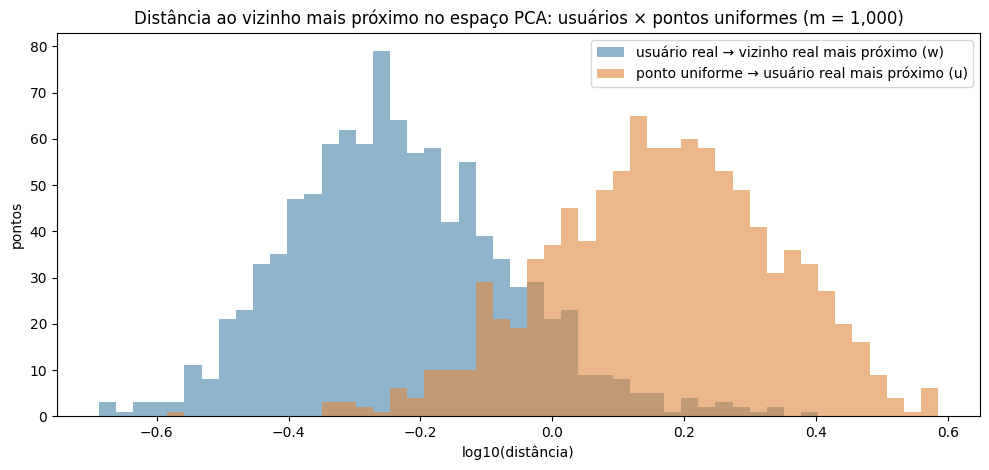

In [40]:
# [3.7-b] Tendência de agrupamento: estatística de Hopkins contra pontos uniformes no mesmo domínio
from sklearn.neighbors import NearestNeighbors

M_HOPKINS, REPETICOES_HOPKINS = 1000, 10


def hopkins(X, dominio="min-max", m=M_HOPKINS, repeticoes=REPETICOES_HOPKINS, semente=42):
    """H = Σu / (Σu + Σw).
    u: distância de um ponto uniforme ao usuário real mais próximo; w: distância de um usuário real sorteado
    ao vizinho real mais próximo. H ≈ 0,5: dados indistinguíveis de uniformes; H → 1: dados concentrados."""
    X = np.asarray(X, dtype=float)
    n, d = X.shape
    vizinhos = NearestNeighbors(n_neighbors=2).fit(X)
    if dominio == "min-max":
        inferior, superior = X.min(axis=0), X.max(axis=0)
    else:  # percentis 1 a 99: domínio menos influenciado pelos valores extremos
        inferior, superior = np.percentile(X, 1, axis=0), np.percentile(X, 99, axis=0)
    rng = np.random.default_rng(semente)
    valores = []
    for _ in range(repeticoes):
        sorteados = rng.choice(n, size=m, replace=False)
        w = vizinhos.kneighbors(X[sorteados], n_neighbors=2)[0][:, 1]
        u = vizinhos.kneighbors(rng.uniform(inferior, superior, size=(m, d)), n_neighbors=1)[0][:, 0]
        valores.append(u.sum() / (u.sum() + w.sum()))
    return float(np.mean(valores)), float(np.std(valores)), u, w


sem_atipicos = ~perfil_pd["atipico"].to_numpy()
cenarios_hopkins = [
    ("PCA (7)", "todos", X_p1_pca.to_numpy()),
    ("PCA (7)", "sem atípicos", X_p1_pca.to_numpy()[sem_atipicos]),
    ("z-score (22)", "todos", X_p1_padronizado.to_numpy()),
    ("z-score (22)", "sem atípicos", X_p1_padronizado.to_numpy()[sem_atipicos]),
]
linhas_hopkins = []
for espaco, populacao, X in cenarios_hopkins:
    for dominio in ["min-max", "percentis 1–99"]:
        h_medio, h_dp, u, w = hopkins(X, dominio)
        linhas_hopkins.append((espaco, populacao, dominio, len(X), h_medio, h_dp))
        if (espaco, populacao, dominio) == ("PCA (7)", "todos", "percentis 1–99"):
            u_vis, w_vis = u, w

# Controle: dados uniformes com o mesmo tamanho, no domínio dos percentis 1–99 de cada espaço.
for espaco, X in [("PCA (7)", X_p1_pca.to_numpy()), ("z-score (22)", X_p1_padronizado.to_numpy())]:
    X_uniforme = np.random.default_rng(0).uniform(np.percentile(X, 1, axis=0), np.percentile(X, 99, axis=0), size=X.shape)
    h_medio, h_dp, _, _ = hopkins(X_uniforme, "min-max")
    linhas_hopkins.append((espaco, "controle: dados uniformes", "min-max", len(X_uniforme), h_medio, h_dp))

tabela_hopkins = pd.DataFrame(linhas_hopkins, columns=["espaço", "população", "domínio dos pontos uniformes", "n",
                                                       "H médio", "DP"])
print(f"Estatística de Hopkins: m = {M_HOPKINS:,} pontos por repetição, {REPETICOES_HOPKINS} repetições (semente 42); "
      "distância euclidiana")
print(tabela_hopkins.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4.8))
log_w, log_u = np.log10(np.maximum(w_vis, 1e-3)), np.log10(np.maximum(u_vis, 1e-3))
bins = np.linspace(min(log_w.min(), log_u.min()), max(log_w.max(), log_u.max()), 50)
ax.hist(log_w, bins=bins, alpha=.6, color="#4682a9", label="usuário real → vizinho real mais próximo (w)")
ax.hist(log_u, bins=bins, alpha=.6, color="#e08a3c", label="ponto uniforme → usuário real mais próximo (u)")
ax.set(title=f"Distância ao vizinho mais próximo no espaço PCA: usuários × pontos uniformes (m = {M_HOPKINS:,})",
       xlabel="log10(distância)", ylabel="pontos")
ax.legend()
plt.tight_layout()
plt.show()

**Leitura dos resultados.**

- **Controle:** com dados uniformes, H = 0,500 nos dois espaços, o que confirma o cálculo.
- **Domínio mín–máx:** H = 0,964 no PCA e 0,959 no z-score. Esses valores são inflados pelos extremos, que alargam o domínio dos pontos uniformes: sem os 1.409 atípicos, caem para 0,927 e 0,939.
- **Domínio robusto (percentis 1–99):** H = 0,715 no PCA e 0,766 no z-score; sem os atípicos, 0,702 e 0,762. O desvio-padrão entre repetições é no máximo 0,0033.
- **Distâncias:** no histograma, a distância de um usuário ao vizinho real mais próximo (w) fica, em geral, abaixo da distância de um ponto uniforme ao usuário mais próximo (u), mas as duas distribuições se sobrepõem em parte.

**Interpretação:** os usuários estão mais concentrados do que pontos uniformes, e isso não é efeito dos atípicos, porque retirá-los quase não muda o H robusto. Mas a tendência é moderada: uma referência usual é H > 0,75 para tendência clara, e o espaço PCA fica abaixo dela. Junto com as projeções de 3.6, o quadro é de um núcleo denso com caudas, e não de grupos naturalmente separados.

**Consequência:** vale agrupar, porque os dados não são uniformes, mas deve-se esperar separação fraca entre grupos. A validação de P1 precisa comparar os índices com os de partições de dados uniformes no mesmo domínio.

### 3.8 Vetor revisado: atributos derivados e limite de gêneros

O vetor base (3.1–3.2) tem três limitações observadas nas seções anteriores:

- as proporções de gênero de um usuário somam mais que 1, porque os gêneros se sobrepõem;
- gêneros raros e `Unknown` geram os valores extremos e a maior parte dos atípicos (3.3 e 3.7);
- a atividade do usuário ficou fora da distância.

O vetor revisado mantém a lógica de proporções com denominador explícito e acrescenta:

- **proporção fracionária:** cada avaliação distribui peso 1/k entre os k gêneros do filme, e o vetor de gêneros soma 1;
- **limite de gêneros:** gêneros com menos de 2% das avaliações formam o grupo `raros`, e `Unknown` sai do vetor, porque registra falta de informação, não preferência;
- **atributos derivados:** viés do usuário (nota menos a média do filme), atividade em escala log, popularidade média e ano médio dos filmes avaliados, e diversidade de gêneros (entropia normalizada);
- **gênero dominante:** atributo categórico, usado só para descrever.

A seleção por filtro usa o mesmo limiar de 3.2: em cada par redundante, sai o atributo com maior |Pearson| médio com os demais.

Participação de cada gênero nas avaliações (contagem fracionária; limite = 2%):
     gênero  participação_%                                destino
      Drama          20.646                                mantido
     Comedy          16.837                                mantido
     Action           9.356                                mantido
   Thriller           9.122                                mantido
  Adventure           6.930                                mantido
    Romance           6.713                                mantido
      Crime           5.715                                mantido
     Sci-Fi           5.535                                mantido
    Fantasy           3.252                                mantido
     Horror           3.163                                mantido
    Mystery           2.475                                mantido
   Children           2.375                                mantido
        War           1.795                      


Pares mais associados entre os 20 candidatos:
    atributo_1     atributo_2  pearson  spearman
    nota_media   vies_usuario    0.903     0.881
   frac_action frac_adventure    0.635     0.656
frac_adventure     frac_drama   -0.614    -0.634
   frac_action     frac_drama   -0.597    -0.605
   frac_action    frac_sci_fi    0.583     0.640
frac_adventure   frac_fantasy    0.533     0.491
   frac_action   frac_romance   -0.525    -0.554
frac_adventure    frac_sci_fi    0.519     0.565
Removidos por redundância: nenhum
Vetor revisado (20 atributos): nota_media, nota_dp, vies_usuario, atividade_log, popularidade_media, ano_medio_lancamento, diversidade_generos, frac_action, frac_adventure, frac_children, frac_comedy, frac_crime, frac_drama, frac_fantasy, frac_horror, frac_mystery, frac_romance, frac_sci_fi, frac_thriller, frac_raros
Gênero dominante (descreve; fica fora da distância): {'drama': 54.25, 'comedy': 27.86, 'action': 8.0, 'thriller': 3.55, 'adventure': 1.7, 'raros': 1.63, 'sci_f

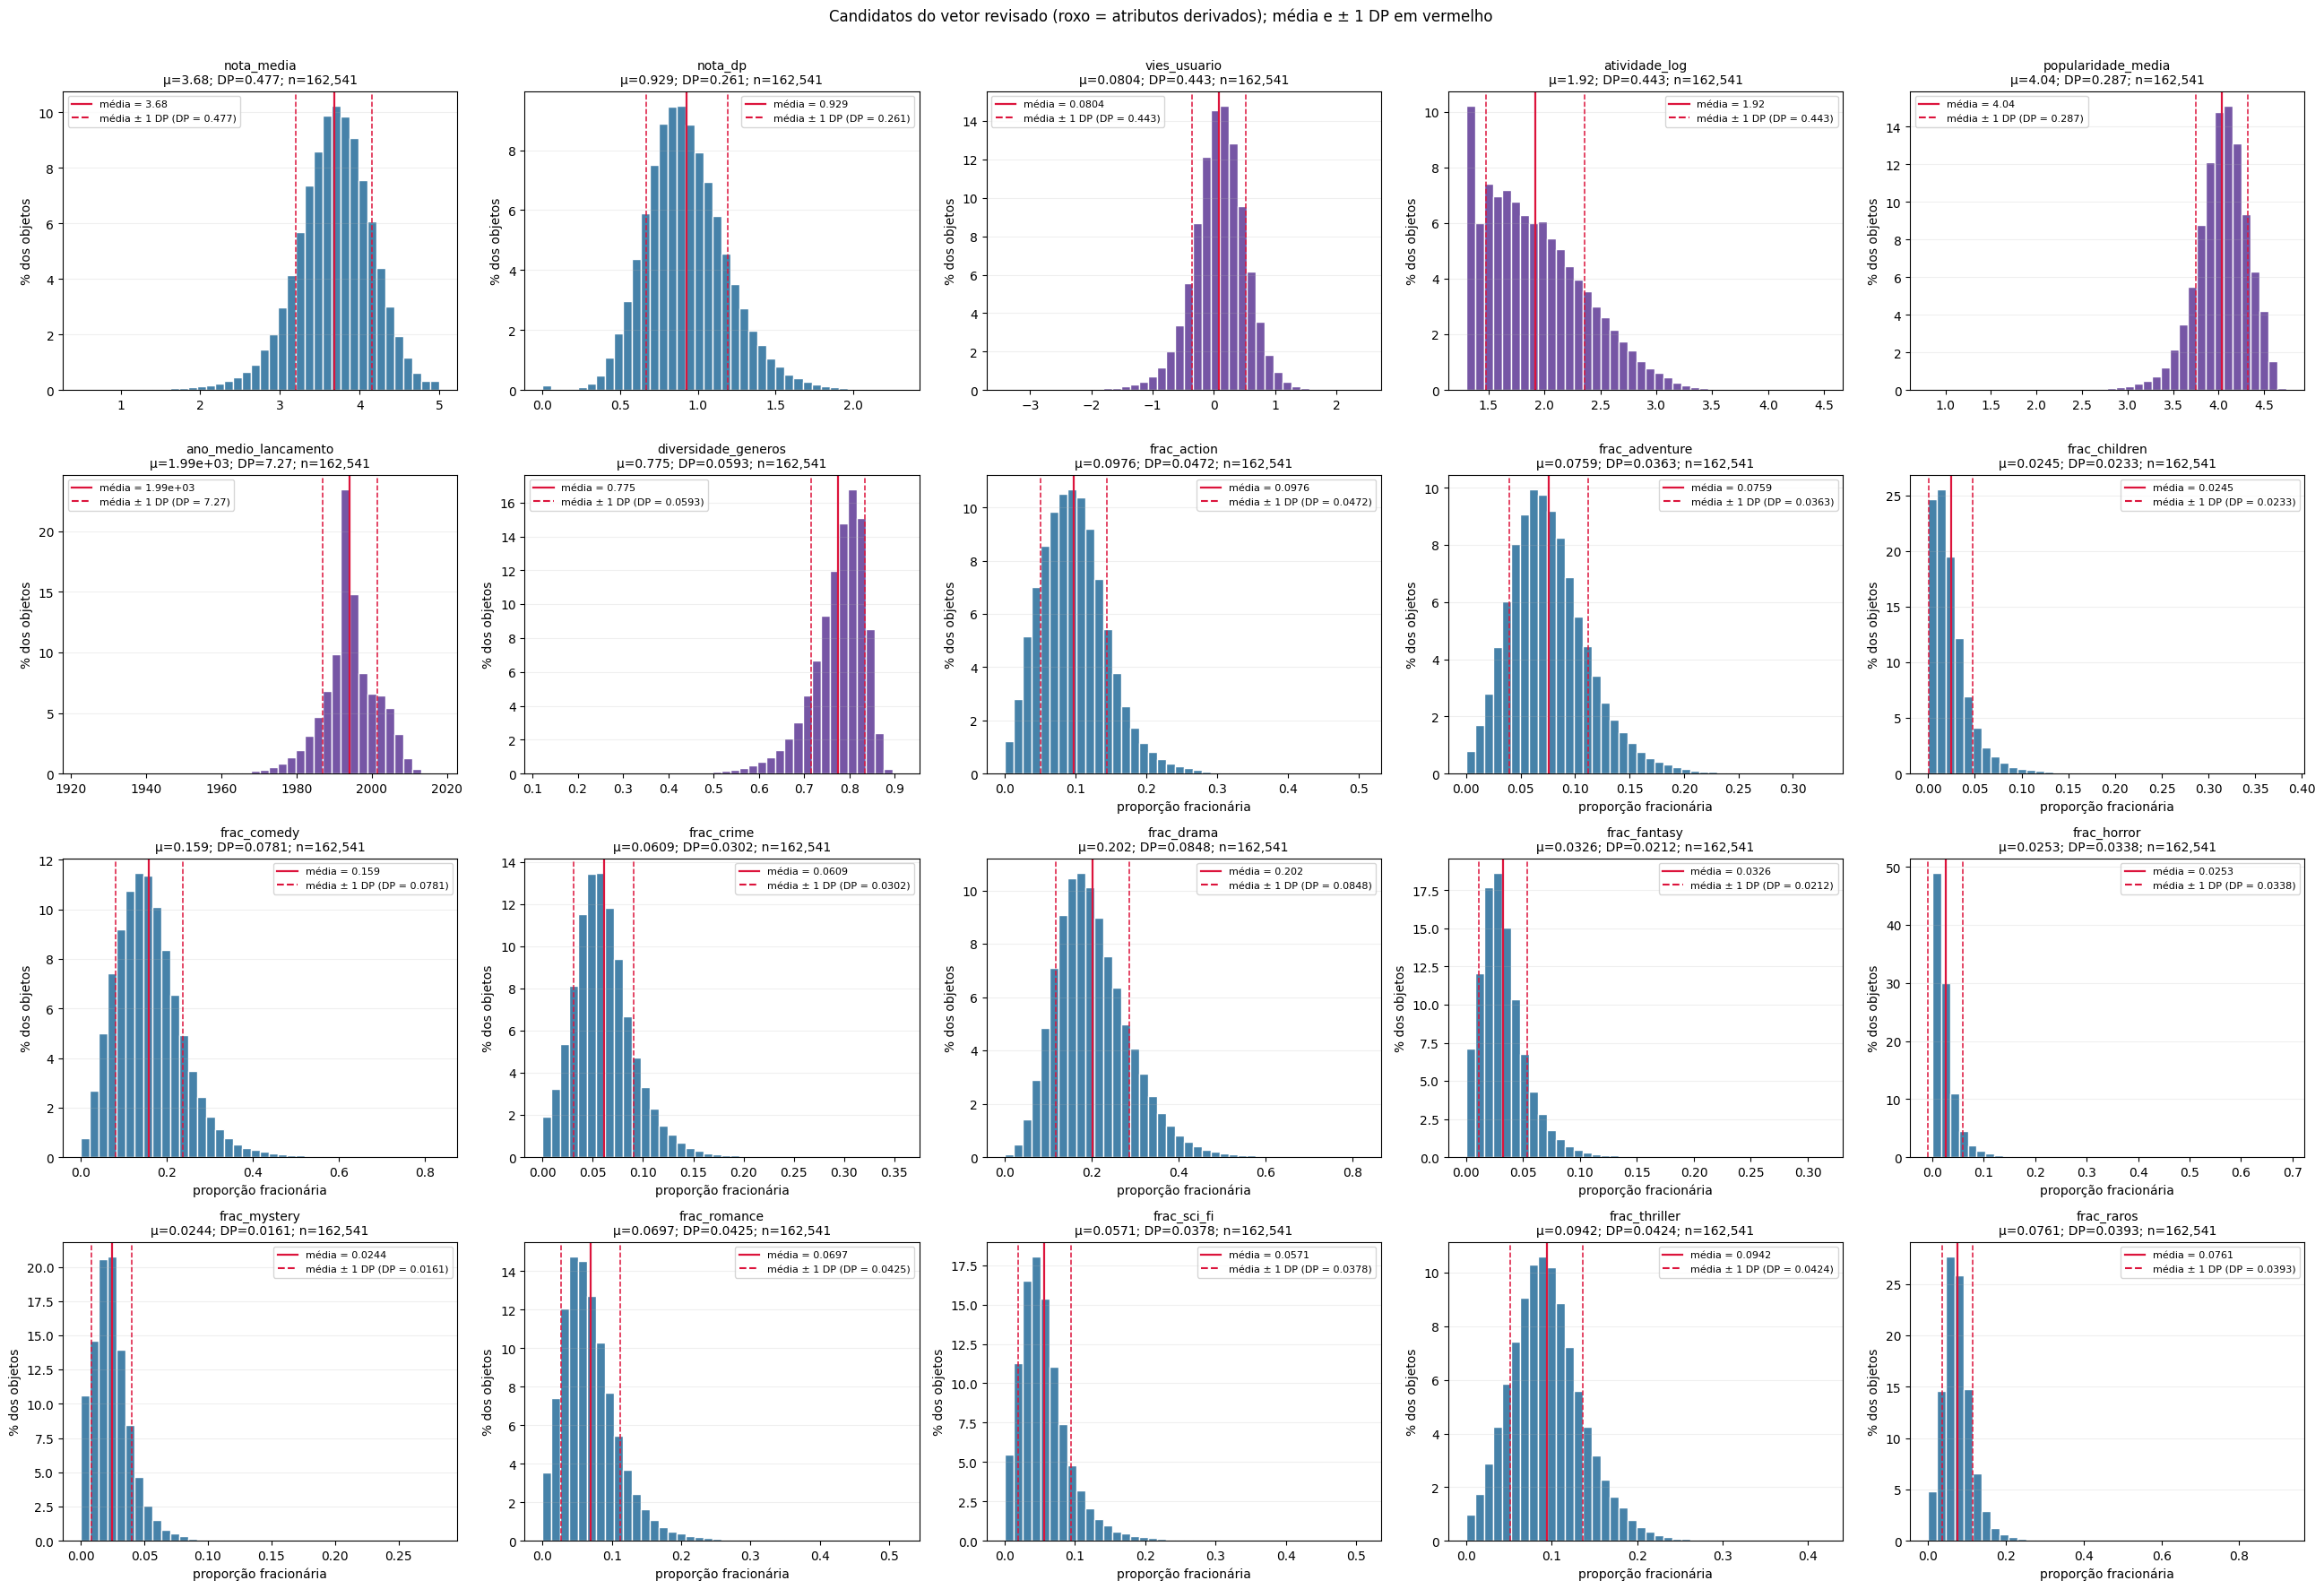

In [41]:
# [3.8-a] Vetor revisado: atributos derivados, proporções fracionárias e limite de gêneros
LIMITE_GENERO = 0.02  # gêneros com menos de 2% das avaliações (contagem fracionária) formam o grupo "raros"

filmes_info = (ratings_clean.groupBy("movieId").agg(F.count("*").alias("n_filme"), F.avg("rating").alias("media_filme"))
    .join(movies_clean.select("movieId", "title", "genres"), "movieId")
    .withColumn("ano_txt", F.regexp_extract(F.trim(F.col("title")), r"\((\d{4})\)$", 1))
    .withColumn("ano_lancamento", F.when(F.col("ano_txt") != "", F.col("ano_txt").cast("double")))
    .withColumn("n_generos_filme", F.size(F.split(F.col("genres"), r"\|")))
    .withColumn("log_n_filme", F.log10(F.col("n_filme")))
    .select("movieId", "media_filme", "ano_lancamento", "n_generos_filme", "log_n_filme")
    .cache())
derivados_pd = (ratings_clean.select("userId", "movieId", "rating")
    .join(F.broadcast(filmes_info), "movieId")
    .groupBy("userId").agg(
        F.avg(F.col("rating") - F.col("media_filme")).alias("vies_usuario"),
        F.avg("log_n_filme").alias("popularidade_media"),
        F.avg("ano_lancamento").alias("ano_medio_lancamento"))
    .toPandas())
# Proporção fracionária: cada avaliação distribui peso 1/k entre os k gêneros do filme; o vetor de gêneros soma 1.
frac_pd = (ratings_genres.select("userId", "movieId", "genre")
    .join(F.broadcast(filmes_info.select("movieId", "n_generos_filme")), "movieId")
    .groupBy("userId").pivot("genre", lista_generos).agg(F.sum(1.0 / F.col("n_generos_filme")))
    .toPandas().fillna(0.0)
    .rename(columns={g: "frac_" + sufixo[g] for g in lista_generos}))
cols_frac = ["frac_" + sufixo[g] for g in lista_generos]
perfil_rev_pd = (perfil_pd[["userId", "n_avaliacoes", "nota_media", "nota_dp", "atipico"]]
                 .merge(derivados_pd, on="userId", how="left").merge(frac_pd, on="userId", how="left"))
assert len(perfil_rev_pd) == len(perfil_pd)
assert (perfil_rev_pd["userId"].to_numpy() == perfil_pd["userId"].to_numpy()).all()
perfil_rev_pd.index = perfil_pd.index
perfil_rev_pd[cols_frac] = perfil_rev_pd[cols_frac].div(perfil_rev_pd["n_avaliacoes"], axis=0)
assert np.allclose(perfil_rev_pd[cols_frac].sum(axis=1), 1.0, atol=1e-9)

# Limite de gêneros: participação de cada gênero no total de avaliações, com contagem fracionária.
massa_genero = (perfil_rev_pd[cols_frac].mul(perfil_rev_pd["n_avaliacoes"], axis=0).sum()
                / perfil_rev_pd["n_avaliacoes"].sum())
destino = {g: ("fora: falta de gênero, não preferência" if g == "Unknown"
               else "mantido" if massa_genero["frac_" + sufixo[g]] >= LIMITE_GENERO else "agrupado em raros")
           for g in lista_generos}
tabela_generos = (pd.DataFrame({"gênero": lista_generos,
                                "participação_%": [100 * massa_genero["frac_" + sufixo[g]] for g in lista_generos],
                                "destino": [destino[g] for g in lista_generos]})
                  .sort_values("participação_%", ascending=False))
print(f"Participação de cada gênero nas avaliações (contagem fracionária; limite = {100 * LIMITE_GENERO:.0f}%):")
print(tabela_generos.round(3).to_string(index=False))
generos_mantidos = [g for g in lista_generos if destino[g] == "mantido"]
generos_raros = [g for g in lista_generos if destino[g] == "agrupado em raros"]
perfil_rev_pd["frac_raros"] = perfil_rev_pd[["frac_" + sufixo[g] for g in generos_raros]].sum(axis=1)

# Atributos derivados.
perfil_rev_pd["atividade_log"] = np.log10(perfil_rev_pd["n_avaliacoes"])
p_generos = perfil_rev_pd[cols_frac].to_numpy()
with np.errstate(divide="ignore", invalid="ignore"):
    entropia = -np.where(p_generos > 0, p_generos * np.log(p_generos), 0.0).sum(axis=1)
perfil_rev_pd["diversidade_generos"] = entropia / np.log(len(cols_frac))
sem_ano = perfil_rev_pd["ano_medio_lancamento"].isna()
print(f"\nUsuários sem nenhum filme com ano no título: {int(sem_ano.sum())}")
if sem_ano.any():
    perfil_rev_pd.loc[sem_ano, "ano_medio_lancamento"] = perfil_rev_pd["ano_medio_lancamento"].median()
perfil_rev_pd["genero_dominante"] = (perfil_rev_pd[["frac_" + sufixo[g] for g in generos_mantidos] + ["frac_raros"]]
                                     .idxmax(axis=1).str.replace("frac_", "", regex=False))

ATRIBUTOS_DERIVADOS = ["vies_usuario", "atividade_log", "popularidade_media", "ano_medio_lancamento", "diversidade_generos"]
candidatos_rev = (["nota_media", "nota_dp"] + ATRIBUTOS_DERIVADOS
                  + ["frac_" + sufixo[g] for g in generos_mantidos] + ["frac_raros"])
print("\nAtributos derivados (por usuário):")
print("  vies_usuario = média de (nota do usuário − média do filme): rigor do usuário sem o efeito dos filmes escolhidos")
print("  atividade_log = log10(avaliações do usuário); popularidade_media = média de log10(avaliações dos filmes avaliados)")
print("  ano_medio_lancamento = média do ano dos filmes avaliados; diversidade_generos = entropia das proporções / log(20)")
print(perfil_rev_pd[ATRIBUTOS_DERIVADOS].describe().T[["mean", "std", "min", "50%", "max"]].round(4).to_string())

# Seleção por filtro, com o mesmo limiar de 3.2: em cada par redundante sai o atributo de maior |Pearson| médio com os demais.
pearson_rev = perfil_rev_pd[candidatos_rev].corr(method="pearson")
spearman_rev = perfil_rev_pd[candidatos_rev].corr(method="spearman")
atributos_rev, removidos_rev = list(candidatos_rev), {}
while True:
    p_abs = pearson_rev.loc[atributos_rev, atributos_rev].abs().to_numpy(copy=True)
    s_abs = spearman_rev.loc[atributos_rev, atributos_rev].abs().to_numpy(copy=True)
    np.fill_diagonal(p_abs, 0.0)
    np.fill_diagonal(s_abs, 0.0)
    redundante = (p_abs >= LIMIAR_REDUNDANCIA) & (s_abs >= LIMIAR_REDUNDANCIA)
    if not redundante.any():
        break
    i, j = np.unravel_index(np.argmax(np.where(redundante, p_abs, 0.0)), p_abs.shape)
    media_abs = p_abs.sum(axis=1) / (len(atributos_rev) - 1)
    sai, fica = (atributos_rev[i], atributos_rev[j]) if media_abs[i] >= media_abs[j] else (atributos_rev[j], atributos_rev[i])
    removidos_rev[sai] = (f"redundante com {fica} (Pearson {pearson_rev.loc[sai, fica]:.3f}; "
                          f"Spearman {spearman_rev.loc[sai, fica]:.3f}); maior |Pearson| médio com os demais")
    atributos_rev.remove(sai)
pares_rev = pd.DataFrame([(a, b, pearson_rev.loc[a, b], spearman_rev.loc[a, b])
                          for k, a in enumerate(candidatos_rev) for b in candidatos_rev[k + 1:]],
                         columns=["atributo_1", "atributo_2", "pearson", "spearman"])
pares_rev = pares_rev.reindex(pares_rev["pearson"].abs().sort_values(ascending=False).index)
print(f"\nPares mais associados entre os {len(candidatos_rev)} candidatos:")
print(pares_rev.head(8).round(3).to_string(index=False))
print("Removidos por redundância:", removidos_rev if removidos_rev else "nenhum")
print(f"Vetor revisado ({len(atributos_rev)} atributos):", ", ".join(atributos_rev))
print("Gênero dominante (descreve; fica fora da distância):",
      perfil_rev_pd["genero_dominante"].value_counts(normalize=True).mul(100).round(2).head(8).to_dict())

colunas_hist = candidatos_rev
n_linhas = int(np.ceil(len(colunas_hist) / 5))
fig, axes = plt.subplots(n_linhas, 5, figsize=(26, 4.4 * n_linhas))
for ax, coluna in zip(axes.flat, colunas_hist):
    histograma_media_dp(ax, perfil_rev_pd[coluna], coluna, bins=40,
                        cor="#7656a5" if coluna in ATRIBUTOS_DERIVADOS else "#4682a9",
                        rotulo_x="proporção fracionária" if coluna.startswith("frac_") else "")
for ax in list(axes.flat)[len(colunas_hist):]:
    ax.axis("off")
fig.suptitle("Candidatos do vetor revisado (roxo = atributos derivados); média e ± 1 DP em vermelho", y=1.005)
plt.tight_layout()
plt.show()

**Leitura dos resultados.**

- **Participação fracionária dos gêneros:** Drama 20,6%, Comedy 16,8%, Action 9,4%, Thriller 9,1%, Adventure 6,9% e Romance 6,7% lideram. Doze gêneros ficam acima do limite de 2%.
- **Gêneros raros:** War, Animation, Musical, Documentary, IMAX, Western e Film-Noir somam 7,8% das avaliações e formam o grupo `raros`. `Unknown` (0,04% depois da imputação de 2.2-b) sai do vetor.
- **Atributos derivados:**
  - viés do usuário: média 0,08 e DP 0,44 (de −3,42 a 2,44). Em média, os usuários dão notas próximas da média de cada filme, mas alguns são sistematicamente rigorosos ou generosos;
  - atividade em log: média 1,92 (cerca de 83 avaliações), DP 0,44;
  - popularidade média: 4,04, ou seja, o filme típico visto por um usuário tem cerca de 11 mil avaliações;
  - ano médio dos filmes vistos: 1994, com DP de 7,3 anos;
  - diversidade de gêneros: 0,77, com DP 0,06.
- **Redundância:** o par mais associado é nota média × viés do usuário (Pearson 0,903; Spearman 0,881). Como só um dos dois critérios passa de 0,9, os dois ficam. Nenhum atributo foi removido, e o vetor revisado tem 20 atributos.
- **Gênero dominante:** Drama em 54,3% dos usuários, Comedy em 27,9% e Action em 8,0%.

**Limitação:** o limite de 2% é uma escolha registrada. Animation (1,66%) ficou em `raros`, mas o público infantil continua representado por Children (2,4%).

#### Comparação entre o vetor base e o vetor revisado

Os dois vetores são comparados com os mesmos critérios e amostras das seções anteriores: PCA com Kaiser-Guttman, broken-stick e 80% da variância (3.4); contraste e variância relativa na amostra de 2.000 usuários (3.5); dimensionalidade intrínseca na amostra de 10.000 (3.5-b); atípicos e estatística de Hopkins com as regras de 3.7. O vetor base continua disponível, e a escolha da entrada de P1 é registrada em 3.10.

PCA do vetor revisado: d′ = 6 (Kaiser-Guttman, 69.13% da variância); broken-stick = 3; 80% da variância = 9
  CP1 (20.76%): frac_action (+0.40), frac_adventure (+0.39), frac_sci_fi (+0.35), frac_romance (-0.34)
  CP2 (15.09%): frac_children (+0.42), frac_crime (-0.41), frac_thriller (-0.40), frac_fantasy (+0.36)
  CP3 (11.55%): nota_media (+0.59), vies_usuario (+0.55), nota_dp (-0.40), frac_horror (-0.21)
  CP4 (8.60%): atividade_log (+0.46), popularidade_media (-0.39), frac_raros (+0.35), frac_mystery (+0.33)
  CP5 (7.61%): frac_raros (+0.43), frac_horror (-0.42), popularidade_media (+0.34), vies_usuario (-0.31)
  CP6 (5.53%): ano_medio_lancamento (+0.60), frac_horror (-0.46), atividade_log (+0.37), frac_children (-0.25)



Comparação nas mesmas amostras de 3.5 (2.000 usuários), 3.5-b (10.000) e 3.7 (Hopkins, m = 1.000, 10 repetições):
   vetor  espaço  dimensões  variância retida %  contraste relativo  variância relativa  ID (MLE)  Hopkins (1–99)  atípicos
    base z-score         22                 NaN             42.3138              0.3865   13.3347          0.7663       NaN
    base     PCA          7             68.5845             92.7915              0.4250    7.1183          0.7148    1409.0
revisado z-score         20                 NaN             26.5759              0.3125   12.0891          0.7668       NaN
revisado     PCA          6             69.1258             63.4485              0.3676    6.3640          0.6807    1076.0
Atípicos nos dois vetores: 401 (Jaccard = 0.192)
Atributo dominante dos atípicos do vetor revisado: {'frac_horror': 333, 'frac_raros': 107, 'frac_children': 100, 'popularidade_media': 94, 'frac_mystery': 93, 'vies_usuario': 84}


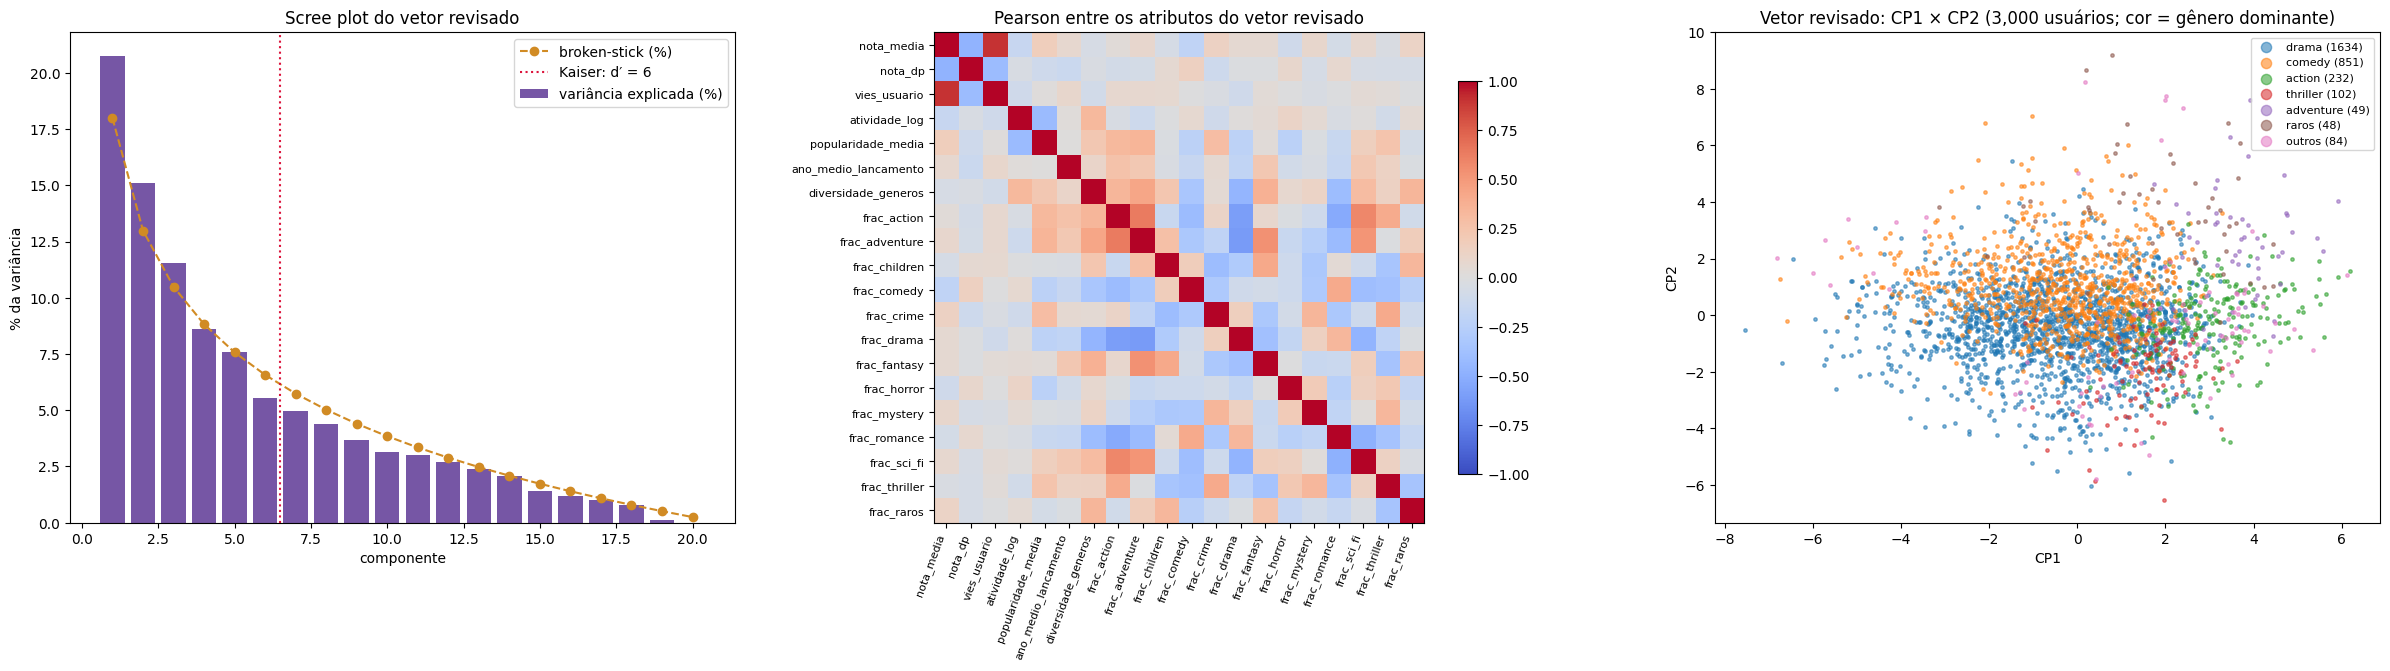

In [42]:
# [3.8-b] Vetor base × vetor revisado: PCA, concentração de distâncias, dimensionalidade, atípicos e tendência
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from scipy.spatial.distance import pdist
from scipy import stats

X_rev_original = perfil_rev_pd[atributos_rev].astype(float)
X_rev_padronizado = pd.DataFrame(StandardScaler().fit_transform(X_rev_original), columns=atributos_rev, index=perfil_pd.index)
pca_rev = PCA(svd_solver="full").fit(X_rev_padronizado)
autovalores_rev = pca_rev.explained_variance_
variancia_rev = 100 * pca_rev.explained_variance_ratio_
n_atr = len(atributos_rev)
broken_rev = 100 * np.array([sum(1.0 / j for j in range(i, n_atr + 1)) / n_atr for i in range(1, n_atr + 1)])
d_rev = int((autovalores_rev >= 1).sum())
d_broken_rev = int(np.argmax(variancia_rev <= broken_rev)) if (variancia_rev <= broken_rev).any() else n_atr
d_80_rev = int(np.searchsorted(np.cumsum(variancia_rev), 80) + 1)
X_rev_pca = pd.DataFrame(pca_rev.transform(X_rev_padronizado)[:, :d_rev],
                         columns=[f"CP{k}" for k in range(1, d_rev + 1)], index=perfil_pd.index)
print(f"PCA do vetor revisado: d′ = {d_rev} (Kaiser-Guttman, {np.cumsum(variancia_rev)[d_rev - 1]:.2f}% da variância); "
      f"broken-stick = {d_broken_rev}; 80% da variância = {d_80_rev}")
cargas_rev = pd.DataFrame(pca_rev.components_[:d_rev].T, index=atributos_rev, columns=X_rev_pca.columns)
for cp in cargas_rev.columns:
    principais = cargas_rev[cp].abs().sort_values(ascending=False).head(4).index
    print(f"  {cp} ({variancia_rev[int(cp[2:]) - 1]:.2f}%): " + ", ".join(f"{a} ({cargas_rev.loc[a, cp]:+.2f})" for a in principais))


def atipicos_no_espaco(X):
    """Mesma regra de 3.7-a: Mahalanobis² acima do quantil 0,999 da χ² e distância ao 10º vizinho acima do percentil 99."""
    X = np.asarray(X, dtype=float)
    centrado = X - X.mean(axis=0)
    d2 = (centrado ** 2 / centrado.var(axis=0)).sum(axis=1)
    dist_k10 = NearestNeighbors(n_neighbors=K_VIZ + 1, n_jobs=-1).fit(X).kneighbors(X)[0][:, K_VIZ]
    return (d2 > stats.chi2.ppf(0.999, df=X.shape[1])) & (dist_k10 > np.quantile(dist_k10, 0.99))


perfil_rev_pd["atipico_rev"] = atipicos_no_espaco(X_rev_pca)
espacos_comparacao = [
    ("base", "z-score", X_p1_padronizado, np.nan, np.nan),
    ("base", "PCA", X_p1_pca, 100 * acumulada[d_pca - 1], int(perfil_pd["atipico"].sum())),
    ("revisado", "z-score", X_rev_padronizado, np.nan, np.nan),
    ("revisado", "PCA", X_rev_pca, np.cumsum(variancia_rev)[d_rev - 1], int(perfil_rev_pd["atipico_rev"].sum())),
]
linhas_comp = []
for vetor, espaco, X, var_retida, n_atipicos in espacos_comparacao:
    d = pdist(X.loc[idx_dist].to_numpy(), metric="euclidean")
    d = d[d > 0]
    id_media, _ = dimensao_intrinseca_mle(X.loc[idx_id].to_numpy())
    h_medio, h_dp, _, _ = hopkins(X.to_numpy(), "percentis 1–99")
    linhas_comp.append((vetor, espaco, X.shape[1], var_retida, (d.max() - d.min()) / d.min(), d.std() / d.mean(),
                        id_media, h_medio, n_atipicos))
tabela_comparacao = pd.DataFrame(linhas_comp, columns=["vetor", "espaço", "dimensões", "variância retida %",
                                                       "contraste relativo", "variância relativa", "ID (MLE)",
                                                       "Hopkins (1–99)", "atípicos"])
print("\nComparação nas mesmas amostras de 3.5 (2.000 usuários), 3.5-b (10.000) e 3.7 (Hopkins, m = 1.000, 10 repetições):")
print(tabela_comparacao.round(4).to_string(index=False))
ambos = int((perfil_pd["atipico"] & perfil_rev_pd["atipico_rev"]).sum())
uniao = int((perfil_pd["atipico"] | perfil_rev_pd["atipico_rev"]).sum())
print(f"Atípicos nos dois vetores: {ambos:,} (Jaccard = {ambos / uniao:.3f})")
print("Atributo dominante dos atípicos do vetor revisado:",
      X_rev_padronizado[perfil_rev_pd["atipico_rev"].to_numpy()].abs().idxmax(axis=1).value_counts().head(6).to_dict())

fig, axes = plt.subplots(1, 3, figsize=(24, 6.5))
pos = np.arange(1, n_atr + 1)
axes[0].bar(pos, variancia_rev, color="#7656a5", label="variância explicada (%)")
axes[0].plot(pos, broken_rev, "o--", color="#d18b24", label="broken-stick (%)")
axes[0].axvline(d_rev + 0.5, color="crimson", ls=":", label=f"Kaiser: d′ = {d_rev}")
axes[0].set(title="Scree plot do vetor revisado", xlabel="componente", ylabel="% da variância")
axes[0].legend()
imagem = axes[1].imshow(pearson_rev.loc[atributos_rev, atributos_rev], vmin=-1, vmax=1, cmap="coolwarm")
axes[1].set_xticks(range(n_atr), atributos_rev, rotation=70, ha="right", fontsize=8)
axes[1].set_yticks(range(n_atr), atributos_rev, fontsize=8)
axes[1].set_title("Pearson entre os atributos do vetor revisado")
fig.colorbar(imagem, ax=axes[1], shrink=.8)
dominante_vis = perfil_rev_pd.loc[idx_vis, "genero_dominante"]
principais_dom = dominante_vis.value_counts().head(6).index
for rotulo in list(principais_dom) + ["outros"]:
    mascara = (dominante_vis.isin(principais_dom) == False) if rotulo == "outros" else (dominante_vis == rotulo)
    pontos = X_rev_pca.loc[idx_vis][mascara.to_numpy()]
    axes[2].scatter(pontos["CP1"], pontos["CP2"], s=6, alpha=.55, label=f"{rotulo} ({mascara.sum()})")
axes[2].set(title=f"Vetor revisado: CP1 × CP2 ({len(idx_vis):,} usuários; cor = gênero dominante)", xlabel="CP1", ylabel="CP2")
axes[2].legend(markerscale=3, fontsize=8)
plt.tight_layout()
plt.show()

**Leitura dos resultados.**

- **PCA do vetor revisado:** 6 componentes por Kaiser-Guttman retêm 69,13% da variância, contra 7 componentes e 68,58% no vetor base. O broken-stick retém 3 componentes (contra 2), sinal de mais estrutura nos primeiros eixos.
- **Componentes:**
  - CP1 (20,8%): ação, aventura e ficção contra romance;
  - CP2 (15,1%): infantil e fantasia contra crime e suspense;
  - CP3 (11,6%): nota média e viés do usuário;
  - CP4 (8,6%): atividade contra popularidade, ou seja, usuários muito ativos veem filmes menos populares;
  - CP5: gêneros raros e horror;
  - CP6: ano médio dos filmes vistos.
- **Distâncias:** no espaço PCA, o contraste relativo cai de 92,79 para 63,45 e a variância relativa, de 0,425 para 0,368: as distâncias ficam um pouco mais concentradas no vetor revisado. O contraste relativo depende só do par mais próximo e do mais distante da amostra, por isso oscila mais; a variância relativa usa todos os pares.
- **Dimensionalidade intrínseca:** 6,4 no PCA revisado e 12,1 no z revisado, contra 7,1 e 13,3 no vetor base.
- **Atípicos:** 1.076 no vetor revisado, contra 1.409 no base (−24%). Só 401 são atípicos nos dois (Jaccard 0,19). No vetor revisado, os atípicos se concentram em horror (333 usuários).
- **Hopkins (domínio robusto):** 0,68 no PCA revisado e 0,77 no z revisado, contra 0,71 e 0,77 no base. A tendência de agrupamento continua moderada.

**Interpretação:** o vetor revisado guarda a mesma variância em menos dimensões, gera menos atípicos e acrescenta eixos interpretáveis (atividade, popularidade e época). As distâncias ficam um pouco mais concentradas, e a tendência de agrupamento fica próxima da do vetor base.

**Consequência:** o PCA do vetor revisado passa a ser a entrada principal de P1, pelos ganhos de representação: proporções que somam 1, sem `Unknown`, com atividade e popularidade. O vetor base fica como comparação, também para medir o efeito da concentração de distâncias um pouco maior.

### 3.9 Solução indexada para buscas por similaridade

P1 depende de buscas por similaridade: o DBSCAN faz buscas por abrangência (todos os vizinhos dentro de um raio), a escolha desse raio usa a distância ao k-ésimo vizinho, e o kNN busca os k mais próximos. Com 162.541 usuários, a varredura linear compara cada consulta com todos os objetos. A célula compara, nos quatro espaços candidatos:

- **varredura linear:** referência exata;
- **kd-tree e ball-tree:** índices exatos por particionamento do espaço;
- **pivôs:** pela desigualdade triangular, |d(q,p) − d(o,p)| ≤ d(q,o). Se esse limite inferior passa do raio, o objeto é descartado sem que a distância seja calculada. Os pivôs são escolhidos por variância máxima das distâncias e por seleção incremental;
- **HNSW:** índice aproximado baseado em grafo, avaliado pelo recall (fração dos 10 vizinhos verdadeiros recuperados).

Os tempos dependem da máquina, então a comparação vale entre métodos na mesma execução. A fração de distâncias evitadas pelos pivôs não depende da máquina.

Busca kNN (k = 10) e por abrangência (raio = mediana da distância ao 10º vizinho), 162,541 usuários; tempos em segundos neste ambiente:
          espaço                         método  construção (s)  kNN: 1000 consultas (s)  raio: 200 consultas (s)  recall@10
    base PCA (7)               varredura linear          0.0019                   0.5534                   0.0556     1.0000
    base PCA (7)                        kd-tree          0.2356                   0.2279                   0.0676     1.0000
    base PCA (7)                      ball-tree          0.3434                   4.7665                   0.2862     1.0000
    base PCA (7)  HNSW aproximado (efSearch=16)          9.1872                   0.0313                      NaN     0.9998
    base PCA (7)  HNSW aproximado (efSearch=64)          9.1872                   0.0840                      NaN     1.0000
    base PCA (7) HNSW aproximado (efSearch=256)          9.1872                   0.1972                      NaN 

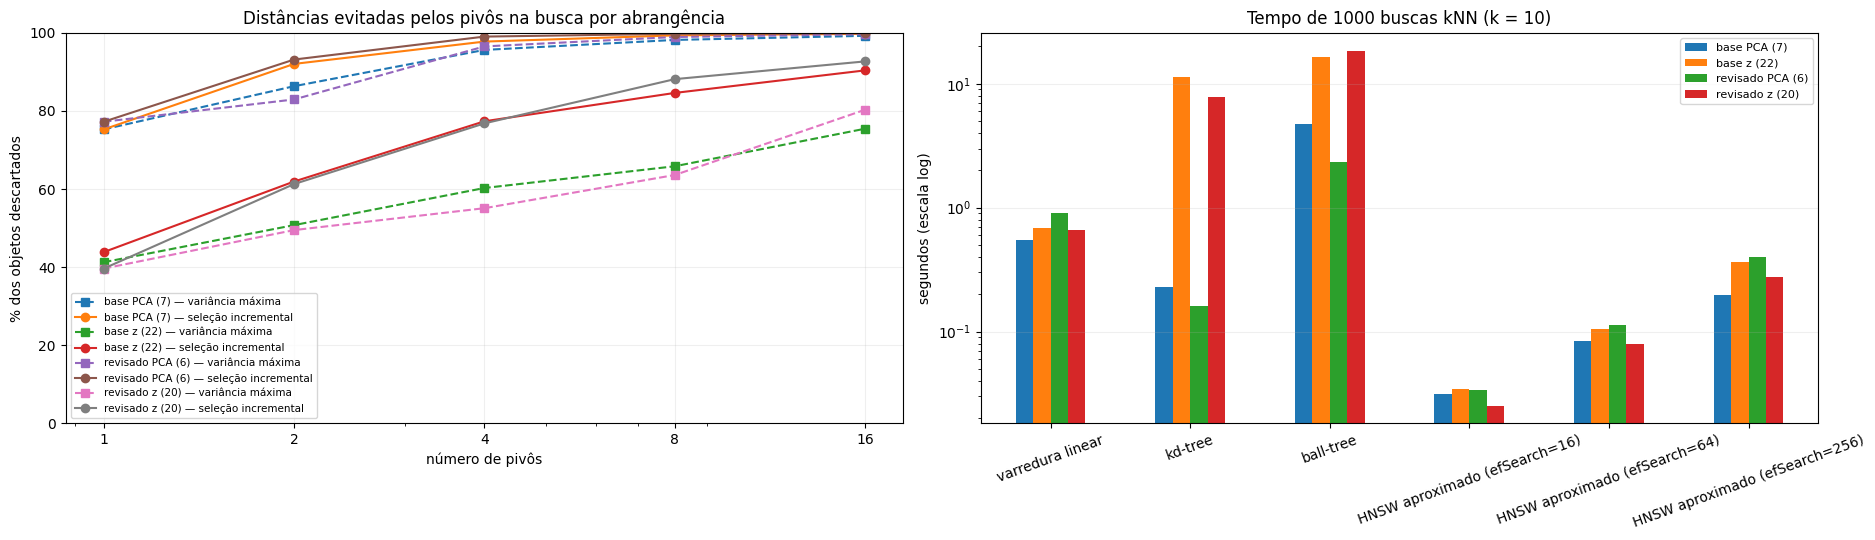

In [43]:
# [3.9] Solução indexada: varredura linear, kd-tree, ball-tree, pivôs e índice aproximado (HNSW)
import importlib.util, subprocess, sys, time
from scipy.spatial.distance import cdist
from sklearn.neighbors import NearestNeighbors

if importlib.util.find_spec("faiss") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "faiss-cpu"], check=False)
try:
    import faiss
except ImportError:
    faiss = None
    print("faiss indisponível: o índice aproximado (HNSW) não será medido.")

K_INDICE, N_CONSULTAS_KNN, N_CONSULTAS_RAIO, N_CONSULTAS_PIVO, P_MAX = 10, 1000, 200, 100, 16
espacos_indice = {
    f"base PCA ({X_p1_pca.shape[1]})": X_p1_pca.to_numpy(),
    f"base z ({X_p1_padronizado.shape[1]})": X_p1_padronizado.to_numpy(),
    f"revisado PCA ({X_rev_pca.shape[1]})": X_rev_pca.to_numpy(),
    f"revisado z ({X_rev_padronizado.shape[1]})": X_rev_padronizado.to_numpy(),
}
rng_indice = np.random.default_rng(7)
consultas_idx = rng_indice.choice(len(perfil_pd), size=N_CONSULTAS_KNN, replace=False)


def cronometrar(funcao):
    inicio = time.perf_counter()
    resultado = funcao()
    return resultado, time.perf_counter() - inicio


linhas_indice, linhas_pivos, raios = [], [], {}
for nome, X in espacos_indice.items():
    X = np.ascontiguousarray(X, dtype=np.float64)
    X_consulta, X_raio = X[consultas_idx], X[consultas_idx[:N_CONSULTAS_RAIO]]
    # Varredura linear: compara a consulta com todos os objetos; é a referência exata.
    nn_linear, t_constr = cronometrar(lambda: NearestNeighbors(n_neighbors=K_INDICE + 1, algorithm="brute").fit(X))
    (dist_exata, _), t_knn = cronometrar(lambda: nn_linear.kneighbors(X_consulta))
    raio = float(np.median(dist_exata[:, K_INDICE]))  # raio da busca por abrangência = mediana da distância ao 10º vizinho
    raios[nome] = raio
    limite_k = dist_exata[:, [K_INDICE]] + 1e-6
    vizinhos_raio, t_raio = cronometrar(lambda: nn_linear.radius_neighbors(X_raio, radius=raio, return_distance=False))
    linhas_indice.append((nome, "varredura linear", t_constr, t_knn, t_raio, 1.0))
    for algoritmo in ("kd_tree", "ball_tree"):
        nn_arvore, t_constr = cronometrar(lambda: NearestNeighbors(n_neighbors=K_INDICE + 1, algorithm=algoritmo).fit(X))
        (dist_arvore, _), t_knn = cronometrar(lambda: nn_arvore.kneighbors(X_consulta))
        _, t_raio = cronometrar(lambda: nn_arvore.radius_neighbors(X_raio, radius=raio, return_distance=False))
        recall = float(np.mean(dist_arvore[:, 1:] <= limite_k))
        linhas_indice.append((nome, algoritmo.replace("_", "-"), t_constr, t_knn, t_raio, recall))
    if faiss is not None:
        X32 = np.ascontiguousarray(X, dtype=np.float32)
        indice_hnsw = faiss.IndexHNSWFlat(X32.shape[1], 32)
        indice_hnsw.hnsw.efConstruction = 40
        _, t_constr = cronometrar(lambda: indice_hnsw.add(X32))
        for ef in (16, 64, 256):
            indice_hnsw.hnsw.efSearch = ef
            (dist_hnsw, _), t_knn = cronometrar(lambda: indice_hnsw.search(X32[consultas_idx], K_INDICE + 1))
            dist_hnsw = np.sqrt(np.maximum(dist_hnsw, 0.0))  # o faiss devolve a distância ao quadrado
            recall = float(np.mean(dist_hnsw[:, 1:] <= limite_k + 1e-4))
            linhas_indice.append((nome, f"HNSW aproximado (efSearch={ef})", t_constr, t_knn, np.nan, recall))

    # Pivôs: |d(q,p) − d(o,p)| ≤ d(q,o) pela desigualdade triangular; se o limite inferior passa do raio, o objeto
    # é descartado sem calcular d(q,o).
    candidatos = rng_indice.choice(len(X), size=200, replace=False)
    a, b = rng_indice.choice(len(X), size=3000), rng_indice.choice(len(X), size=3000)
    dist_a, dist_b = cdist(X[a], X[candidatos]), cdist(X[b], X[candidatos])
    validos = np.linalg.norm(X[a] - X[b], axis=1) > 0
    limite_inferior_cand = np.abs(dist_a - dist_b)[validos]
    pivos_variancia = candidatos[np.argsort(dist_a.var(axis=0))[::-1][:P_MAX]]  # variância máxima das distâncias
    escolhidos, limite_atual = [], np.zeros(limite_inferior_cand.shape[0])
    for _ in range(P_MAX):  # seleção incremental: cada novo pivô maximiza o limite inferior médio dos pares
        ganho = np.maximum(limite_atual[:, None], limite_inferior_cand).mean(axis=0)
        ganho[escolhidos] = -np.inf
        j = int(np.argmax(ganho))
        escolhidos.append(j)
        limite_atual = np.maximum(limite_atual, limite_inferior_cand[:, j])
    pivos_incremental = candidatos[escolhidos]
    for estrategia, pivos in (("variância máxima", pivos_variancia), ("seleção incremental", pivos_incremental)):
        dist_objetos = cdist(X, X[pivos])  # N × P: calculado uma única vez, na construção do índice
        dist_consultas = cdist(X[consultas_idx[:N_CONSULTAS_PIVO]], X[pivos])
        descartados = np.zeros(P_MAX)
        for linha in dist_consultas:
            limite = np.maximum.accumulate(np.abs(dist_objetos - linha), axis=1)
            descartados += (limite > raio).mean(axis=0)
        descartados /= len(dist_consultas)
        for p in (1, 2, 4, 8, 16):
            linhas_pivos.append((nome, estrategia, p, 100 * descartados[p - 1]))

tabela_indice = pd.DataFrame(linhas_indice, columns=["espaço", "método", "construção (s)",
                                                     f"kNN: {N_CONSULTAS_KNN} consultas (s)",
                                                     f"raio: {N_CONSULTAS_RAIO} consultas (s)", "recall@10"])
tabela_pivos = pd.DataFrame(linhas_pivos, columns=["espaço", "estratégia", "pivôs", "% de distâncias evitadas"])
print(f"Busca kNN (k = {K_INDICE}) e por abrangência (raio = mediana da distância ao 10º vizinho), "
      f"{len(perfil_pd):,} usuários; tempos em segundos neste ambiente:")
print(tabela_indice.round(4).to_string(index=False))
print("\nRaio da busca por abrangência em cada espaço:", {k: round(v, 4) for k, v in raios.items()})
print("\nFiltragem por pivôs (busca por abrangência; % dos objetos descartados pelo limite inferior):")
print(tabela_pivos.pivot_table(index=["espaço", "estratégia"], columns="pivôs",
                               values="% de distâncias evitadas").round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(19, 5.5))
for (nome, estrategia), parte in tabela_pivos.groupby(["espaço", "estratégia"], sort=False):
    axes[0].plot(parte["pivôs"], parte["% de distâncias evitadas"], "o-" if estrategia == "seleção incremental" else "s--",
                 label=f"{nome} — {estrategia}")
axes[0].set(title="Distâncias evitadas pelos pivôs na busca por abrangência", xlabel="número de pivôs",
            ylabel="% dos objetos descartados", xscale="log", ylim=(0, 100))
axes[0].set_xticks([1, 2, 4, 8, 16], ["1", "2", "4", "8", "16"])
axes[0].legend(fontsize=7.5)
axes[0].grid(alpha=.2)
tempos = tabela_indice.pivot_table(index="método", columns="espaço", values=f"kNN: {N_CONSULTAS_KNN} consultas (s)", sort=False)
tempos.plot.bar(ax=axes[1], logy=True, rot=20)
axes[1].set(title=f"Tempo de {N_CONSULTAS_KNN} buscas kNN (k = {K_INDICE})", ylabel="segundos (escala log)", xlabel="")
axes[1].legend(fontsize=8)
axes[1].grid(axis="y", alpha=.2)
plt.tight_layout()
plt.show()

**Leitura dos resultados.**

- **Espaços PCA (6 ou 7 dimensões):** a kd-tree é o índice exato mais rápido: 0,16 s para 1.000 buscas kNN no PCA revisado, contra 0,90 s da varredura linear. A ball-tree não ganha da varredura.
- **Espaços z (20 ou 22 dimensões):** as árvores ficam muito mais lentas que a varredura linear (kd-tree 7,8 a 11,3 s; ball-tree 16,5 a 18,5 s; varredura 0,7 s). É o efeito da dimensionalidade: os particionamentos deixam de descartar regiões.
- **HNSW:** 1.000 buscas em 0,025 a 0,035 s, com recall@10 de 0,98 a 1,00 já com efSearch = 16. O custo fica na construção (8 a 12 s).
- **Pivôs:** com 16 pivôs de seleção incremental, a busca por abrangência descarta 99,9% das distâncias no PCA revisado e 99,8% no PCA base, contra 92,7% e 90,4% nos espaços z. A seleção incremental supera a de variância máxima, sobretudo com poucos pivôs: com 2 pivôs no z revisado, 61,3% contra 49,5%.

**Limitação:** os tempos dependem da máquina (Colab gratuito); a fração de distâncias evitadas não.

**Consequência:** P1 usa o espaço PCA, onde os índices funcionam. As buscas exatas (DBSCAN e distância ao k-ésimo vizinho) usam kd-tree ou pivôs com seleção incremental, e o HNSW atende buscas aproximadas.

### 3.10 Resultado da transformação e entrada de P1

| Objeto | Conteúdo | Uso em P1 |
|---|---|---|
| `perfil_pd` | `userId`, `n_avaliacoes` e 24 atributos derivados | identificar e descrever os grupos |
| `X_p1_padronizado` | 22 atributos (média, DP e 20 proporções de gênero), z-score | entrada candidata interpretável |
| `X_p1_minmax` | os mesmos 22 atributos em [0, 1] | alternativa de escala |
| `X_p1_pca` | 7 componentes principais (critério de Kaiser-Guttman) | entrada candidata com dimensionalidade reduzida |
| `perfil_pd["atipico"]` | 1.409 usuários longe do centro e isolados dos vizinhos (3.7) | executar P1 com e sem esses usuários |
| `perfil_rev_pd` | atributos derivados, proporções fracionárias, gênero dominante e `atipico_rev` (1.076 usuários) | descrever os grupos do vetor revisado |
| `X_rev_padronizado` | 20 atributos do vetor revisado, z-score | entrada alternativa interpretável |
| `X_rev_pca` | 6 componentes do vetor revisado (Kaiser-Guttman, 69,13%) | **entrada principal de P1** |

**Resultados desta execução:**

- **Seleção de características:** apenas `nota_media × prop_positivas` atingiu o limiar de redundância (Pearson 0,922; Spearman 0,946). O segundo par mais associado, `prop_animation × prop_children` (0,823 / 0,804), ficou abaixo do limiar, então os dois atributos foram mantidos.
- **Escalas:**
  - no z-score, cada atributo tem o mesmo peso na variância total (4,55%), mas gêneros raros geram valores extremos: máximos de 60,7 em Unknown, 47,2 em Documentary e 38,9 em Western;
  - no min-max, os gêneros mais frequentes dominam a distância: Action pesa 11,52% e Drama 10,10%, contra 0,23% de Documentary.
- **PCA:**
  - d′ = 7 por Kaiser-Guttman (68,58% da variância);
  - d′ = 2 por broken-stick;
  - d′ = 10 para 80% da variância acumulada.
  - Os dois primeiros componentes explicam 37,87% e opõem, respectivamente, perfis infantis/fantasia e ação/ficção científica contra romance/comédia.
- **Concentração de distâncias** (2.000 usuários, distância euclidiana):

  | Espaço | Contraste relativo | Variância relativa |
  |---|---:|---:|
  | z-score, 22 atributos | 42,31 | 0,3865 |
  | min-max, 22 atributos | 24,55 | 0,3473 |
  | PCA, 7 componentes | 92,79 | 0,4250 |

  O espaço PCA foi o que menos concentrou as distâncias e o min-max, o que mais concentrou.

- **Dimensionalidade intrínseca:** cerca de 13 no espaço z de 22 atributos. As projeções 2D mostram uma nuvem contínua, sem grupos isolados.
- **Valores atípicos:** 1.409 usuários (0,87%) estão longe do centro e isolados; em geral, têm poucas avaliações concentradas em gêneros raros (Unknown, Documentary, Western e Film-Noir). Foram mantidos e marcados.
- **Tendência de agrupamento:** estatística de Hopkins de 0,715 (PCA) e 0,766 (z-score) no domínio robusto, contra 0,500 nos dados uniformes de controle. Os usuários são mais concentrados que dados uniformes, mas a tendência é moderada.
- **Vetor revisado (3.8):** proporções fracionárias, gêneros raros agrupados, sem `Unknown` e com cinco atributos derivados. Retém a mesma variância em 6 componentes, tem 24% menos atípicos (1.076) e Hopkins de 0,68 no PCA, com distâncias um pouco mais concentradas.
- **Solução indexada (3.9):** no espaço PCA, a kd-tree faz 1.000 buscas kNN em 0,16 s (varredura: 0,90 s), 16 pivôs descartam 99,9% das distâncias e o HNSW chega a recall de 100%. Nos espaços z, as árvores ficam mais lentas que a varredura.

**Consequência para P1:** a entrada principal é `X_rev_pca`, o PCA do vetor revisado. Ele guarda a mesma variância em menos dimensões, gera menos atípicos e não depende de `Unknown` nem da contagem dupla de gêneros. O PCA do vetor base e as matrizes z-score ficam como comparação. As buscas de vizinhos usam kd-tree ou pivôs no espaço PCA, e HNSW quando uma resposta aproximada basta. P1 deve ser executado com e sem os usuários atípicos, e seus índices devem ser comparados com os de partições de dados uniformes.

## Estado da análise

| Etapa | Situação |
|---|---|
| 0. Problema e tarefa | definido: P1 agrupamento → P2 associação; sem classe |
| 1. Seleção | concluída: estrutura, tipos, exploração univariada com histogramas de todos os atributos (incluindo tempo e distribuição dos gêneros), consultas por gênero, por objeto e com filtro, exploração multivariada em escala [0, 1] e testes estatísticos |
| 2. Pré-processamento | concluído: auditoria, limpeza (nenhuma avaliação removida), integração, imputação do gênero dos filmes sem gênero, verificação de amostragem, valores ausentes da matriz usuário × filme (sem imputação) e distribuições depois do tratamento |
| 3. Transformação | concluída: perfil por usuário, seleção de características, z-score × min-max, PCA (d′ = 7), concentração de distâncias, dimensionalidade intrínseca, projeções 2D, valores atípicos, tendência de agrupamento, vetor revisado (PCA com d′ = 6, entrada principal de P1) e solução indexada |